# Ćwiczenie O18 — Bodo: notebook pomiarowy
## Badanie zjawiska dyfrakcji i interferencji światła laserowego

Notebook do **zbierania danych** skanerem PASCO Wireless Diffraction Scanner (OS-8441) przez Bluetooth
z użyciem biblioteki [`pasco`](https://pypi.org/project/pasco/). To **nie jest** notebook obliczeniowy —
służy do akwizycji, zapisu surowych danych do CSV i szybkiego podglądu w laboratorium
(czy obraz jest symetryczny, czy nie jest nasycony, czy położenia minimów mają sensowny rząd wielkości).
Właściwa analiza (dopasowania, niepewności) pójdzie do `bodo.ipynb`.

Notebook idzie **po kolei, komórka po komórce** — żadnej nie trzeba pomijać. Najpierw wszystkie pomiary laserem
czerwonym (części A–C wykonano 27 października, części D i E — zmiana odległości i apertury — 3 listopada),
na końcu laser zielony. Laser przełącza komórka `ustaw_laser(...)` na początku każdego bloku: wybiera długość fali
i katalog na dane (`red/` albo `green/`). Zestaw szczelin ten sam (tarcza PASCO OS-8442).

Skrypt (`o18.pdf`) opisuje starszy układ z silnikiem krokowym i programem ACQUIS. Tutaj zamiast niego
skaner przesuwa się ręcznie: enkoder obrotowy mierzy położenie $x$, a czujnik światła natężenie $I$.
Jeden skan = **jeden przejazd przez całą oś**: od jednego końca do drugiego, powoli i równo.
Pomiar kończy się sam, gdy na końcu osi skaner zacznie się cofać — zawrót jest sygnałem końca.
Każdy układ szczelin (części A–C) mierzy się **3 razy**: trzy przejazdy tam i z powrotem w jednej komórce.
Części D (zmiana odległości, trzy położenia szczelin) i E (zmiana apertury, dwie apertury) to pojedyncze przejazdy.

### Plan pomiarów (skrypt §4.12.2 i Dodatek B, `o18_b.pdf`)

Kolejność pomiarów (każdy wiersz to jeden blok komórek, w tej kolejności w notebooku):

| blok | laser | układ | szczeliny (producent) | cel |
|---|---|---|---|---|
| tło | czerwony | laser zasłonięty | — | tło $I_\text{tło}$ |
| A | czerwony | pojedyncza szczelina, cztery | $a = 0{,}02;\ 0{,}04;\ 0{,}08;\ 0{,}16$ mm | szerokość $a$; wpływ $a$ na obraz |
| B | czerwony | dwie szczeliny, wszystkie zestawy | $a \in \{0{,}04;\ 0{,}08\}$ mm × $d \in \{0{,}25;\ 0{,}50\}$ mm | szerokość $a$ i odległość $d$ |
| C | czerwony | $N = 2, 3, 4, 5$ szczelin | $a = 0{,}04$ mm, $d = 0{,}125$ mm | obserwacja: szerokość i natężenie maksimów głównych, liczba maksimów pobocznych |
| D | czerwony | pojedyncza szczelina, trzy inne odległości $D$ | $a = 0{,}02$ mm | skalowanie obrazu z $D$; po jednym przejeździe |
| E | czerwony | pojedyncza szczelina, dwie inne apertury czujnika | $a = 0{,}04$ mm | wpływ apertury na obraz; po jednym przejeździe |
| tło | zielony | laser zasłonięty | — | tło $I_\text{tło}$ |
| A | zielony | pojedyncza szczelina, dwie | $a = 0{,}04;\ 0{,}08$ mm | jak wyżej; szerokości zalecane w Dodatku B |
| B | zielony | dwie szczeliny, dwie odległości | $a = 0{,}08$ mm, $d \in \{0{,}25;\ 0{,}50\}$ mm | jak wyżej |
| C | zielony | $N = 4$ szczeliny | $a = 0{,}04$ mm, $d = 0{,}125$ mm | jak wyżej; $N = 4$ jest też w serii czerwonej |

Szczeliny według opisu na tarczy OS-8442 ($a$ — szerokość szczeliny, $d$ — odległość między szczelinami, w mm).
Zielony B na $a = 0{,}08$ mm: węższa obwiednia, więc więcej minimów obwiedni w zakresie skanera, i jaśniejszy obraz
(czerwonym $I_\text{max} \approx 60\,\%$ wobec $\approx 40\,\%$ dla $a = 0{,}04$ mm).

Stałe: $\lambda$ zależnie od lasera (konfiguracja niżej), $D = (900 \pm 14)$ mm z położeń na ławie
(szczeliny $20 \pm 1$ cm, detektor $110 \pm 1$ cm). Obie metody analizy wymagają $\lambda$ i $D$; obie wartości
są zapisywane w rejestrze przy każdym skanie.

**Wzory** (pole dalekie, $D \gg d$; $\sin\theta \approx \operatorname{tg}\theta = y/D$, gdzie $y = x - x_0$ — położenie
względem środka obrazu):

- pojedyncza szczelina: $I = I_\text{max}\left[\dfrac{\sin(\pi a y/\lambda D)}{\pi a y/\lambda D}\right]^2$,
  minima $y_m = \dfrac{\lambda D}{a}\,m$ ($m = \pm1, \pm2, \dots$);
- dwie szczeliny: $I = I_\text{max}\cos^2\!\left(\dfrac{\pi d}{\lambda D}y\right)\left[\dfrac{\sin(\pi a y/\lambda D)}{\pi a y/\lambda D}\right]^2$,
  minima obwiedni $y_\text{dyf} = \dfrac{\lambda D}{a}\,m$, maksima interferencyjne $y_\text{int} = \dfrac{\lambda D}{d}\,m'$;
- $N$ szczelin: $I = I_\text{max}\left[\dfrac{\sin(\pi N d y/\lambda D)}{\sin(\pi d y/\lambda D)}\right]^2
  \left[\dfrac{\sin(\pi a y/\lambda D)}{\pi a y/\lambda D}\right]^2$ — między maksimami głównymi $N-2$ maksimów pobocznych.

### Przed każdym skanem

1. Na ekranie ustawić ostry, symetryczny obraz dyfrakcyjny, potem usunąć ekran.
2. Sprawdzić, czy szczeliny i detektor stoją nadal na 20 i 110 cm (inaczej poprawić `POS_*` w konfiguracji).
3. Dobrać szczelinę wejściową czujnika (jeśli jest wybierana) i czułość tak, żeby maksimum centralne
   **nie przekraczało ~95 %** — podgląd ostrzega przed nasyceniem. Zanotować wybraną szczelinę wejściową.
4. Zgasić / zasłonić światło w pobliżu (tło dodaje się do $I$; lepiej je zmierzyć niż zgadywać — patrz pomiar tła).
5. Ustawić skaner na jednym końcu osi, po starcie komórki przejść korbką **pełen zakres** do drugiego końca,
   kręcąc **jak najwolniej i równo**, i tam zawrócić (koniec pomiaru) — im wolniej, tym gęściej leżą punkty.
   Odczyt przez BLE jest wolniejszy niż w Capstone (~8 zamiast 100 pkt/s), a położenie i natężenie są odczytywane
   po kolei, więc przy szybkim ruchu punkty $x$ i $I$ się rozjeżdżają. Pasek statusu nad wykresem na żywo mówi,
   czy tempo i zasięg są w porządku (szczegóły niżej, przy `skanuj`).

### Biblioteki

Biblioteka `pasco` wymaga Pythona ≥ 3.14 i instaluje `bleak` (BLE). Przy pierwszym połączeniu macOS zapyta
o zgodę na Bluetooth dla terminala / VS Code.

In [ ]:
# %pip install pasco

In [25]:
import time
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from IPython.display import display, HTML

import locale

plt.rcParams.update({'figure.dpi': 150, 'font.size': 11, 'axes.grid': True, 'grid.alpha': 0.3})

# przecinek dziesiętny na osiach wykresów (jak w sprawozdaniu)
locale.setlocale(locale.LC_NUMERIC, 'pl_PL.UTF-8')
plt.rcParams['axes.formatter.use_locale'] = True

def pl(x, spec):
    '''Liczba sformatowana z przecinkiem dziesiętnym — do legend i opisów na wykresach.'''
    return format(x, spec).replace('.', ',')

### Konfiguracja

`DEVICE_ID` — 6-cyfrowy numer z obudowy skanera (format `123-456`). Ustawienie `None` uruchamia
**symulator** (rozkład z wzoru 4.12.20 z szumem), żeby przetestować notebook bez sprzętu.
Pliki symulowane dostają przedrostek `sim_`, więc nie pomieszają się z prawdziwymi danymi.

`LASERY` — długości fal obu laserów. Lasera nie wybiera się tutaj: robi to `ustaw_laser('red')` /
`ustaw_laser('green')` na początku bloku pomiarów danym laserem. Funkcja ustawia długość fali
i katalog na dane: `red/` albo `green/`, każdy z własnym rejestrem `scans.csv`. Te same nazwy plików
w obu katalogach ułatwiają potem porównanie laserów w analizie. Długość fali sprawdzić na tabliczce lasera
lub u prowadzącego: dla czerwonego skrypt podaje $(640 \pm 10)$ nm, ale dotyczy starszego układu; zielony ma
515 nm według tabliczki lasera.

Położenia na ławie optycznej (odczyt ze skali, $\pm 1$ cm): szczeliny 20 cm, detektor 110 cm, więc
$D = 900$ mm i $u_D = \sqrt{u_\text{szcz}^2 + u_\text{det}^2} \approx 14$ mm. $D$ jest wspólne dla wszystkich
pomiarów poza częścią D (tam położenie szczelin podaje się w komórce); jeśli w trakcie przesunie się uchwyt, zmienić `POS_*` tutaj i ponownie uruchomić komórkę (wartość
trafia do rejestru przy każdym skanie). Względna niepewność $u_D/D \approx 1{,}6\,\%$ jest tego samego rzędu co
$u_\lambda/\lambda$ dla lasera czerwonego, więc obie wejdą do niepewności $a$ i $d$ z podobną wagą.

In [26]:
DEVICE_ID = '565-514'      # numer z obudowy; None = symulator

# długość fali i niepewność [mm], źródło
LASERY = {
    'red':   (650e-6, 5e-6,  'tabliczka lasera PASCO; u — typowa tolerancja diody'),
    'green': (515e-6, 5e-6,  'tabliczka lasera PASCO; u — typowa tolerancja diody'),
}

# położenia na ławie optycznej [mm] i niepewność odczytu
POS_SZCZELINY, POS_DETEKTOR, U_POS = 200.0, 1100.0, 10.0
D_UST = POS_DETEKTOR - POS_SZCZELINY
U_D = np.hypot(U_POS, U_POS)


def ustaw_laser(laser):
    '''Długość fali i katalog na dane dla lasera: surowe skany <laser>/<nazwa>.csv, rejestr <laser>/scans.csv.'''
    global LASER, LAMBDA, U_LAMBDA, ZRODLO_LAMBDA, DATA_DIR, LOG_FILE
    LASER = laser
    LAMBDA, U_LAMBDA, ZRODLO_LAMBDA = LASERY[laser]
    DATA_DIR = Path(laser)
    DATA_DIR.mkdir(exist_ok=True)
    LOG_FILE = DATA_DIR / (('sim_' if DEVICE_ID is None else '') + 'scans.csv')
    print(f'laser: {LASER}, λ = ({LAMBDA * 1e6:.0f} ± {U_LAMBDA * 1e6:.0f}) nm  [{ZRODLO_LAMBDA}]')
    print(f'D = ({D_UST:.0f} ± {U_D:.0f}) mm,  dane → {DATA_DIR}/')


ustaw_laser('red')         # do testu odczytu; właściwe przełączenie na początku każdego bloku

laser: red, λ = (640 ± 10) nm  [skrypt O18 — sprawdzić tabliczkę lasera]
D = (900 ± 14) mm,  dane → red/


### Obsługa skanera

Biblioteka `pasco` uruchamia własną pętlę `asyncio` (`run_until_complete`), a w Jupyterze pętla jądra
już działa — wywołanie wprost z komórki kończy się `RuntimeError`. Dlatego całe urządzenie żyje w jednym
osobnym wątku (`ThreadPoolExecutor(max_workers=1)`), a komórki tylko zlecają mu odczyty.

Odczyt jest na żądanie (polling): każdy punkt to zapytanie o położenie i o natężenie. Biblioteka podaje
położenie w jednostce z datasheetu (`m`), tutaj jest przeliczane na mm.

**Start enkodera.** Położenie to suma przyrostów licznika enkodera obrotowego (`RawCountChange`
× 0,01 m / 2000) z kolejnych odczytów. Biblioteka wysyła komendę uruchamiającą enkoder (`0x37 0x01 0x00`)
tylko czujnikowi *Rotary Motion*; skaner dyfrakcyjny ma taki sam enkoder, ale tej komendy nie dostaje,
przez co przyrosty są zerowe i $x \equiv 0$. Dlatego `Skaner` wysyła ją sam po połączeniu
(z limitem czasu na odpowiedź). `licznik()` zwraca surowe wartości kanału położenia do diagnostyki.

**Rozdzielczość.** Biblioteka zaokrągla każdy wynik do `Precision` z datasheetu w jednostce bazowej:
`Position` do 2 miejsc w metrach (krok **1 cm**), `LightIntensity` do 0,1 %. Suma impulsów enkodera jest
przechowywana bez zaokrąglenia, więc po podniesieniu `Precision` położenie ma rozdzielczość enkodera
$0{,}01\ \text{m}/2000 = 5\ \mu\text{m}$, a natężenie $\approx 0{,}0015\,\%$ (krok przetwornika).
Rozdzielczość to nie dokładność — skalę $x$ sprawdzić przejazdem o znaną odległość (test odczytu).

In [27]:
MEAS_X = 'Position'
MEAS_I = 'LightIntensity'


class Skaner:
    '''PASCO Wireless Diffraction Scanner obsługiwany w osobnym wątku.'''

    def __init__(self, device_id):
        self._ex = ThreadPoolExecutor(max_workers=1)
        self._dev = self._call(self._polacz, device_id)
        meas = self._call(self._dev.get_measurement_list)
        print('dostępne pomiary:', meas)
        for m in (MEAS_X, MEAS_I):
            if m not in meas:
                raise RuntimeError(f'brak pomiaru {m!r} — sprawdź nazwy powyżej i popraw MEAS_X / MEAS_I')
        self.unit_x = self._call(self._dev.get_measurement_unit, MEAS_X)
        self.unit_I = self._call(self._dev.get_measurement_unit, MEAS_I)
        print(f'jednostki: x [{self.unit_x}], I [{self.unit_I}]')
        self._skala_x = {'m': 1e3, 'mm': 1.0, 'cm': 10.0}[self.unit_x]

    def _call(self, f, *args):
        return self._ex.submit(f, *args).result()

    @staticmethod
    def _polacz(device_id):
        import asyncio
        from pasco import PASCOBLEDevice
        dev = PASCOBLEDevice()
        dev.connect_by_id(device_id)
        if dev._dev_type != 'Rotary Motion':  # Rotary Motion dostaje start z biblioteki
            start = dev.write_await_callback(dev.SENSOR_SERVICE_ID, dev.WIRELESS_RMS_START)
            try:
                dev._loop.run_until_complete(asyncio.wait_for(start, timeout=3))
                print('enkoder: wysłano komendę startu')
            except TimeoutError:
                print('enkoder: brak odpowiedzi na komendę startu (3 s) — sprawdź x w teście odczytu')
        # biblioteka zaokrągla wynik do Precision z datasheetu (Position: 0,01 m, LightIntensity: 0,1 %);
        # surowa rozdzielczość to 0,01 m / 2000 imp. = 5 µm i ≈ 0,0015 % — zaokrąglenie wyłączone
        for kanal in dev._device_measurements.values():
            for m in kanal.values():
                if m['NameTag'] in (MEAS_X, MEAS_I) and 'Precision' in m:
                    m['Precision'] = 9
        return dev

    def odczyt(self):
        '''Zwraca (x [mm], I [%]).'''
        d = self._call(self._dev.read_data_list, [MEAS_X, MEAS_I])
        return d[MEAS_X] * self._skala_x, d[MEAS_I]

    def licznik(self):
        '''Surowe wartości kanału położenia po ostatnim odczycie, {ID pomiaru: wartość}.'''
        sid = self._dev._measurement_sensor_ids[MEAS_X]
        return self._call(lambda: dict(self._dev._sensor_data[sid]))

    def rozlacz(self):
        self._call(self._dev.disconnect)
        self._ex.shutdown()


class SymulowanySkaner:
    '''Zamiennik skanera do testów: x przesuwa się sinusoidalnie, I z wzoru 4.12.20.'''

    unit_x, unit_I = 'mm', '%'

    def __init__(self, zakres=20.0, okres=60.0, seed=0):
        self.zakres, self.okres = zakres, okres
        self.rng = np.random.default_rng(seed)
        self.N = None
        self.ustaw(N=1, a=0.08, d=None, D=800.0)

    def ustaw(self, N, a, d, D):
        if getattr(self, 'N', None) is not None and (self.N, self.a, self.d, self.D) == (N, a, d, D):
            return  # ten sam układ (kolejny przejazd serii) — ruch trwa dalej
        self.N, self.a, self.d, self.D = N, a, d, D
        self.t0 = time.perf_counter()

    def odczyt(self):
        time.sleep(0.03)  # mniej więcej czas jednego zapytania BLE
        t = time.perf_counter() - self.t0
        x = 0.7 - self.zakres * np.cos(2 * np.pi * t / self.okres)  # start na lewym końcu
        s = (x - 0.7) / np.hypot(x - 0.7, self.D)
        I = 90 * model_I(s, self.N, self.a, self.d) + 0.4
        I += self.rng.normal(0, 0.3 + 0.01 * I)
        return x, float(np.clip(I, 0, 100))

    def licznik(self):
        return {}

    def rozlacz(self):
        pass


def model_I(sin_theta, N, a, d):
    '''Wzór 4.12.20 znormalizowany do 1 w maksimum centralnym; a, d w mm.'''
    beta = np.pi * a * sin_theta / LAMBDA
    dyfr = np.sinc(beta / np.pi) ** 2
    if N == 1:
        return dyfr
    phi = np.pi * d * sin_theta / LAMBDA
    with np.errstate(invalid='ignore', divide='ignore'):
        interf = np.where(np.abs(np.sin(phi)) < 1e-9, N**2, (np.sin(N * phi) / np.sin(phi)) ** 2)
    return interf / N**2 * dyfr

In [29]:
skaner = Skaner(DEVICE_ID) if DEVICE_ID else SymulowanySkaner()
SIM = DEVICE_ID is None
print('SYMULATOR' if SIM else f'połączono ze skanerem {DEVICE_ID}')

enkoder: wysłano komendę startu
dostępne pomiary: ['Position', 'LightIntensity', 'LogLightIntensity']
jednostki: x [m], I [percent]
połączono ze skanerem 565-514


### Test odczytu

Po uruchomieniu komórki **przez ~5 s przesuwać skaner ręką** tam i z powrotem i zasłonić na chwilę laser:
$x$ powinno się zmieniać, a $I$ spadać przy zasłonięciu. Obok $x$ wypisywane są surowe wartości kanału położenia
(`{0: przyrost licznika, 1: położenie [m]}`) — jeśli przyrost jest stale 0 mimo ruchu, enkoder nie liczy.
Warto też raz przesunąć skaner o znaną odległość (np. 10 mm na linijce) i porównać z odczytem enkodera —
to sprawdza skalę $x$.

In [5]:
xs = []
t0 = time.perf_counter()
while time.perf_counter() - t0 < 5:
    x, I = skaner.odczyt()
    xs.append(x)
    print(f'x = {x:8.3f} mm   I = {I:6.2f} %   surowe: {skaner.licznik()}')
dt = (time.perf_counter() - t0) / len(xs)
print(f'czas jednego odczytu ≈ {dt * 1e3:.0f} ms  (≈ {1 / dt:.0f} pkt/s)')
if np.ptp(xs) == 0:
    print(f'UWAGA: x stałe ({xs[0]} mm) przez 5 s — enkoder nie liczy (albo skaner nie był ruszany)')

x =    0.000 mm   I =   0.57 %   surowe: {0: 0, 1: 0.0}
x =    0.000 mm   I =   0.55 %   surowe: {0: 0, 1: 0.0}
x =    0.000 mm   I =   0.54 %   surowe: {0: 0, 1: 0.0}
x =   -0.240 mm   I =   0.54 %   surowe: {0: -48, 1: -0.00024}
x =   -1.310 mm   I =   0.55 %   surowe: {0: -214, 1: -0.00131}
x =   -2.305 mm   I =   0.54 %   surowe: {0: -199, 1: -0.002305}
x =   -3.550 mm   I =   0.54 %   surowe: {0: -249, 1: -0.00355}
x =   -5.060 mm   I =   0.55 %   surowe: {0: -302, 1: -0.00506}
x =   -6.655 mm   I =   0.56 %   surowe: {0: -319, 1: -0.006655}
x =   -8.120 mm   I =   0.54 %   surowe: {0: -293, 1: -0.00812}
x =   -9.595 mm   I =   0.54 %   surowe: {0: -295, 1: -0.009595}
x =  -11.080 mm   I =   0.55 %   surowe: {0: -297, 1: -0.01108}
x =  -12.250 mm   I =   0.54 %   surowe: {0: -234, 1: -0.01225}
x =  -13.460 mm   I =   0.56 %   surowe: {0: -242, 1: -0.01346}
x =  -14.775 mm   I =   0.54 %   surowe: {0: -263, 1: -0.014775}
x =  -16.115 mm   I =   0.55 %   surowe: {0: -268, 1: -0.0161

### Funkcje pomiarowe

- `skanuj(nazwa, meta)` — zbiera punkty $(t, x, I)$ z podglądem na żywo przez **jeden przejazd przez oś**.
  Procedura: ustawić skaner na jednym końcu osi, uruchomić komórkę, jechać powoli do drugiego końca i **zawrócić** —
  cofnięcie o ponad `histereza` = 1 mm od najdalszego punktu kończy pomiar, o ile przejechano już co najmniej
  `min_droga` = 10 mm. Krótsze ruchy na początku są traktowane jako ustawianie skanera: przejazd liczy się od
  ostatniego zawrotu. Do pliku trafia tylko przejazd — od startu do punktu zawrotu, bez ustawiania i powrotu.
  Awaryjnie pomiar kończy też `t_max` = 600 s albo przerwanie komórki (■ / `Esc I I`). Plik CSV jest zapisywany **co 5 s w trakcie** skanu
  i na końcu — także po przerwaniu albo zerwaniu połączenia BLE. Istniejącego pliku nie nadpisuje
  (chyba że `nadpisz=True`). Dopisuje wiersz do rejestru `scans.csv` (parametry układu, $D$, $u_D$, uwagi).

  **Podpowiedzi na żywo** (pasek statusu nad wykresem, panel prędkości pod nim):
  - *prędkość* $|v|$ z ostatniej ~1 s i ocena: `stoi` / `wolno — można szybciej` / `OK` / `ZA SZYBKO`.
    Górna granica $v_\text{max} = f\,s/8$ — przy częstości odczytu $f$ (mierzonej na bieżąco) na najdrobniejszą
    strukturę obrazu $s$ przypada co najmniej 8 punktów. Dla pojedynczej szczeliny $s = \lambda D/(2a)$
    (od maksimum do minimum), dla $N$ szczelin $s = \lambda D/(Nd)$ (szerokość maksimum głównego do pierwszego zera).
    Liczone z `a_nom`, `d_nom`, `D`; bez wartości nominalnych przyjęto $s = 0{,}5$ mm.
    Dolna granica $v_\text{max}/5$ jest tylko sugestią — wolniej nie szkodzi, ale wydłuża pomiar.
  - *pkt/struktura* — ile punktów przypada na $s$ przy obecnej prędkości;
  - *zasięg* — jak daleko skan sięga na lewo i prawo od bieżącego maksimum, wobec celu
    (pojedyncza szczelina: za 3. minimum, $3{,}5\,\lambda D/a$; $N$ szczelin: za 1. minimum obwiedni, $1{,}5\,\lambda D/a$);
  - *kierunek* — kierunek jazdy, przejechana droga i czy zawrót już zakończy pomiar;
  - ostrzeżenie o **nasyceniu**, gdy $I > 95\,\%$.
- `usrednij(df, krok)` — uśrednia punkty w przedziałach $x$ o szerokości `krok` (wygładzenie do podglądu).
- `seria(nazwa, meta, n=3)` — **3 powtórzenia** dla każdej szczeliny (części A, B, C): przejazdy jeden po drugim,
  tam i z powrotem — zawrót na końcu osi kończy przejazd $k$ i od razu zaczyna $k+1$ w przeciwną stronę
  (1: →, 2: ←, 3: →, jeśli start z lewego końca). Pliki `<nazwa>_1.csv` … `_3.csv`, w rejestrze kolumna `run`.
  Przerwanie (■) kończy całą serię; `pauza=True` czeka na Enter przed każdym kolejnym przejazdem.
- `podglad(dane, meta)` — dla jednego przejazdu albo serii: rozkład względem środka obrazu (przejazdy serii
  nałożone, każdy względem własnego środka) z zaznaczonymi przewidywanymi położeniami minimów (dla nominalnego $a$)
  i maksimów głównych (dla nominalnego $d$), orientacyjne $a$ i $d$ z każdego przejazdu i ich rozrzut.
  To tylko kontrola w laboratorium (czy powtórzenia się zgadzają), nie wynik do sprawozdania.

Format pliku skanu: `t,x,I` — czas od startu [s], położenie [mm], natężenie [%].

In [30]:
def cele_skanu(meta):
    '''Najdrobniejsza struktura obrazu s [mm] i docelowy zasięg od środka [mm] (None — brak celu).'''
    D = meta['D'] or 800.0
    a, d, N = meta['a_nom'], meta['d_nom'], meta['N']
    if N > 1 and d:
        s = LAMBDA * D / (N * d)
    elif a:
        s = LAMBDA * D / (2 * a)
    else:
        s = 0.5
    if N == 1 and a:
        zasieg = 3.5 * LAMBDA * D / a
    elif N > 1 and a:
        zasieg = 1.5 * LAMBDA * D / a
    else:
        zasieg = None
    return s, zasieg


class DetektorZawrotu:
    '''Wykrywa koniec przejazdu: cofnięcie o > histereza [mm] po przejechaniu >= min_droga [mm].

    Krótsze ruchy na początku (ustawianie skanera) zerują przejazd — liczy się od ostatniego zawrotu.
    Przejazd to punkty o indeksach i0..i_ext (i_ext — najdalszy punkt przed zawrotem).
    '''

    def __init__(self, histereza=1.0, min_droga=10.0):
        self.histereza, self.min_droga = histereza, min_droga
        self.kier, self.i0, self.i_ext = 0, 0, 0
        self.x0 = self.ext = None
        self.koniec = False

    def droga(self):
        return 0.0 if self.x0 is None else abs(self.ext - self.x0)

    def dodaj(self, i, xi):
        '''Dodaje punkt; zwraca True, gdy przejazd się zakończył.'''
        if self.x0 is None:
            self.x0 = self.ext = xi
            self.i0 = self.i_ext = i
        elif self.kier == 0:
            if abs(xi - self.x0) > self.histereza:
                self.kier, self.ext, self.i_ext = np.sign(xi - self.x0), xi, i
        elif (xi - self.ext) * self.kier >= 0:
            self.ext, self.i_ext = xi, i                     # dalej w tę samą stronę
        elif abs(xi - self.ext) > self.histereza:
            if self.droga() >= self.min_droga:
                self.koniec = True
            else:                                             # ustawianie — nowy przejazd od zawrotu
                self.x0, self.i0 = self.ext, self.i_ext
                self.kier, self.ext, self.i_ext = -self.kier, xi, i
        return self.koniec


def status_skanu(t, x, I, s, zasieg, det):
    '''Pasek statusu (HTML) i bieżąca prędkość oraz jej granice [mm/s].'''
    t, x, I = np.asarray(t), np.asarray(x), np.asarray(I)
    okno = t > t[-1] - 1.0
    f = (len(t) - 1) / t[-1] if t[-1] > 0 else np.nan          # częstość odczytu [pkt/s]
    v = abs(x[okno][-1] - x[okno][0]) / max(t[okno][-1] - t[okno][0], 1e-9)
    v_max = f * s / 8
    v_min = v_max / 5

    if v < 0.02:
        ocena, kolor = 'stoi', '#888'
    elif v < v_min:
        ocena, kolor = 'wolno — można szybciej', '#b8860b'
    elif v <= v_max:
        ocena, kolor = 'OK', '#2e8b57'
    elif v <= 2 * v_max:
        ocena, kolor = 'ZA SZYBKO — zwolnij', '#d2691e'
    else:
        ocena, kolor = 'DUŻO ZA SZYBKO — zwolnij', '#c00'

    pkt = f * s / v if v > 0.02 else np.inf
    xc = x[np.argmax(I)]
    lewo, prawo = xc - x.min(), x.max() - xc
    if zasieg:
        z = lambda r: f'<b style="color:{"#2e8b57" if r >= zasieg else "#c00"}">{r:.1f}</b>'
        zas = f'zasięg od maksimum: ← {z(lewo)} / {z(prawo)} → mm (cel {zasieg:.1f})'
    else:
        zas = f'zasięg od maksimum: ← {lewo:.1f} / {prawo:.1f} → mm'
    if det.koniec:
        kier = f'<b style="color:#2e8b57">przejazd zakończony zawrotem ({det.droga():.1f} mm)</b>'
    elif det.kier == 0:
        kier = 'kierunek: — (ruszyć skanerem)'
    else:
        strzalka = '→' if det.kier > 0 else '←'
        gotowe = det.droga() >= det.min_droga
        kier = (f'kierunek: {strzalka}, przejechano {det.droga():.1f} mm — '
                + ('<b>na końcu osi zawrócić, aby zakończyć</b>' if gotowe
                   else f'ustawianie (zawrót przed {det.min_droga:.0f} mm zaczyna przejazd od nowa)'))
    nas = ' &nbsp; <b style="color:#c00">NASYCENIE: I &gt; 95 %</b>' if I.max() > 95 else ''
    if np.ptp(x) == 0 and t[-1] > 3:
        nas += ' &nbsp; <b style="color:#c00">x SIĘ NIE ZMIENIA — enkoder nie liczy?</b>'

    html = (f'<div style="font-family:monospace; font-size:13px">'
            f't = {t[-1]:.0f} s, n = {len(t)}, f = {f:.0f} pkt/s &nbsp;|&nbsp; '
            f'|v| = {v:.2f} mm/s <b style="color:{kolor}">{ocena}</b> '
            f'(zakres {v_min:.2f}–{v_max:.2f}) &nbsp;|&nbsp; '
            f'{"—" if np.isinf(pkt) else f"{pkt:.0f}"} pkt/struktura (cel ≥ 8)<br>'
            f'{zas} &nbsp;|&nbsp; {kier}{nas}</div>')
    return html, v_min, v_max


def skanuj(nazwa, meta, t_max=600, nadpisz=False, odswiez=0.5, zapis_co=5.0, histereza=1.0, min_droga=10.0):
    nazwa = ('sim_' if SIM else '') + nazwa
    plik = DATA_DIR / f'{nazwa}.csv'
    if plik.exists() and not nadpisz:
        raise FileExistsError(f'{plik} już istnieje — zmień nazwę albo nadpisz=True')
    if meta['N'] > 0 and meta['D'] is None:
        if not SIM:
            raise ValueError('wpisz zmierzone D (i u_D) w meta przed skanem')
        meta['D'] = 800.0  # symulator: przykładowa odległość
    if SIM:
        # tło (N = 0) symulowane bardzo szeroką „szczeliną” — brak obrazu
        skaner.ustaw(max(meta['N'], 1), meta['a_nom'] or 1e9, meta['d_nom'], meta['D'] or 800.0)
    s, zasieg = cele_skanu(meta)

    fig, (ax, ax_v) = plt.subplots(2, 1, figsize=(8, 5), height_ratios=[3, 1.3])
    linia, = ax.plot([], [], '.', ms=2)
    ax.set_xlabel('położenie x [mm]')
    ax.set_ylabel('natężenie I [%]')
    ax.set_title(nazwa)
    linia_v, = ax_v.plot([], [], '-', lw=1, color='k')
    ax_v.set_xlabel('czas t [s]')
    ax_v.set_ylabel('|v| [mm/s]')
    fig.tight_layout()
    pasek = display(HTML('<i>start…</i>'), display_id=True)
    uchwyt = display(fig, display_id=True)
    plt.close(fig)

    def zapisz():
        pd.DataFrame({'t': t, 'x': x, 'I': I}).to_csv(plik, index=False, float_format='%.6g')

    def odswiez_wykres():
        html, v_min, v_max = status_skanu(t, x, I, s, zasieg, det)
        pasek.update(HTML(html))
        linia.set_data(x, I)
        ax.relim()
        ax.autoscale_view()
        # prędkość z różnic co ~0,5 s, pas zielony = zalecany zakres
        tt, xx = np.asarray(t), np.asarray(x)
        k = max(1, int(0.5 * len(tt) / max(tt[-1], 1e-9)))
        if len(tt) > k:
            linia_v.set_data(tt[k:], np.abs(xx[k:] - xx[:-k]) / (tt[k:] - tt[:-k]))
        for p in list(ax_v.patches):
            p.remove()
        ax_v.axhspan(v_min, v_max, color='C2', alpha=0.2)
        ax_v.relim()
        ax_v.autoscale_view()
        ax_v.set_ylim(0, max(2 * v_max, ax_v.get_ylim()[1]))
        ax.set_title(nazwa)
        uchwyt.update(fig)

    t, x, I = [], [], []
    det = DetektorZawrotu(histereza, min_droga)
    start = time.perf_counter()
    ostatnio = ostatni_zapis = start
    przerwano, blad = False, None
    try:
        while time.perf_counter() - start < t_max:
            xi, Ii = skaner.odczyt()
            t.append(time.perf_counter() - start)
            x.append(xi)
            I.append(Ii)
            if det.dodaj(len(x) - 1, xi):
                break
            teraz = time.perf_counter()
            if teraz - ostatnio > odswiez and len(t) > 2:
                odswiez_wykres()
                ostatnio = teraz
            if teraz - ostatni_zapis > zapis_co:
                zapisz()
                ostatni_zapis = teraz
    except KeyboardInterrupt:
        przerwano = True
    except Exception as e:  # np. zerwane połączenie BLE — dane i tak trafiają do pliku
        blad = e
    finally:
        # do pliku tylko przejazd: od startu (po ustawianiu) do najdalszego punktu przed zawrotem
        n_wszystkie = len(t)
        koniec = det.i_ext + 1 if det.koniec else len(t)
        t, x, I = t[det.i0:koniec], x[det.i0:koniec], I[det.i0:koniec]
        zapisz()
        if len(t) > 2:
            odswiez_wykres()

    df = pd.DataFrame({'t': t, 'x': x, 'I': I})
    wpis = {'file': plik.name, 'date': datetime.now().isoformat(timespec='seconds'), 'n_points': len(df),
            'x_min': df['x'].min(), 'x_max': df['x'].max(), 'I_max': df['I'].max(),
            'direction': int(det.kier), 'laser': LASER, 'lambda_nm': LAMBDA * 1e6, 'u_lambda_nm': U_LAMBDA * 1e6,
            'pos_slit': POS_SZCZELINY, 'pos_det': POS_DETEKTOR, 'u_pos': U_POS, 'run': meta.get('run', 1),
            **{k: v for k, v in meta.items() if k != 'run'}}
    rejestr = pd.DataFrame([wpis])
    if LOG_FILE.exists():  # scalanie po nazwach kolumn — nowe kolumny nie przesuwają starych wierszy
        rejestr = pd.concat([pd.read_csv(LOG_FILE), rejestr], ignore_index=True)
    rejestr.to_csv(LOG_FILE, index=False)

    stan = (', zakończono zawrotem' if det.koniec else ', przerwano' if przerwano
            else f', BŁĄD: {blad!r}' if blad else f', limit czasu {t_max} s')
    zakres = f'{df["x"].min():.1f} … {df["x"].max():.1f} mm' if len(df) else '—'
    print(f'zapisano {plik} ({len(df)} pkt, x: {zakres}{stan}; odcięto {n_wszystkie - len(df)} pkt ustawiania/powrotu)')
    if len(df) and df['I'].max() > 95:
        print(f'UWAGA: I_max = {df["I"].max():.1f} % — możliwe nasycenie czujnika, zmniejsz czułość / szczelinę wejściową')
    df.attrs['koniec'] = 'zawrot' if det.koniec else 'przerwano' if przerwano else 'blad' if blad else 'czas'
    if blad:
        raise blad
    return df


def seria(nazwa, meta, n=3, pauza=False, **kw):
    '''n przejazdów jeden po drugim, tam i z powrotem: zawrót kończy przejazd k i zaczyna k + 1.

    Pliki <nazwa>_1 … <nazwa>_n. Przerwanie (■) albo błąd kończy całą serię.
    pauza=True — przed każdym kolejnym przejazdem czeka na Enter (np. żeby wrócić na ten sam koniec osi).
    '''
    pref = 'sim_' if SIM else ''
    istnieja = [f'{pref}{nazwa}_{k}.csv' for k in range(1, n + 1) if (DATA_DIR / f'{pref}{nazwa}_{k}.csv').exists()]
    if istnieja and not kw.get('nadpisz'):
        raise FileExistsError(f'już istnieją: {", ".join(istnieja)} — zmień nazwę albo nadpisz=True')
    dfs = []
    for k in range(1, n + 1):
        if pauza and k > 1:
            input(f'Enter — przejazd {k}/{n}')
        print(f'— przejazd {k}/{n}' + (': jechać z powrotem' if k > 1 and not pauza else ''))
        df = skanuj(f'{nazwa}_{k}', {**meta, 'run': k}, **kw)
        dfs.append(df)
        if df.attrs['koniec'] != 'zawrot':
            print(f'seria zakończona po przejeździe {k}/{n} ({df.attrs["koniec"]})')
            break
    return dfs


def usrednij(df, krok=0.05):
    '''Średnia I w przedziałach x o szerokości krok [mm]; sigma — odchylenie std. w przedziale.'''
    kosz = np.round(df['x'] / krok) * krok
    g = df.groupby(kosz)['I']
    return pd.DataFrame({'x': g.mean().index, 'I': g.mean().values,
                         'sigma': g.std().values, 'n': g.size().values})


def podglad(dfs, meta, krok=0.05):
    '''Podgląd przejazdu (DataFrame) albo serii (lista) — każdy przejazd względem własnego środka obrazu.'''
    if isinstance(dfs, pd.DataFrame):
        dfs = [dfs]
    D = meta['D']
    wiele = len(dfs) > 1
    fig, ax = plt.subplots(figsize=(8, 4))
    zakres, a_est, d_est, usr = 0.0, [], [], []

    for k, df in enumerate(dfs, start=1):
        if len(df) < 10:
            print(f'[{k}] za mało punktów ({len(df)})')
            continue
        u = usrednij(df, krok)
        usr.append(u)
        I_gl = np.convolve(u['I'], np.ones(5) / 5, mode='same')  # tylko do szukania ekstremów
        # środek obrazu = środek ciężkości rozkładu (przy obrazie symetrycznym nie zależy od trafienia w szczyt)
        w = u['I'] - u['I'].min()
        x0 = np.sum(u['x'] * w) / np.sum(w)
        xs = u['x'] - x0
        zakres = max(zakres, np.abs(xs).max())
        tag = f'[{k}] ' if wiele else ''

        if not wiele:
            ax.plot(df['x'] - x0, df['I'], '.', ms=1, color='0.7', label='punkty pomiarowe')
        ax.plot(xs, u['I'], '-', lw=1.0 if wiele else 1.2,
                label=f'przejazd {k}' if wiele else f'średnia (krok {pl(krok, "g")} mm)')

        # orientacyjne a z pierwszych minimów po obu stronach maksimum centralnego
        min_idx, _ = find_peaks(-I_gl, prominence=0.02 * I_gl.max())
        xm = xs.iloc[min_idx].to_numpy()
        lewe, prawe = xm[xm < 0], xm[xm > 0]
        if meta['N'] == 1 and len(lewe) and len(prawe):
            dx = (prawe.min() - lewe.max()) / 2
            a_est.append(LAMBDA * D / dx)
            print(f'{tag}a ≈ λD/x_1 = {a_est[-1]:.4f} mm   (x_1 ≈ {dx:.2f} mm, orientacyjnie)')

        # orientacyjne d z mediany odstępów maksimów głównych
        if meta['N'] > 1:
            max_idx, _ = find_peaks(I_gl, prominence=0.1 * I_gl.max())
            if len(max_idx) > 2:
                dy = np.median(np.diff(xs.iloc[max_idx]))
                d_est.append(LAMBDA * D / dy)
                print(f'{tag}d ≈ λD/Δy = {d_est[-1]:.4f} mm   (Δy ≈ {dy:.2f} mm, orientacyjnie)')

        # maksima poboczne między maksimum centralnym a 1. maksimum głównym (oczekiwane N − 2)
        if meta['N'] > 2 and meta.get('d_nom'):
            dy = LAMBDA * D / meta['d_nom']
            marg = 0.5 * dy / meta['N']  # pół odstępu maksimów pobocznych od każdego maksimum głównego
            pob, _ = find_peaks(I_gl, prominence=0.005 * I_gl.max())
            xp = xs.iloc[pob].to_numpy()
            lewo = np.sum((xp < -marg) & (xp > -dy + marg))
            prawo = np.sum((xp > marg) & (xp < dy - marg))
            print(f'{tag}maksima poboczne między maksimami głównymi: ← {lewo} / {prawo} →  (oczekiwane N − 2 = {meta["N"] - 2})')

    # powtarzalność serii
    for sym, est in (('a', a_est), ('d', d_est)):
        if len(est) > 1:
            print(f'{sym}: średnia z {len(est)} przejazdów = {np.mean(est):.4f} mm, rozrzut σ = {np.std(est, ddof=1):.4f} mm')

    # przewidywania dla wartości nominalnych
    if meta.get('a_nom'):
        for m in range(1, 6):
            xm = m * LAMBDA * D / meta['a_nom']
            if xm < zakres:
                for s in (-1, 1):
                    ax.axvline(s * xm, color='k', ls='--', lw=0.8,
                               label='minima dyfrakcyjne ($a_\\text{nom}$)' if (m, s) == (1, 1) else None)
    if meta.get('d_nom'):
        for m in range(1, 30):
            ym = m * LAMBDA * D / meta['d_nom']
            if ym < zakres:
                for s in (-1, 1):
                    ax.axvline(s * ym, color='0.5', ls=':', lw=0.8,
                               label='maksima główne ($d_\\text{nom}$)' if (m, s) == (1, 1) else None)

    ax.set_xlabel('położenie względem maksimum centralnego $x - x_0$ [mm]')
    ax.set_ylabel('natężenie I [%]')
    ax.legend(fontsize=8, loc='upper right')
    fig.tight_layout()
    plt.show()
    return usr

# Laser czerwony

Wszystkie pomiary laserem czerwonym: tło, części A–C, potem D (zmiana odległości) i E (zmiana apertury).

In [ ]:
ustaw_laser('red')

### Pomiar tła

Laser zasłonięty, skaner przejeżdża całą oś (zawrót kończy pomiar). Średnie tło $I_\text{tło}$ trzeba odjąć w analizie,
a jego rozrzut daje niepewność natężenia w ciemnych obszarach (w minimach). Zmierzyć na początku bloku **każdego lasera**
(trafia do katalogu danego lasera); powtórzyć, jeśli zmieni się oświetlenie sali lub czułość.

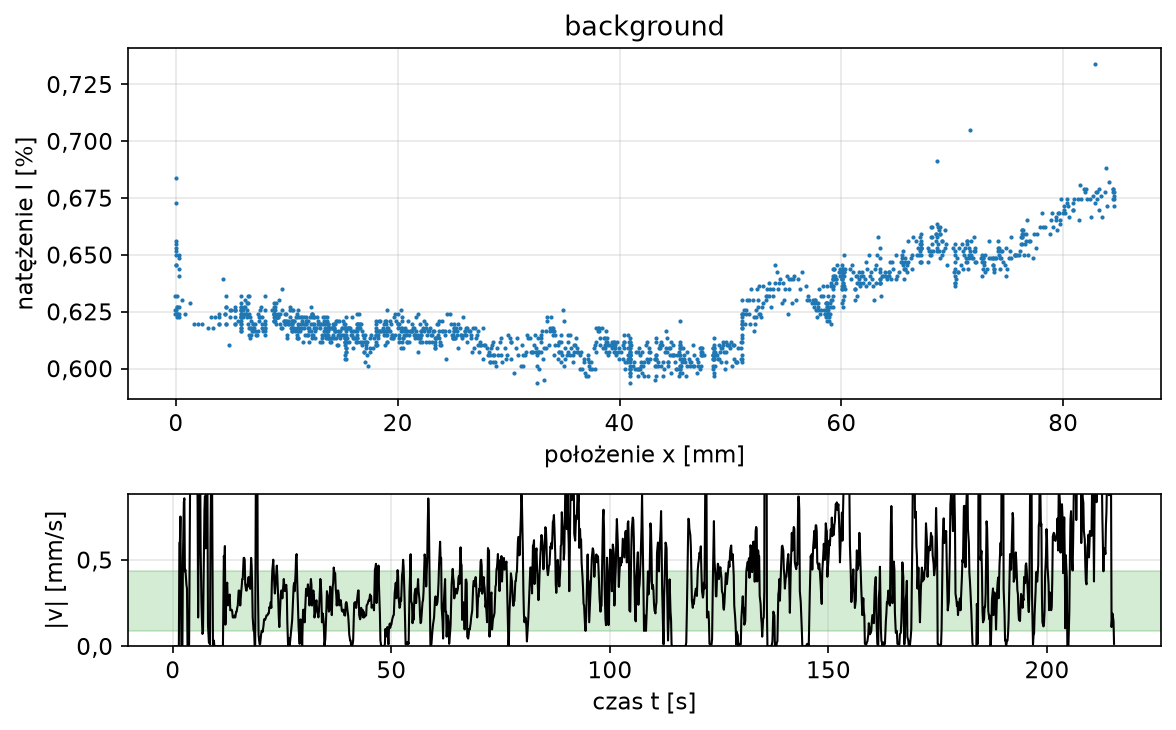

zapisano red/background.csv (1500 pkt, x: -0.1 … 84.6 mm, zakończono zawrotem; odcięto 3 pkt ustawiania/powrotu)
I_tło = 0.62 %, σ = 0.02 %


In [ ]:
meta_tlo = dict(part='background', N=0, a_nom=None, d_nom=None, D=None, u_D=None,
                aperture='', notes='laser zasłonięty')
tlo = skanuj('background', meta_tlo)
print(f'I_tło = {tlo["I"].mean():.2f} %, σ = {tlo["I"].std():.2f} %')

## Część A — pojedyncza szczelina

Ustawić na ekranie ostry obraz i **zaobserwować wpływ szerokości szczeliny** na obraz
(do opisu w sprawozdaniu: im węższa szczelina, tym szersze maksimum centralne i rzadsze minima, $y_1 = \lambda D/a$).
Zarejestrować rozkład dla wszystkich czterech szczelin, $a = 0{,}02;\ 0{,}04;\ 0{,}08;\ 0{,}16$ mm.
Dla $a = 0{,}02$ mm pierwsze minimum leży daleko ($\lambda D/a \approx 29$ mm dla czerwonego, $23$ mm dla zielonego)
— przejść pełen zakres skanera. Dla $a = 0{,}16$ mm minima są gęste (co $\approx 3{,}6$ / $3{,}0$ mm) — skanować wolno.
Jeśli obraz nie jest symetryczny względem maksimum centralnego (podgląd po skanie), poprawić ustawienie
i powtórzyć skan z `nadpisz=True`.

Notatki z obserwacji wpływu szerokości szczeliny (do wypełnienia w laboratorium):

- …

### A1 — $a = 0,02$ mm

— przejazd 1/3


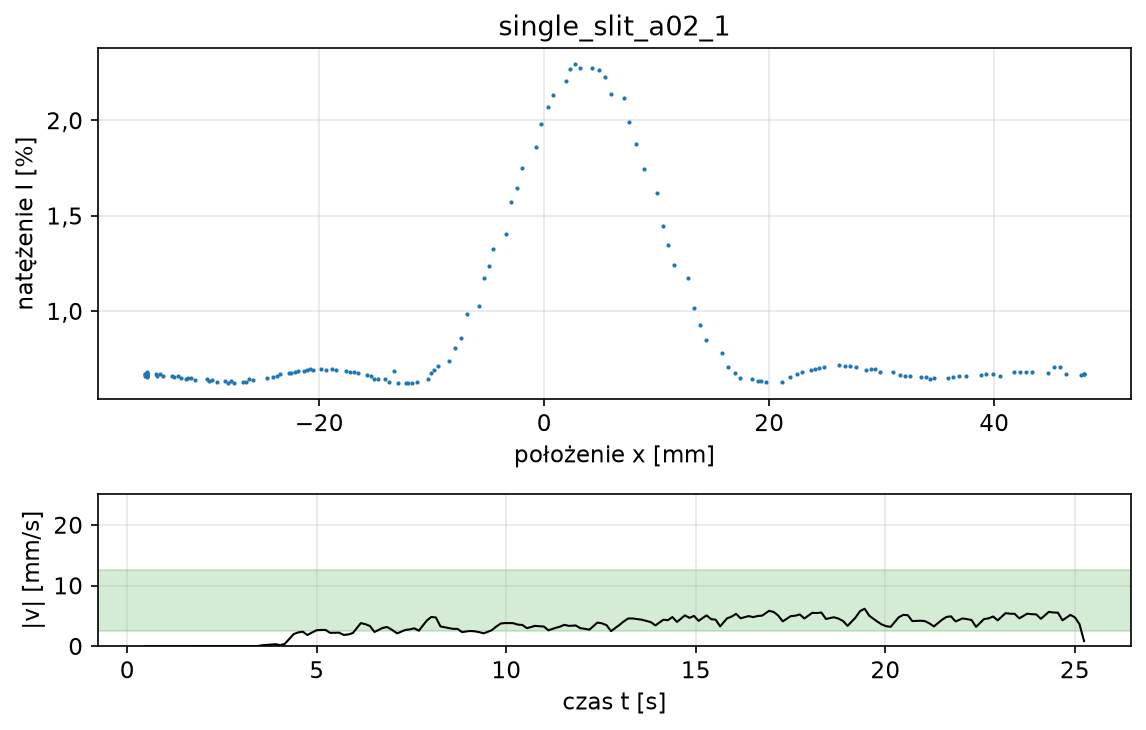

zapisano red/single_slit_a02_1.csv (177 pkt, x: -35.5 … 48.0 mm, zakończono zawrotem; odcięto 4 pkt ustawiania/powrotu)
— przejazd 2/3: jechać z powrotem


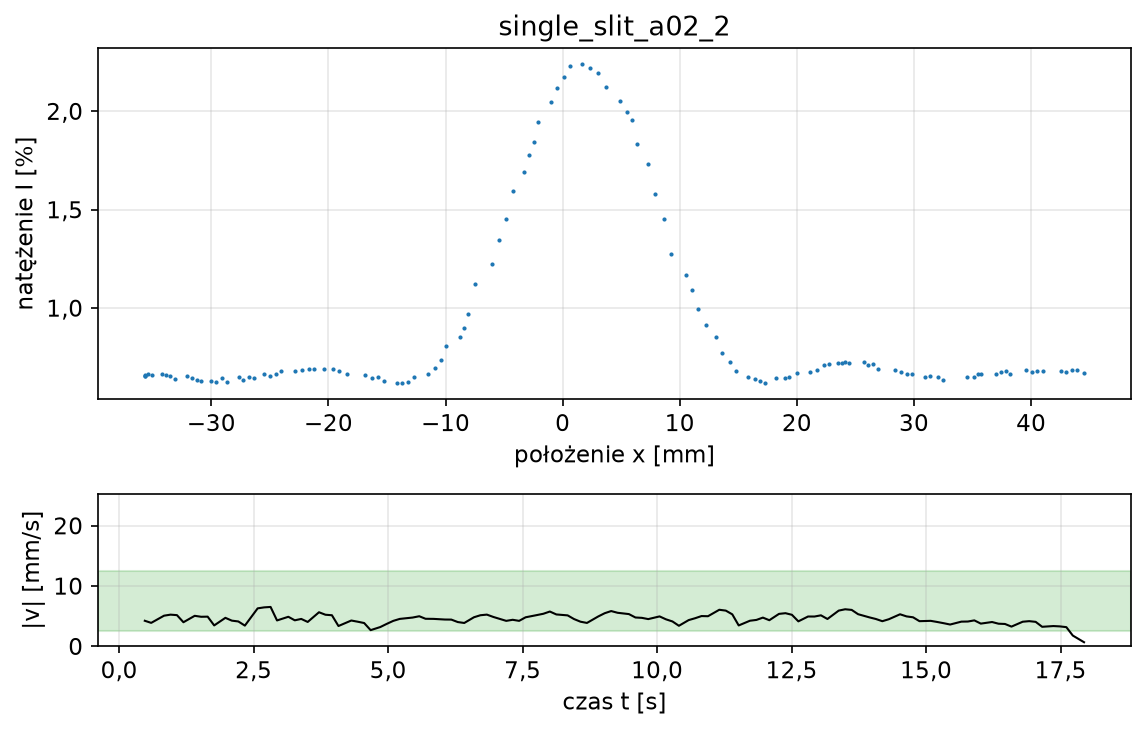

zapisano red/single_slit_a02_2.csv (126 pkt, x: -35.7 … 44.5 mm, zakończono zawrotem; odcięto 12 pkt ustawiania/powrotu)
— przejazd 3/3: jechać z powrotem


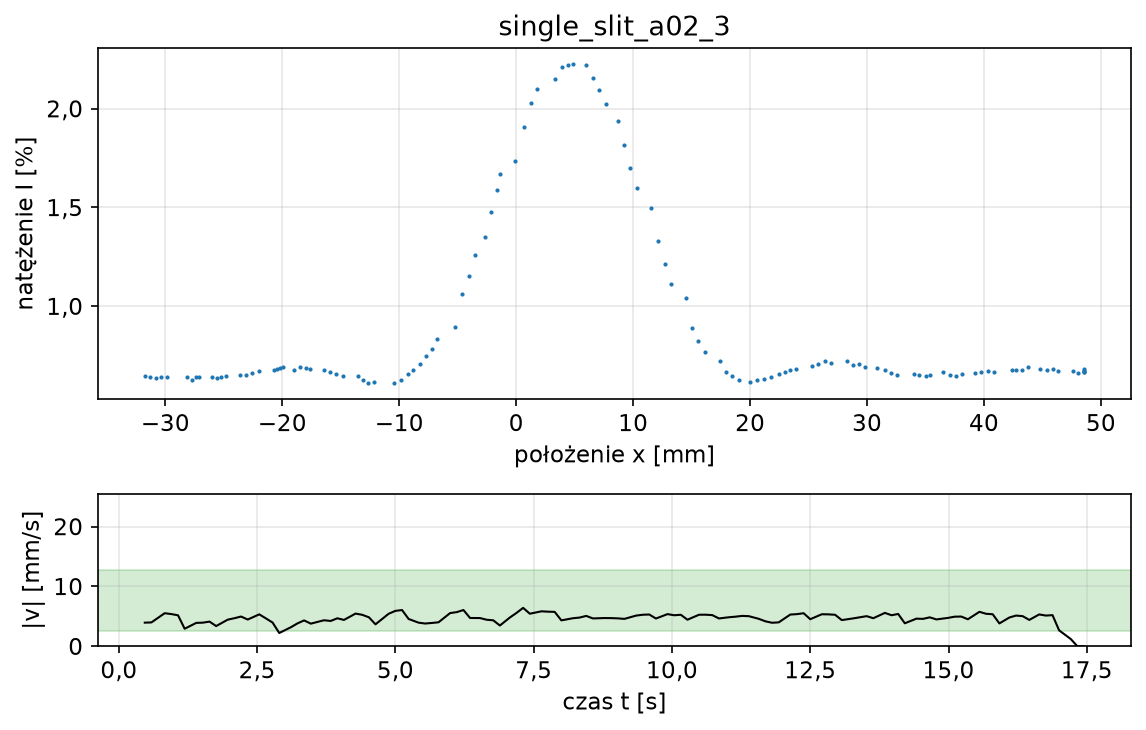

zapisano red/single_slit_a02_3.csv (124 pkt, x: -31.8 … 48.6 mm, zakończono zawrotem; odcięto 2 pkt ustawiania/powrotu)


In [ ]:
meta_A1 = dict(part='single_slit', N=1, a_nom=0.02, d_nom=None, D=D_UST, u_D=U_D,
               aperture='', notes='')
A1 = seria('single_slit_a02', meta_A1, n=3)

[1] a ≈ λD/x_1 = 0.0367 mm   (x_1 ≈ 15.68 mm, orientacyjnie)
[2] a ≈ λD/x_1 = 0.0372 mm   (x_1 ≈ 15.48 mm, orientacyjnie)
[3] a ≈ λD/x_1 = 0.0352 mm   (x_1 ≈ 16.38 mm, orientacyjnie)
a: średnia z 3 przejazdów = 0.0364 mm, rozrzut σ = 0.0011 mm


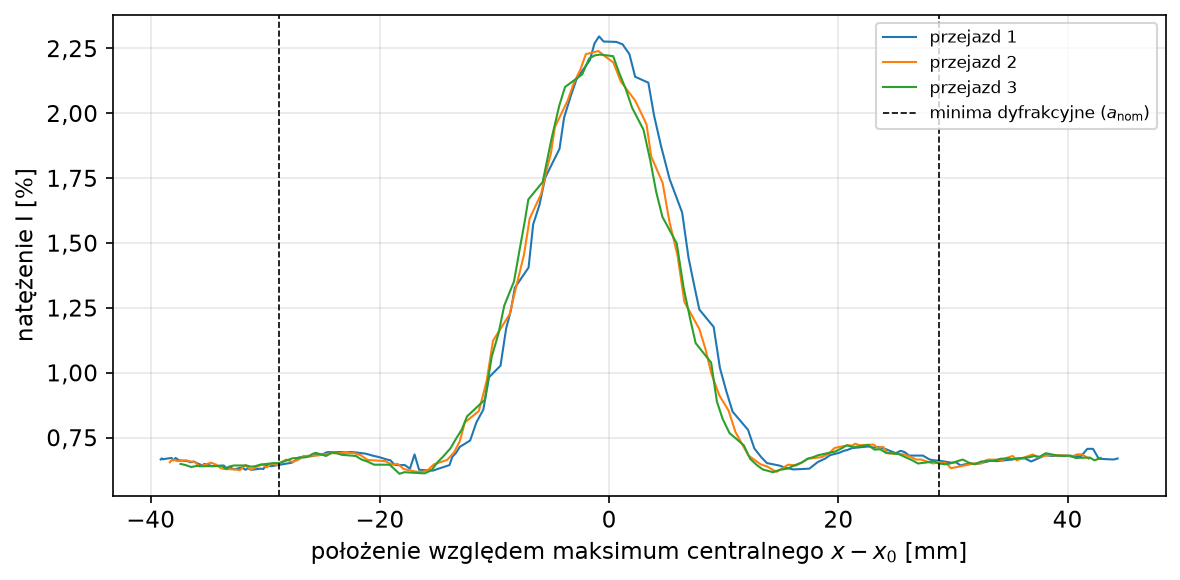

In [ ]:
_ = podglad(A1, meta_A1)

### A2 — $a = 0,04$ mm

— przejazd 1/3


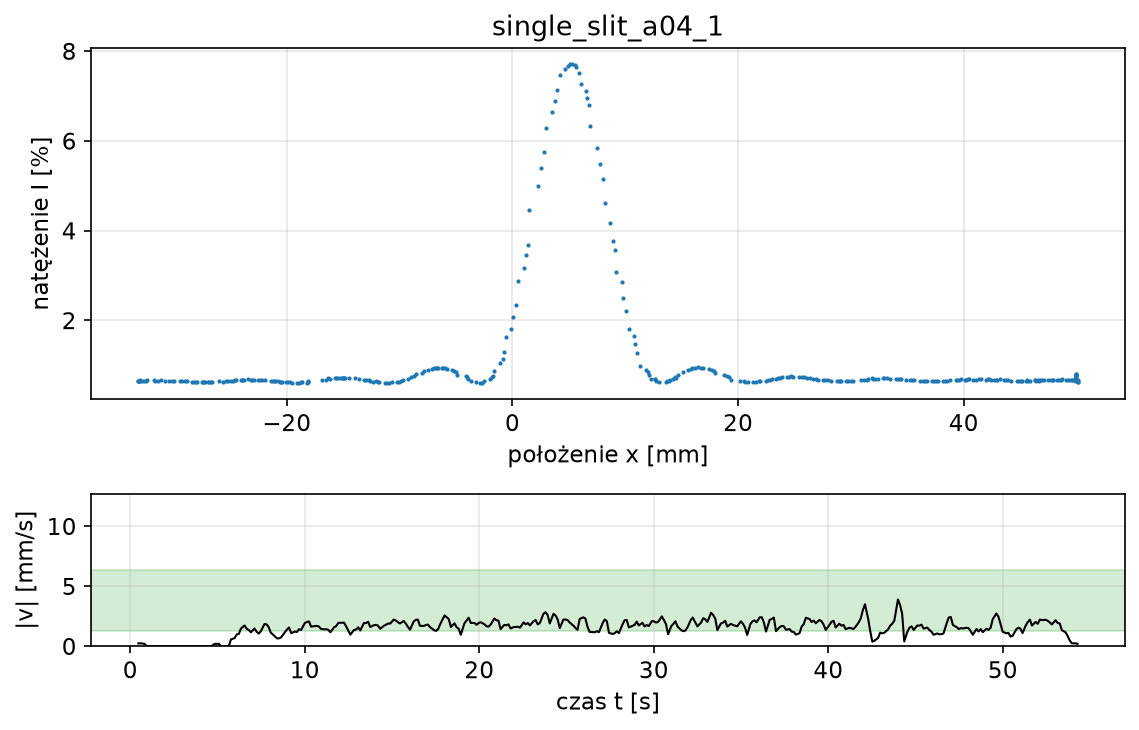

zapisano red/single_slit_a04_1.csv (383 pkt, x: -33.2 … 50.1 mm, zakończono zawrotem; odcięto 5 pkt ustawiania/powrotu)
— przejazd 2/3: jechać z powrotem


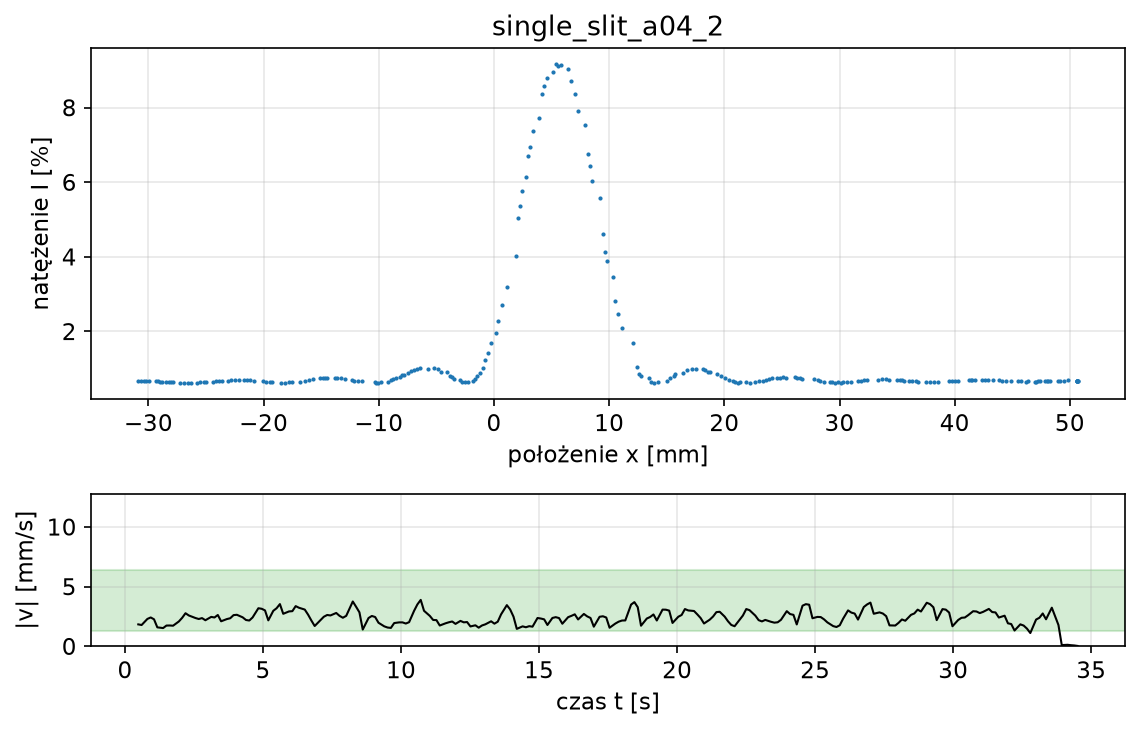

zapisano red/single_slit_a04_2.csv (245 pkt, x: -30.9 … 50.7 mm, zakończono zawrotem; odcięto 6 pkt ustawiania/powrotu)
— przejazd 3/3: jechać z powrotem


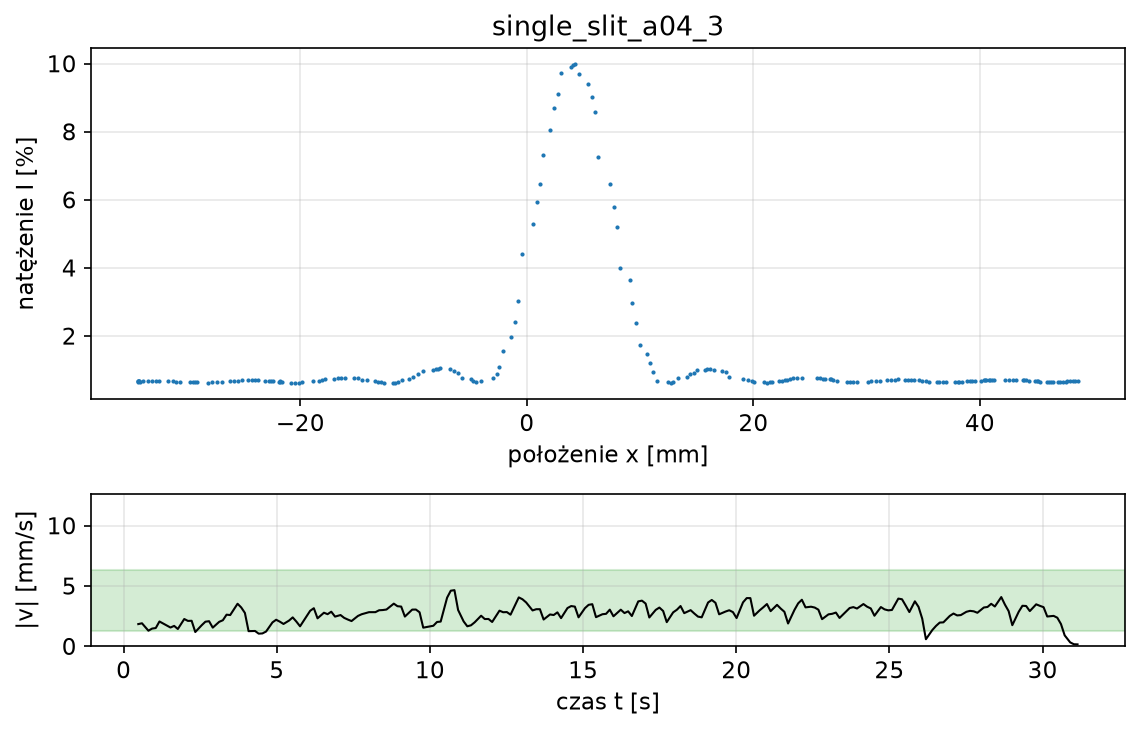

zapisano red/single_slit_a04_3.csv (219 pkt, x: -34.3 … 48.6 mm, zakończono zawrotem; odcięto 4 pkt ustawiania/powrotu)


In [ ]:
meta_A2 = dict(part='single_slit', N=1, a_nom=0.04, d_nom=None, D=D_UST, u_D=U_D,
               aperture='', notes='')
A2 = seria('single_slit_a04', meta_A2, n=3)

[1] a ≈ λD/x_1 = 0.0700 mm   (x_1 ≈ 8.22 mm, orientacyjnie)
[2] a ≈ λD/x_1 = 0.0700 mm   (x_1 ≈ 8.22 mm, orientacyjnie)
[3] a ≈ λD/x_1 = 0.0672 mm   (x_1 ≈ 8.57 mm, orientacyjnie)
a: średnia z 3 przejazdów = 0.0691 mm, rozrzut σ = 0.0017 mm


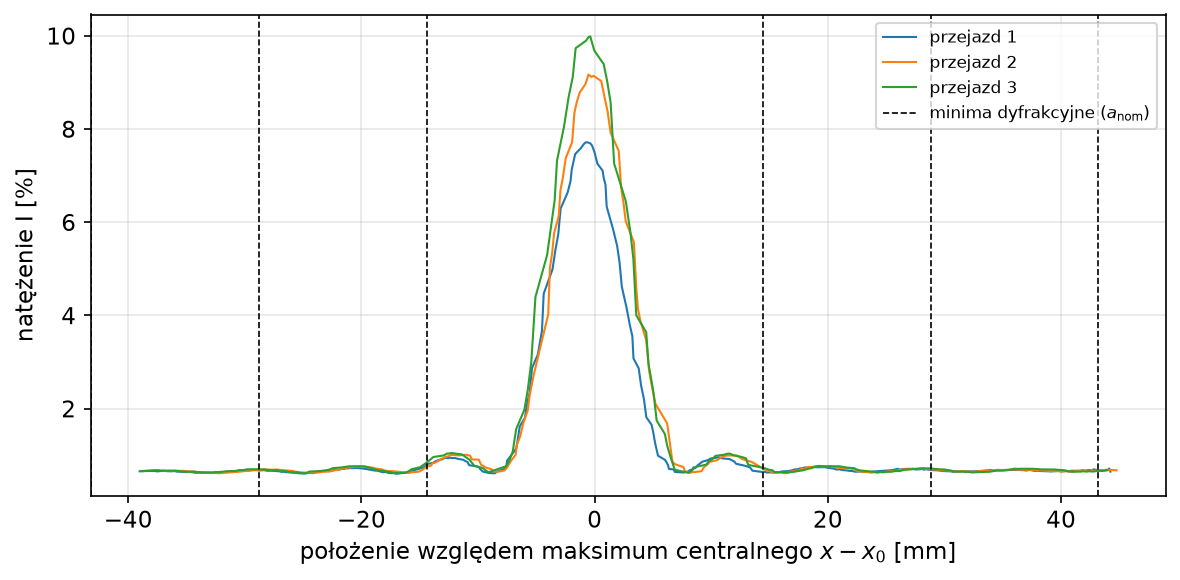

In [ ]:
_ = podglad(A2, meta_A2)

### A3 — $a = 0,08$ mm

— przejazd 1/3


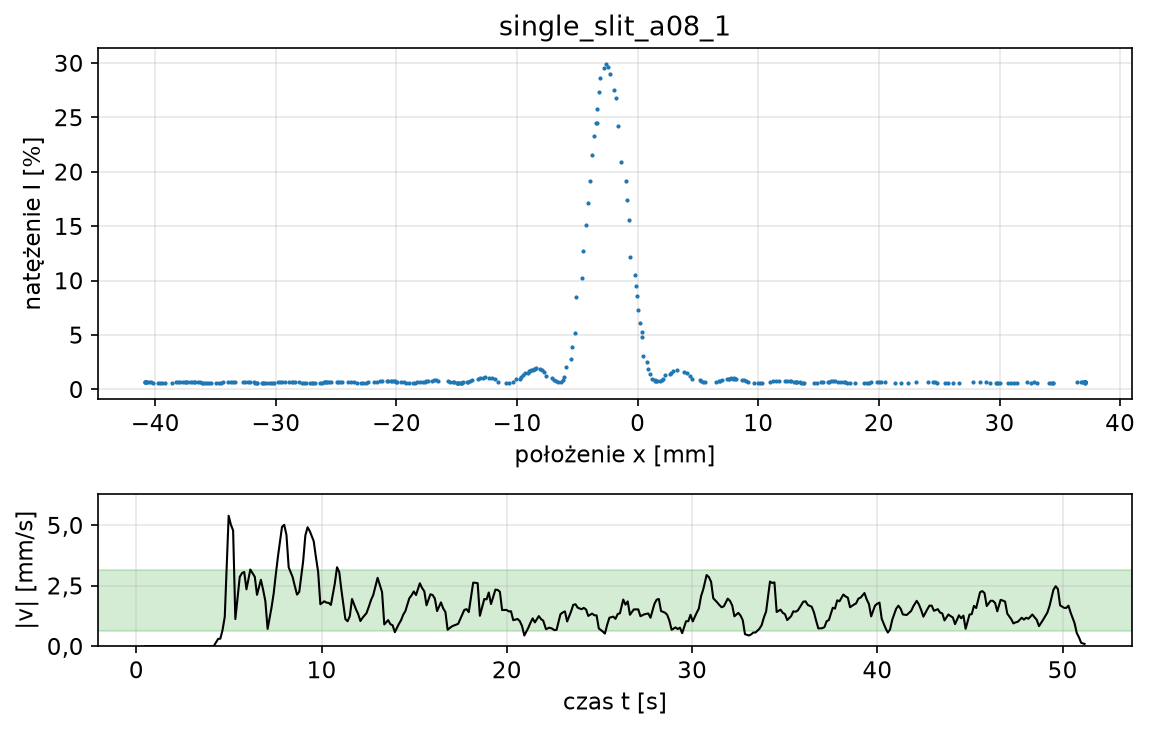

zapisano red/single_slit_a08_1.csv (358 pkt, x: -40.8 … 37.0 mm, zakończono zawrotem; odcięto 8 pkt ustawiania/powrotu)
— przejazd 2/3: jechać z powrotem


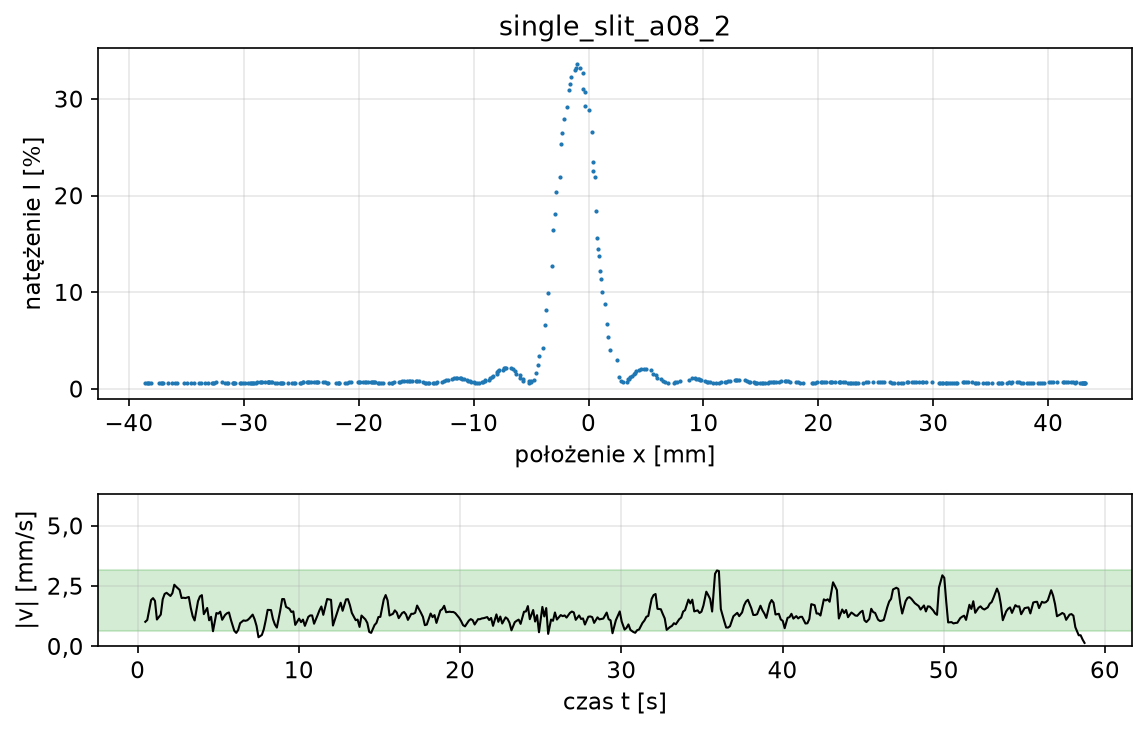

zapisano red/single_slit_a08_2.csv (413 pkt, x: -38.6 … 43.2 mm, zakończono zawrotem; odcięto 9 pkt ustawiania/powrotu)
— przejazd 3/3: jechać z powrotem


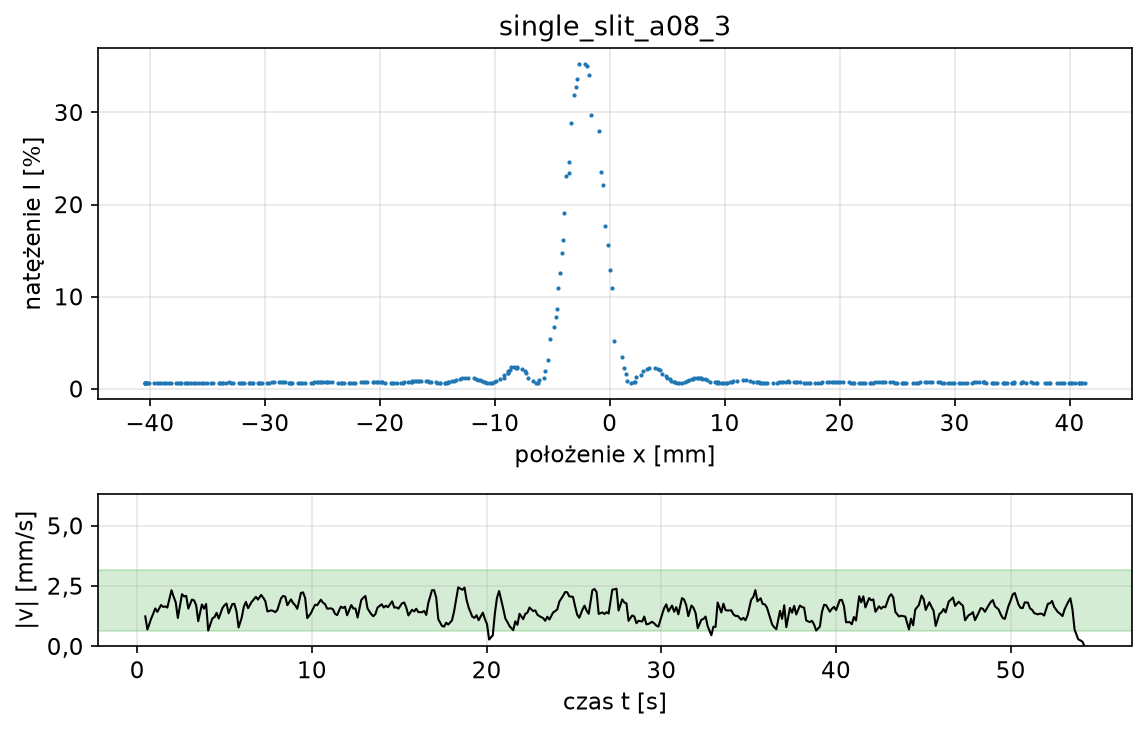

zapisano red/single_slit_a08_3.csv (381 pkt, x: -40.4 … 41.3 mm, zakończono zawrotem; odcięto 9 pkt ustawiania/powrotu)


In [ ]:
meta_A3 = dict(part='single_slit', N=1, a_nom=0.08, d_nom=None, D=D_UST, u_D=U_D,
               aperture='', notes='')
A3 = seria('single_slit_a08', meta_A3, n=3)

[1] a ≈ λD/x_1 = 0.1413 mm   (x_1 ≈ 4.08 mm, orientacyjnie)
[2] a ≈ λD/x_1 = 0.1340 mm   (x_1 ≈ 4.30 mm, orientacyjnie)
[3] a ≈ λD/x_1 = 0.1347 mm   (x_1 ≈ 4.28 mm, orientacyjnie)
a: średnia z 3 przejazdów = 0.1367 mm, rozrzut σ = 0.0041 mm


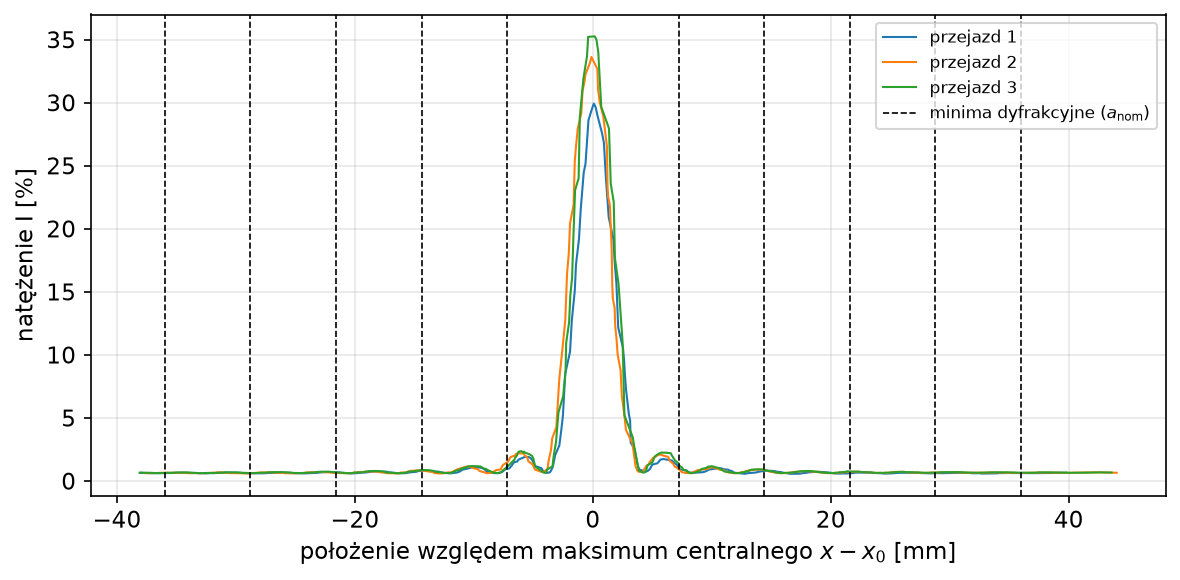

In [ ]:
_ = podglad(A3, meta_A3)

### A4 — $a = 0,16$ mm

— przejazd 1/3


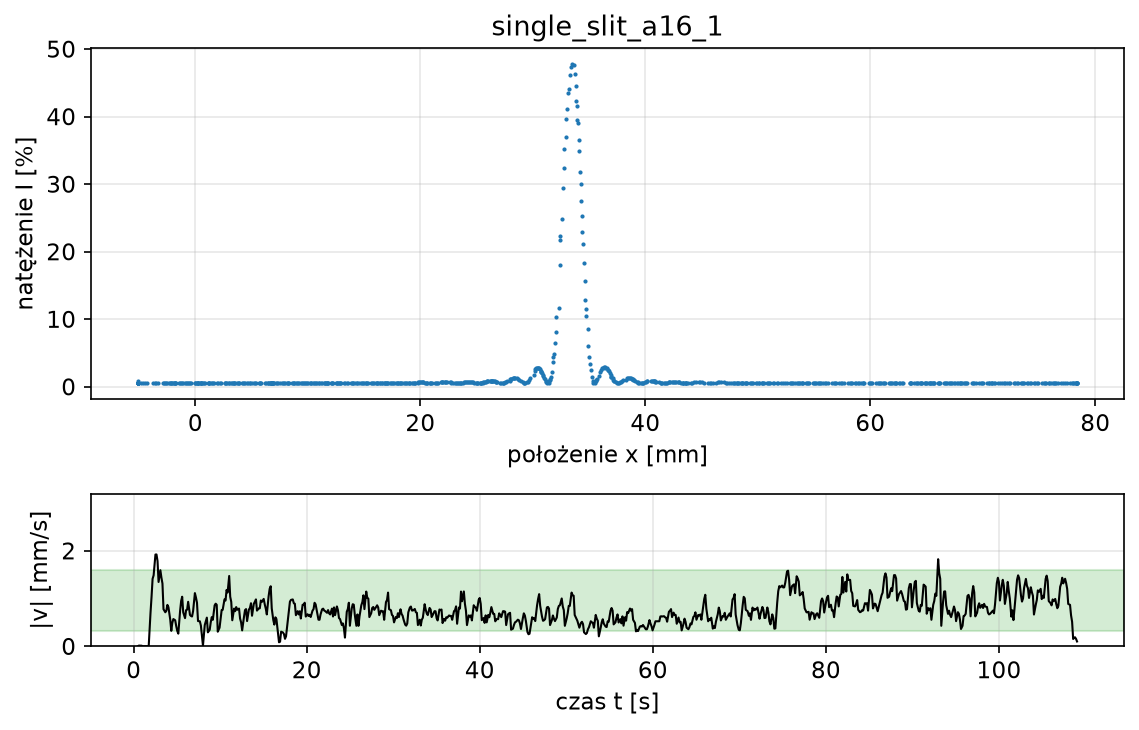

zapisano red/single_slit_a16_1.csv (772 pkt, x: -5.1 … 78.4 mm, zakończono zawrotem; odcięto 54 pkt ustawiania/powrotu)
— przejazd 2/3: jechać z powrotem


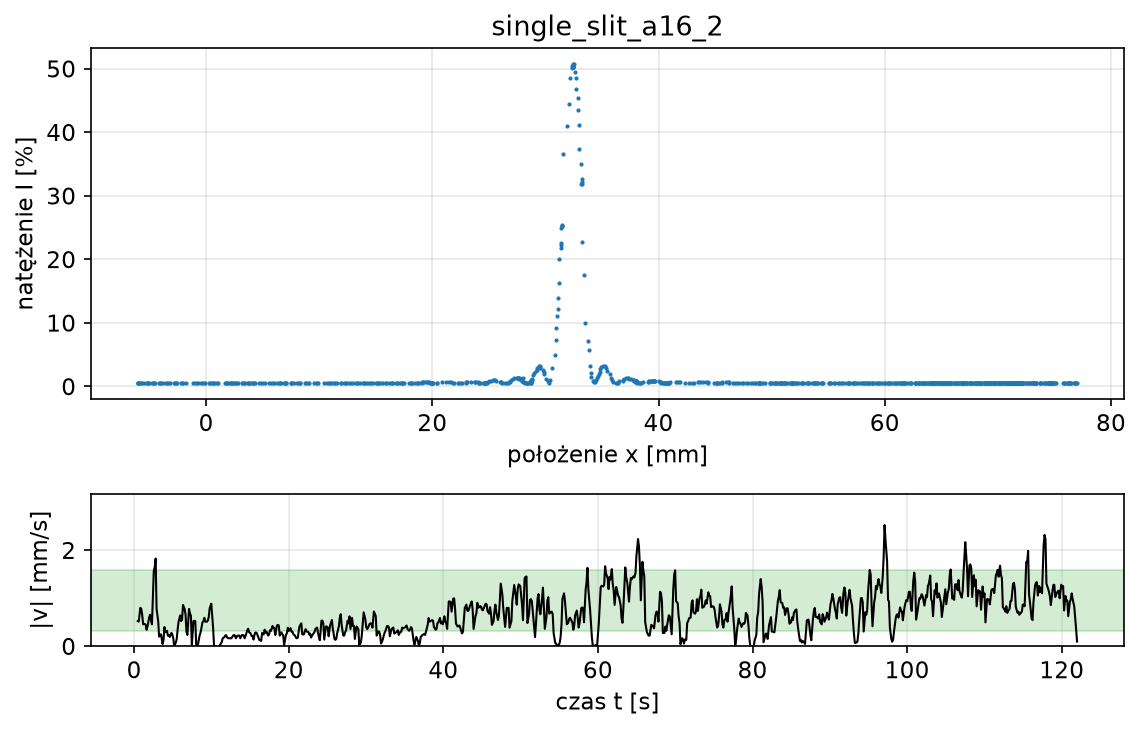

zapisano red/single_slit_a16_2.csv (860 pkt, x: -6.0 … 77.0 mm, zakończono zawrotem; odcięto 6 pkt ustawiania/powrotu)
— przejazd 3/3: jechać z powrotem


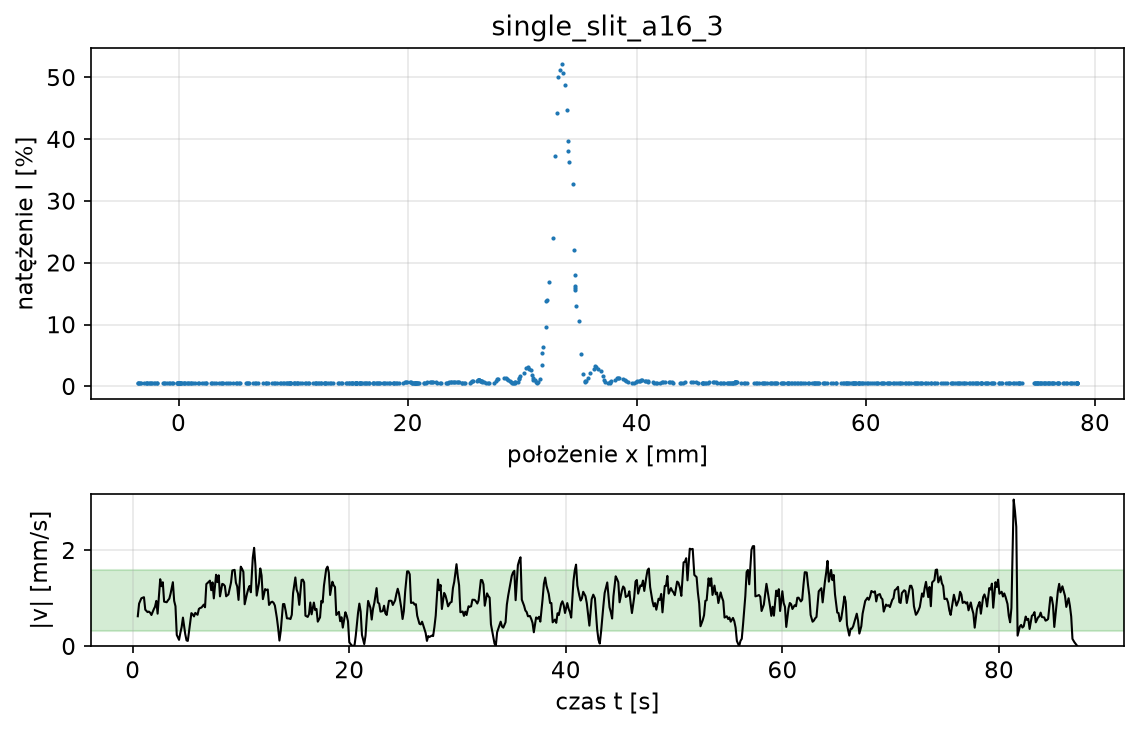

zapisano red/single_slit_a16_3.csv (615 pkt, x: -3.6 … 78.4 mm, zakończono zawrotem; odcięto 7 pkt ustawiania/powrotu)


In [ ]:
meta_A4 = dict(part='single_slit', N=1, a_nom=0.16, d_nom=None, D=D_UST, u_D=U_D,
               aperture='', notes='')
A4 = seria('single_slit_a16', meta_A4, n=3)

[1] a ≈ λD/x_1 = 0.2679 mm   (x_1 ≈ 2.15 mm, orientacyjnie)
[2] a ≈ λD/x_1 = 0.2776 mm   (x_1 ≈ 2.07 mm, orientacyjnie)
[3] a ≈ λD/x_1 = 0.2679 mm   (x_1 ≈ 2.15 mm, orientacyjnie)
a: średnia z 3 przejazdów = 0.2711 mm, rozrzut σ = 0.0056 mm


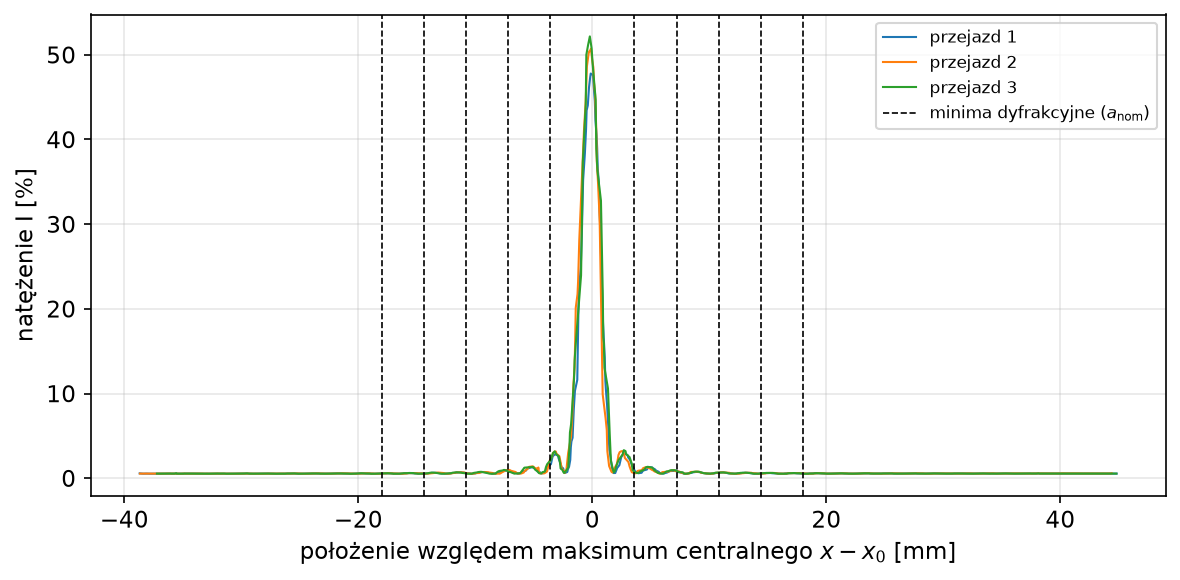

In [ ]:
_ = podglad(A4, meta_A4)

## Część B — dwie szczeliny

Zmierzyć **wszystkie cztery zestawy** dwóch szczelin. Czego się spodziewać:

- prążki interferencyjne co $\Delta y = \lambda D/d$ — dla $d = 0{,}50$ mm dwa razy gęściej niż dla $0{,}25$ mm;
- obwiednia $\left[\sin(\pi a y/\lambda D)/(\pi a y/\lambda D)\right]^2$ z minimami co $\lambda D/a$ — dla $a = 0{,}08$ mm
  dwa razy węższa niż dla $0{,}04$ mm; w maksimum centralnym obwiedni mieści się $\approx 2d/a$ prążków;
- $d/a = 3{,}125;\ 6{,}25;\ 12{,}5$ nie jest całkowite, więc żaden rząd nie znika całkowicie, ale prążki
  w pobliżu minimów obwiedni są silnie osłabione.

Skan powinien obejmować co najmniej maksimum centralne obwiedni i pierwsze minimum obwiedni po obu stronach.
Żeby prążki były rozdzielone, $\Delta y$ musi być znacznie większe od szczeliny wejściowej czujnika —
w razie potrzeby wybrać węższą szczelinę wejściową albo zwiększyć $D$.

### B1 — $a = 0,04$ mm, $d = 0,25$ mm

— przejazd 1/3


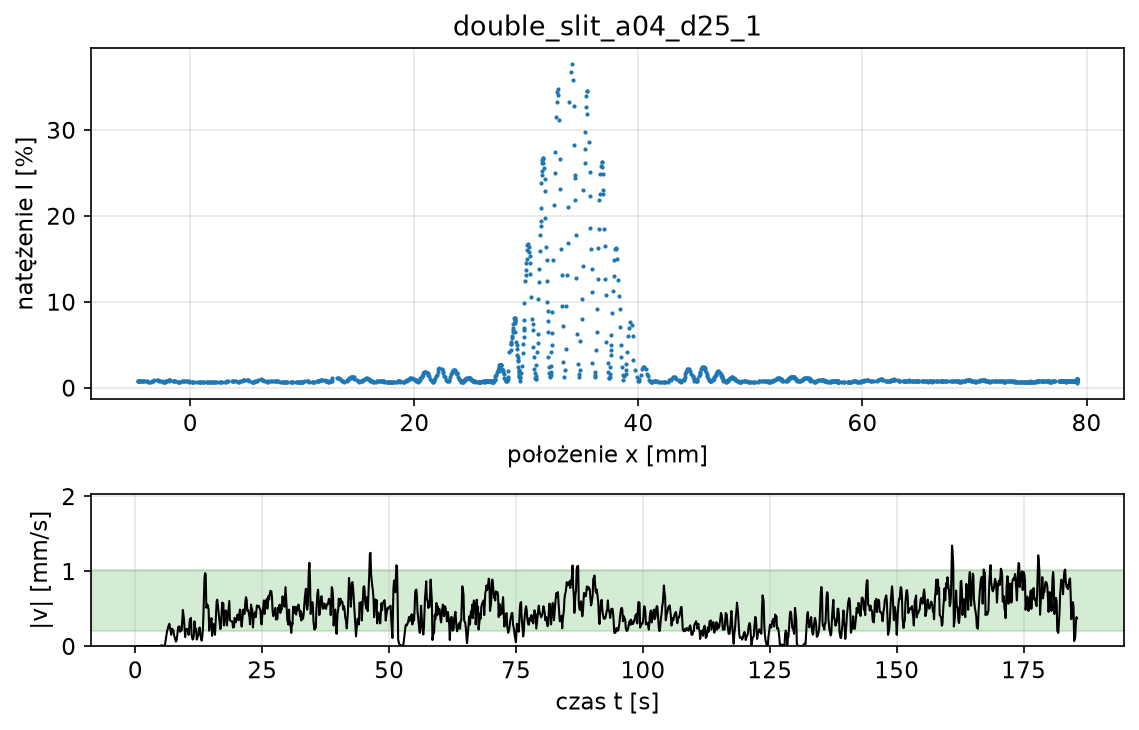

zapisano red/double_slit_a04_d25_1.csv (1309 pkt, x: -4.7 … 79.2 mm, zakończono zawrotem; odcięto 13 pkt ustawiania/powrotu)
— przejazd 2/3: jechać z powrotem


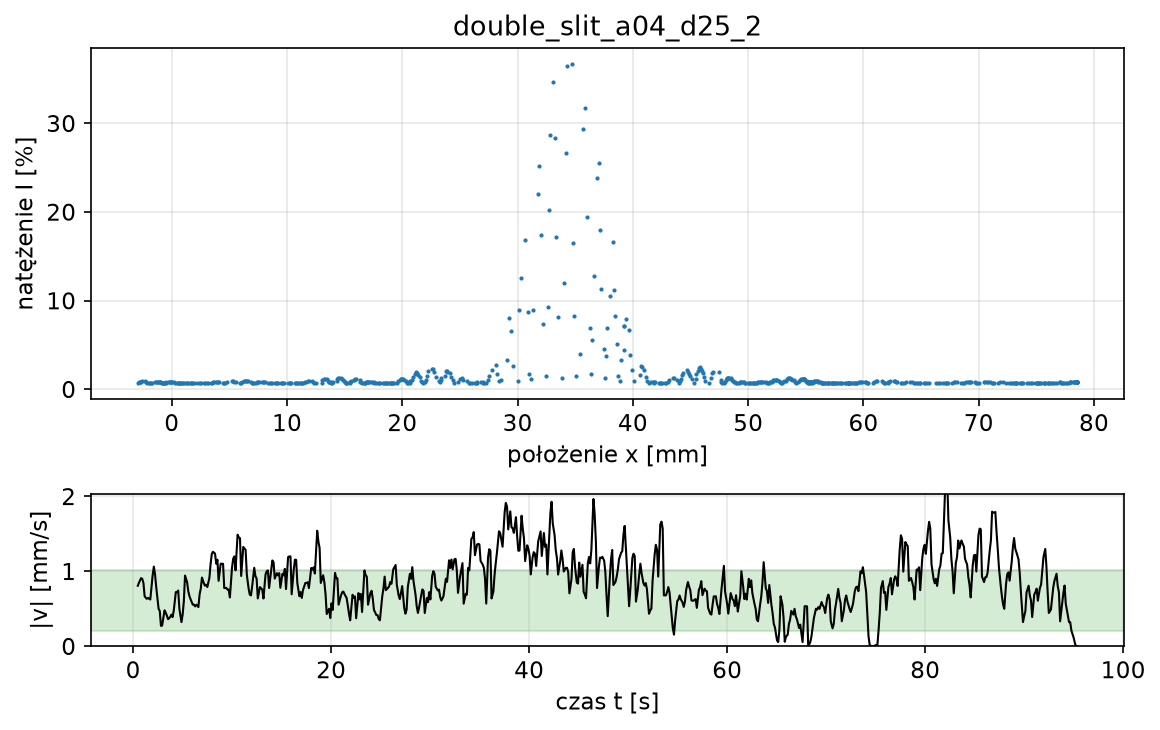

zapisano red/double_slit_a04_d25_2.csv (673 pkt, x: -2.9 … 78.5 mm, zakończono zawrotem; odcięto 23 pkt ustawiania/powrotu)
— przejazd 3/3: jechać z powrotem


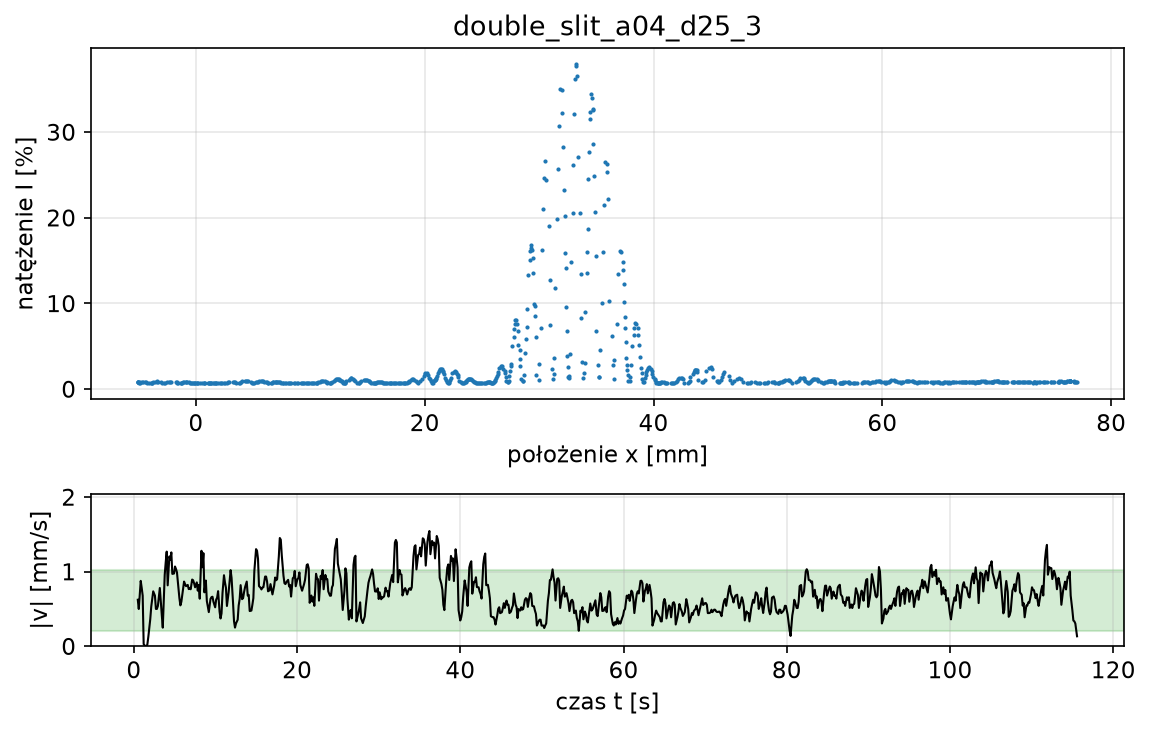

zapisano red/double_slit_a04_d25_3.csv (818 pkt, x: -5.1 … 77.0 mm, zakończono zawrotem; odcięto 55 pkt ustawiania/powrotu)


In [ ]:
meta_B1 = dict(part='double_slit', N=2, a_nom=0.04, d_nom=0.25, D=D_UST, u_D=U_D,
               aperture='', notes='')
B1 = seria('double_slit_a04_d25', meta_B1, n=3)

[1] d ≈ λD/Δy = 0.4465 mm   (Δy ≈ 1.29 mm, orientacyjnie)
[2] d ≈ λD/Δy = 0.4760 mm   (Δy ≈ 1.21 mm, orientacyjnie)
[3] d ≈ λD/Δy = 0.4431 mm   (Δy ≈ 1.30 mm, orientacyjnie)
d: średnia z 3 przejazdów = 0.4552 mm, rozrzut σ = 0.0181 mm


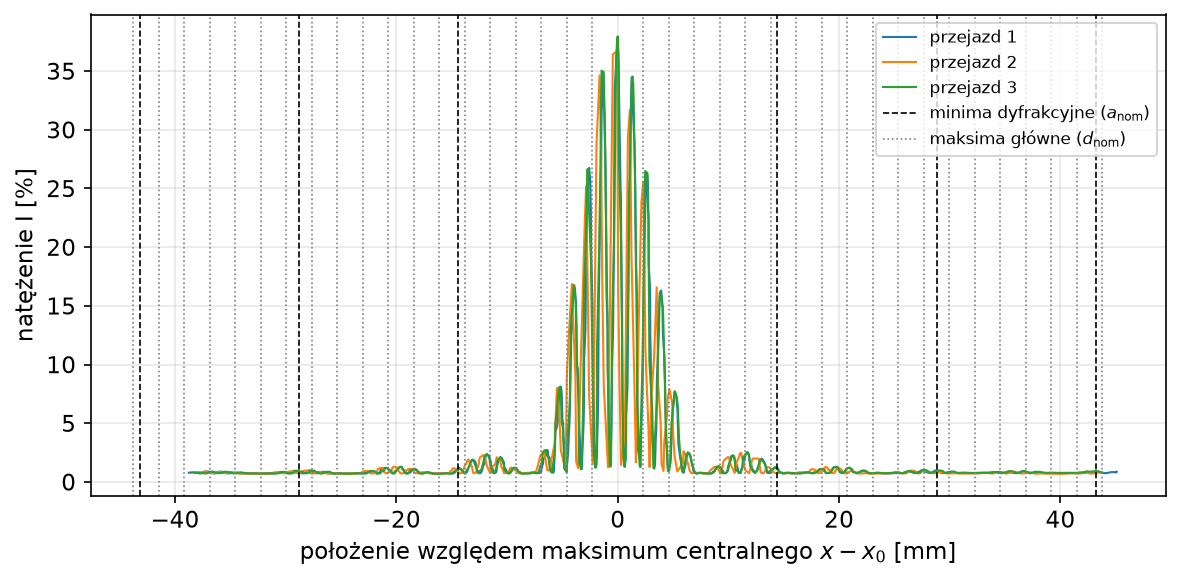

In [ ]:
_ = podglad(B1, meta_B1, krok=0.02)

### B2 — $a = 0,04$ mm, $d = 0,50$ mm

— przejazd 1/3


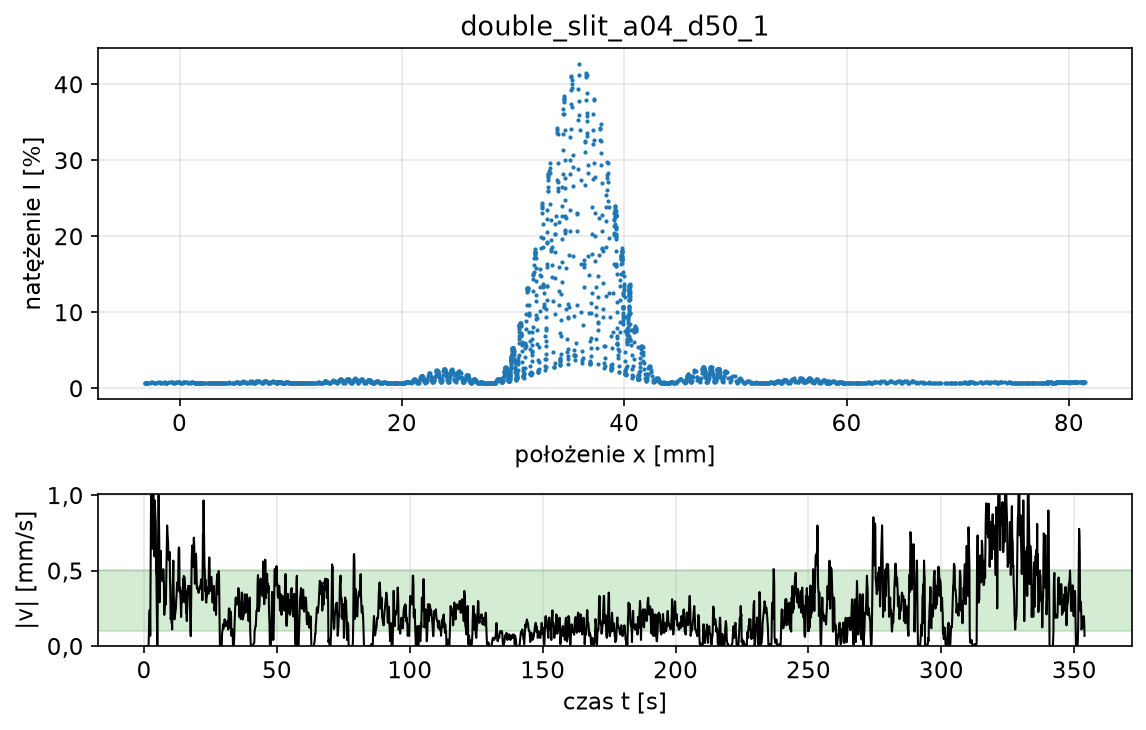

zapisano red/double_slit_a04_d50_1.csv (2479 pkt, x: -3.1 … 81.4 mm, zakończono zawrotem; odcięto 34 pkt ustawiania/powrotu)
— przejazd 2/3: jechać z powrotem


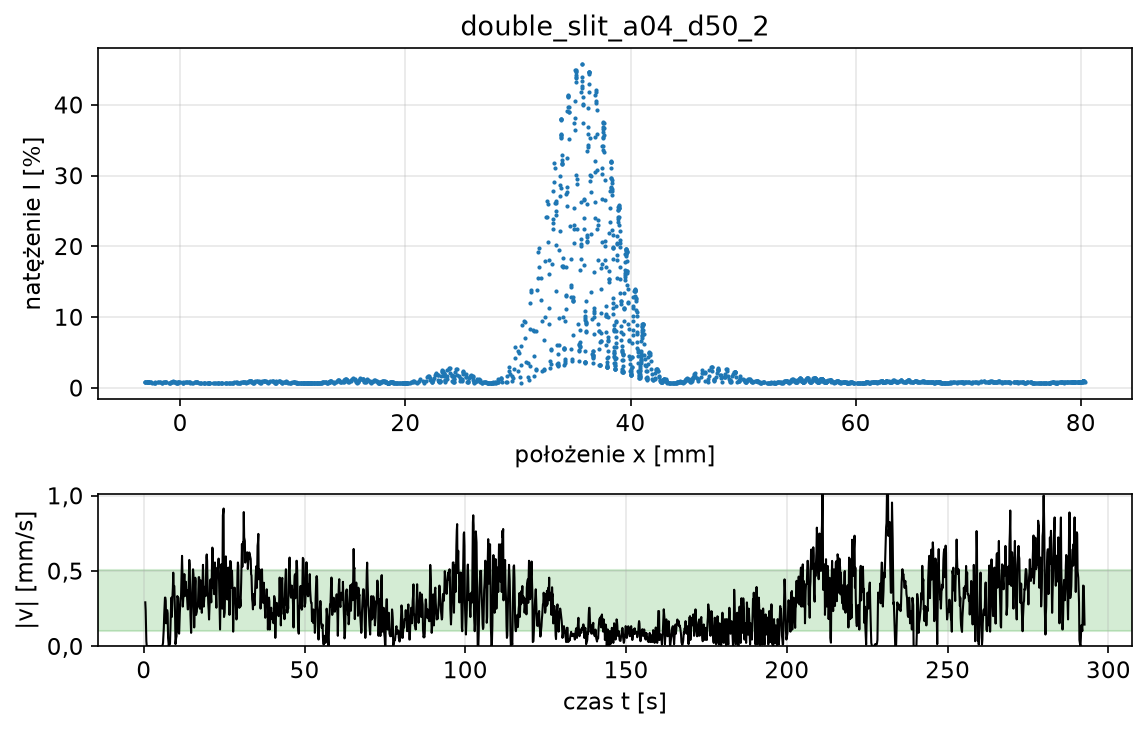

zapisano red/double_slit_a04_d50_2.csv (2053 pkt, x: -3.1 … 80.3 mm, zakończono zawrotem; odcięto 40 pkt ustawiania/powrotu)
— przejazd 3/3: jechać z powrotem


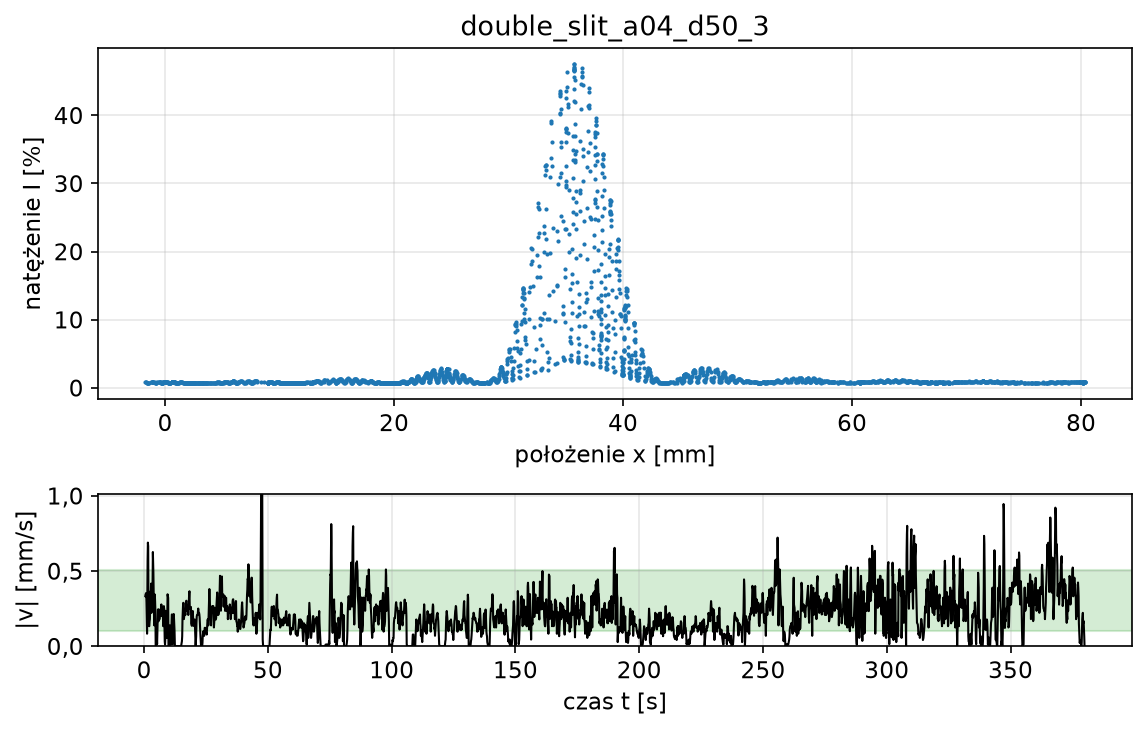

zapisano red/double_slit_a04_d50_3.csv (2669 pkt, x: -1.7 … 80.3 mm, zakończono zawrotem; odcięto 11 pkt ustawiania/powrotu)


In [ ]:
meta_B2 = dict(part='double_slit', N=2, a_nom=0.04, d_nom=0.5, D=D_UST, u_D=U_D,
               aperture='', notes='')
B2 = seria('double_slit_a04_d50', meta_B2, n=3)

[1] d ≈ λD/Δy = 0.8862 mm   (Δy ≈ 0.65 mm, orientacyjnie)
[2] d ≈ λD/Δy = 0.8727 mm   (Δy ≈ 0.66 mm, orientacyjnie)
[3] d ≈ λD/Δy = 0.9000 mm   (Δy ≈ 0.64 mm, orientacyjnie)
d: średnia z 3 przejazdów = 0.8863 mm, rozrzut σ = 0.0136 mm


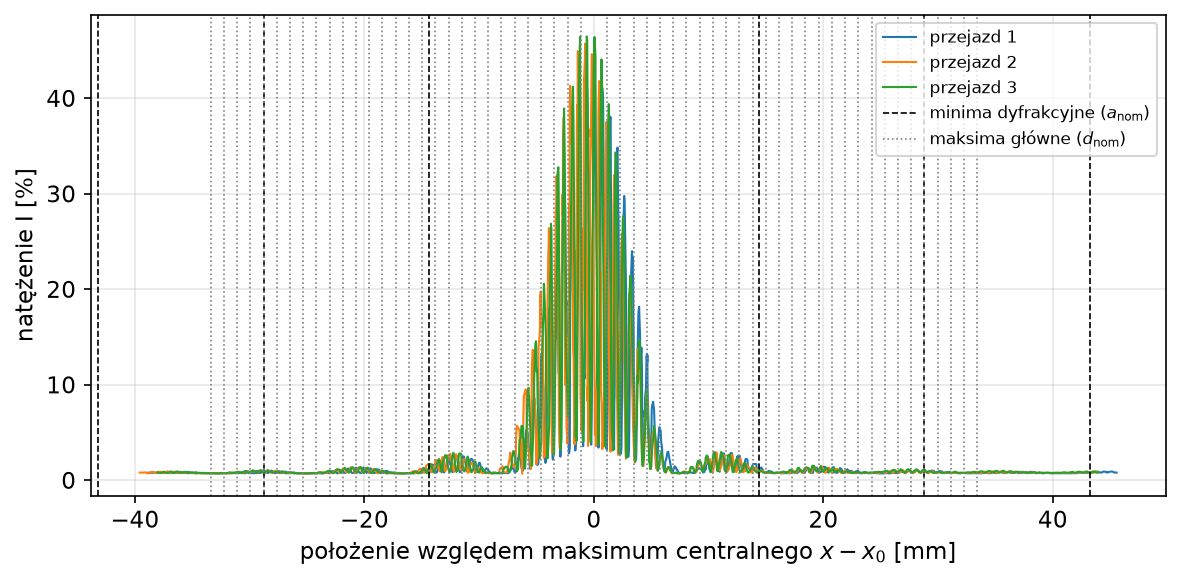

In [ ]:
_ = podglad(B2, meta_B2, krok=0.02)

### B3 — $a = 0,08$ mm, $d = 0,25$ mm

— przejazd 1/3


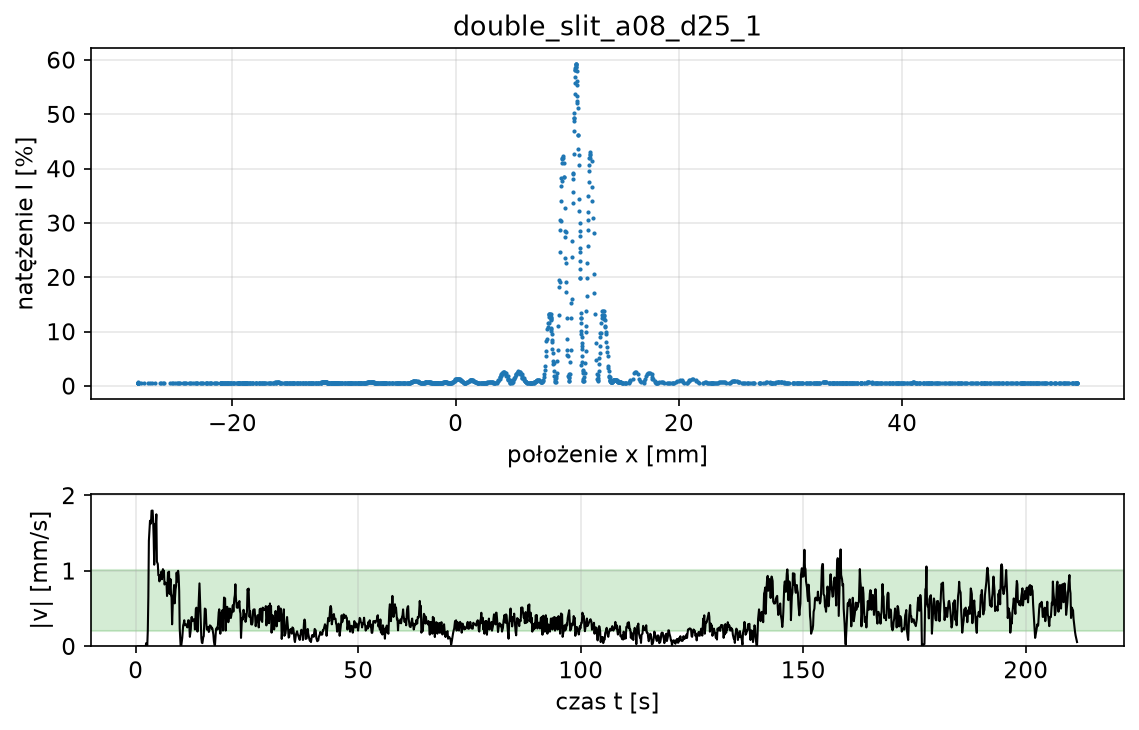

zapisano red/double_slit_a08_d25_1.csv (1482 pkt, x: -28.5 … 55.7 mm, zakończono zawrotem; odcięto 17 pkt ustawiania/powrotu)
— przejazd 2/3: jechać z powrotem


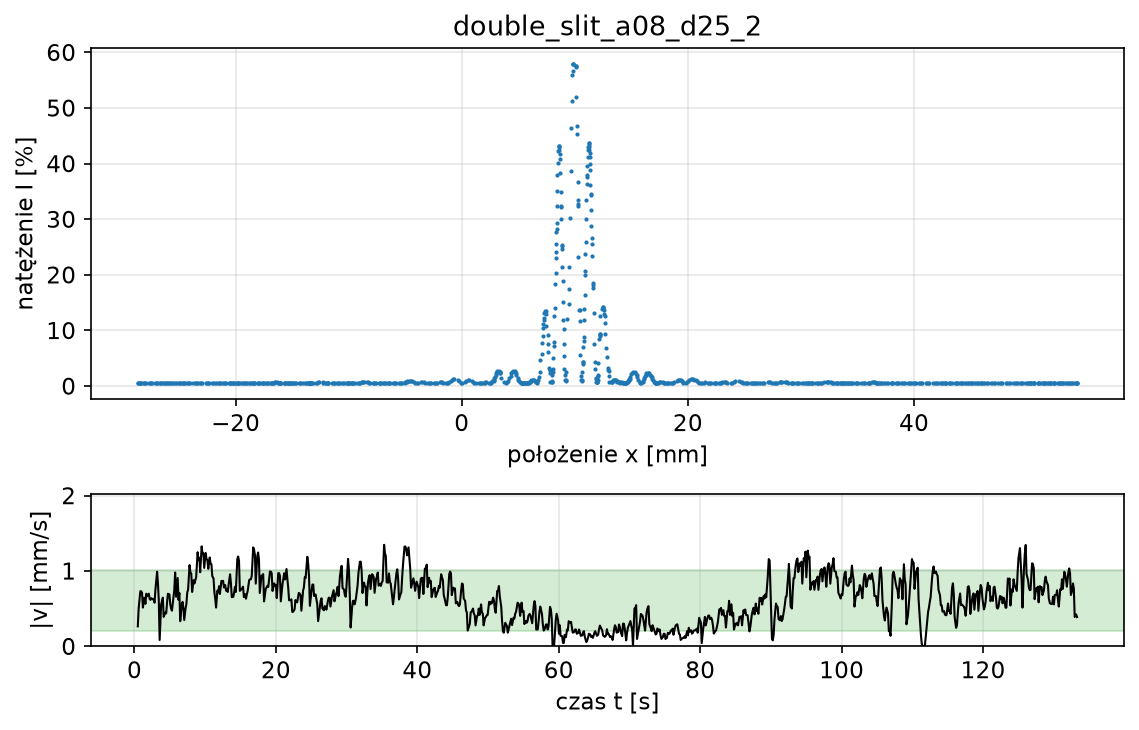

zapisano red/double_slit_a08_d25_2.csv (935 pkt, x: -28.6 … 54.4 mm, zakończono zawrotem; odcięto 12 pkt ustawiania/powrotu)
— przejazd 3/3: jechać z powrotem


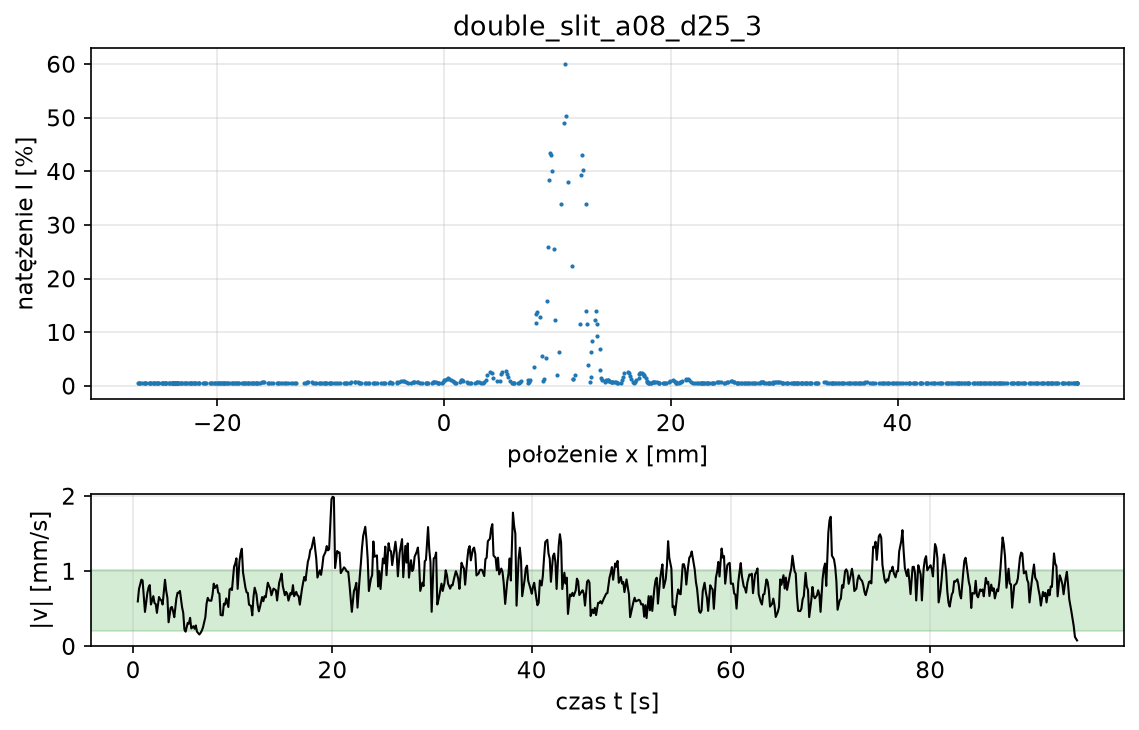

zapisano red/double_slit_a08_d25_3.csv (666 pkt, x: -27.0 … 55.8 mm, zakończono zawrotem; odcięto 4 pkt ustawiania/powrotu)


In [ ]:
meta_B3 = dict(part='double_slit', N=2, a_nom=0.08, d_nom=0.25, D=D_UST, u_D=U_D,
               aperture='', notes='')
B3 = seria('double_slit_a08_d25', meta_B3, n=3)

[1] d ≈ λD/Δy = 0.4760 mm   (Δy ≈ 1.21 mm, orientacyjnie)
[2] d ≈ λD/Δy = 0.4608 mm   (Δy ≈ 1.25 mm, orientacyjnie)
[3] d ≈ λD/Δy = 0.4571 mm   (Δy ≈ 1.26 mm, orientacyjnie)
d: średnia z 3 przejazdów = 0.4647 mm, rozrzut σ = 0.0100 mm


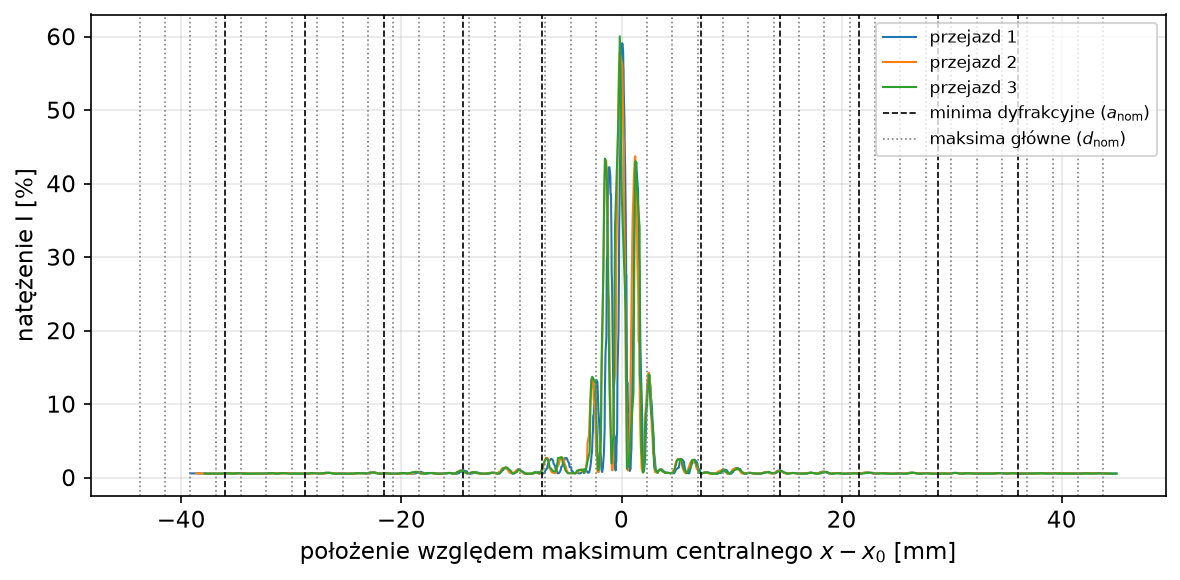

In [ ]:
_ = podglad(B3, meta_B3, krok=0.02)

### B4 — $a = 0,08$ mm, $d = 0,50$ mm

— przejazd 1/3


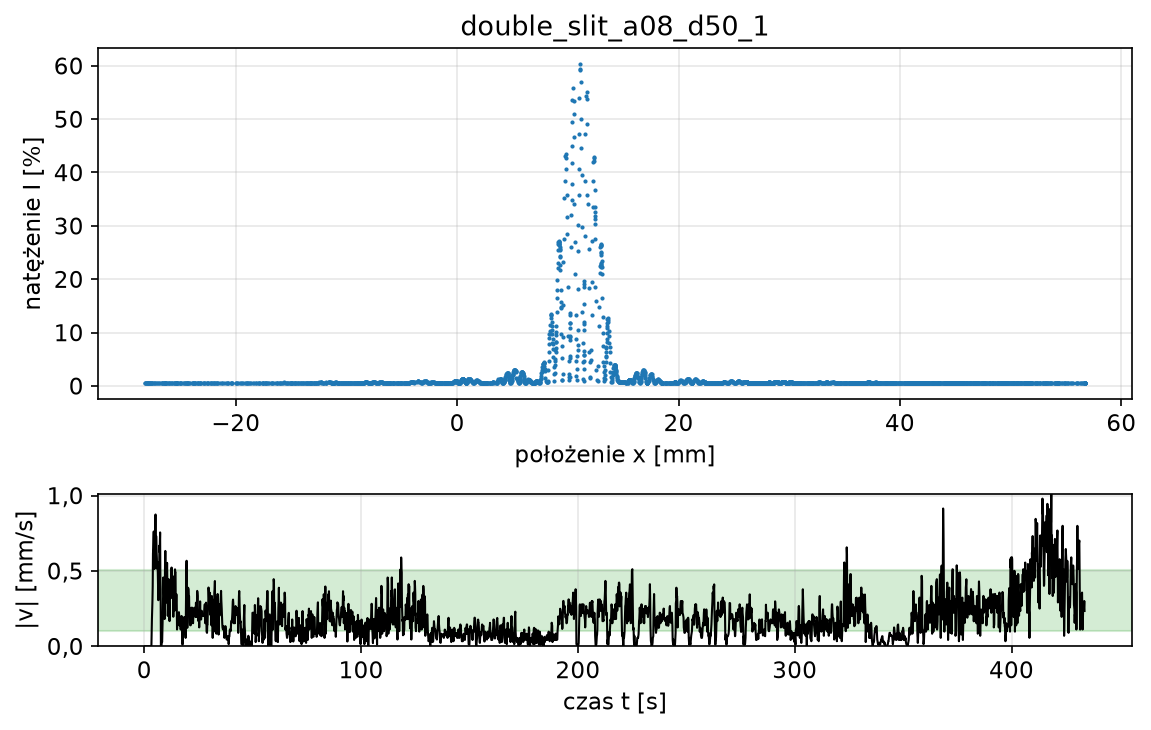

zapisano red/double_slit_a08_d50_1.csv (3030 pkt, x: -28.2 … 56.7 mm, zakończono zawrotem; odcięto 22 pkt ustawiania/powrotu)
— przejazd 2/3: jechać z powrotem


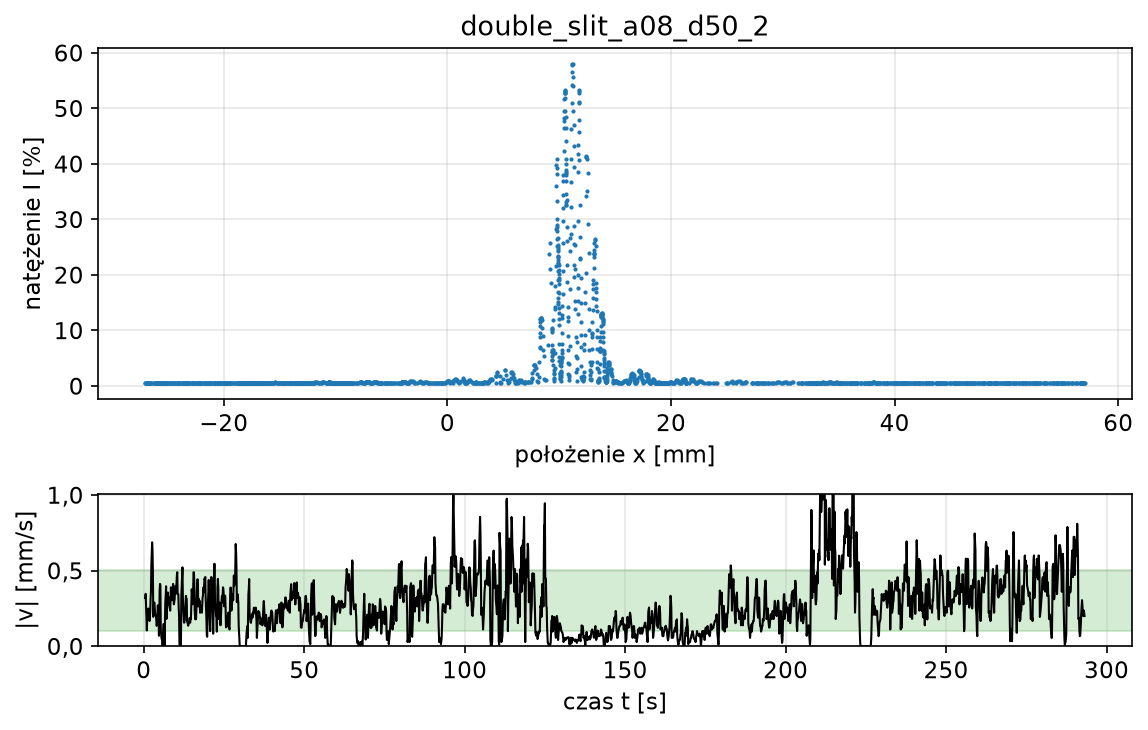

zapisano red/double_slit_a08_d50_2.csv (2049 pkt, x: -27.0 … 57.0 mm, zakończono zawrotem; odcięto 20 pkt ustawiania/powrotu)
— przejazd 3/3: jechać z powrotem


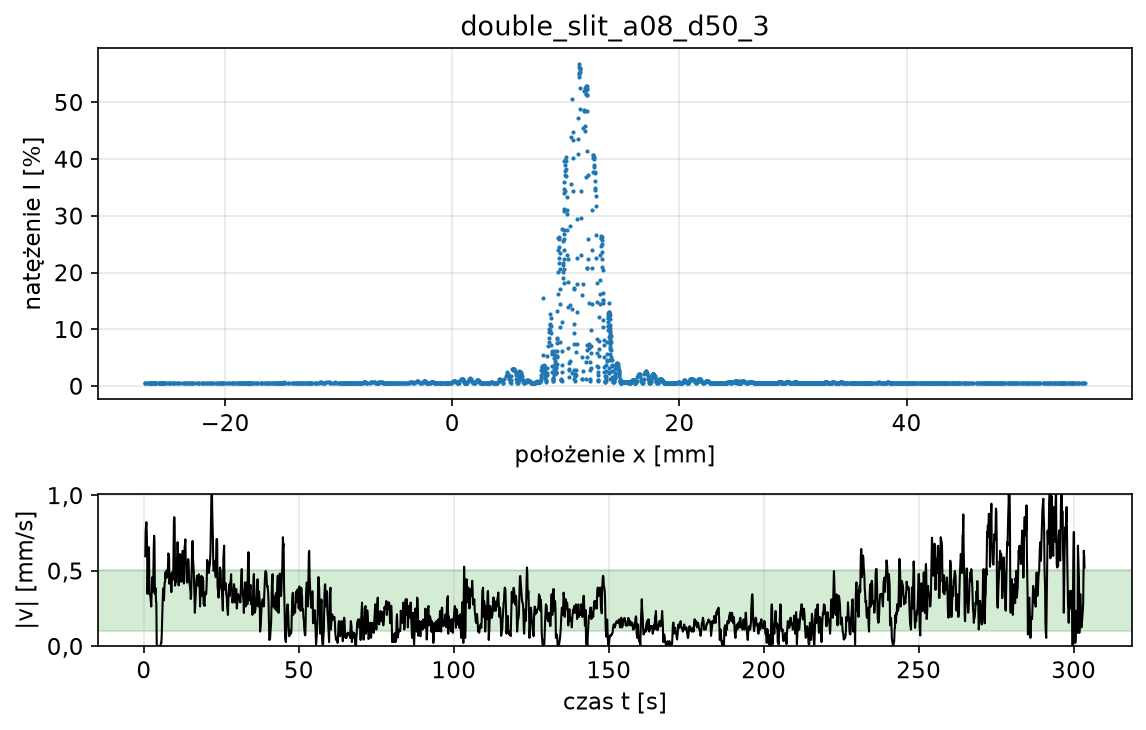

zapisano red/double_slit_a08_d50_3.csv (2127 pkt, x: -27.0 … 55.7 mm, zakończono zawrotem; odcięto 4 pkt ustawiania/powrotu)


In [ ]:
meta_B4 = dict(part='double_slit', N=2, a_nom=0.08, d_nom=0.5, D=D_UST, u_D=U_D,
               aperture='', notes='')
B4 = seria('double_slit_a08_d50', meta_B4, n=3)

[1] d ≈ λD/Δy = 0.8862 mm   (Δy ≈ 0.65 mm, orientacyjnie)
[2] d ≈ λD/Δy = 0.8471 mm   (Δy ≈ 0.68 mm, orientacyjnie)
[3] d ≈ λD/Δy = 0.9000 mm   (Δy ≈ 0.64 mm, orientacyjnie)
d: średnia z 3 przejazdów = 0.8777 mm, rozrzut σ = 0.0275 mm


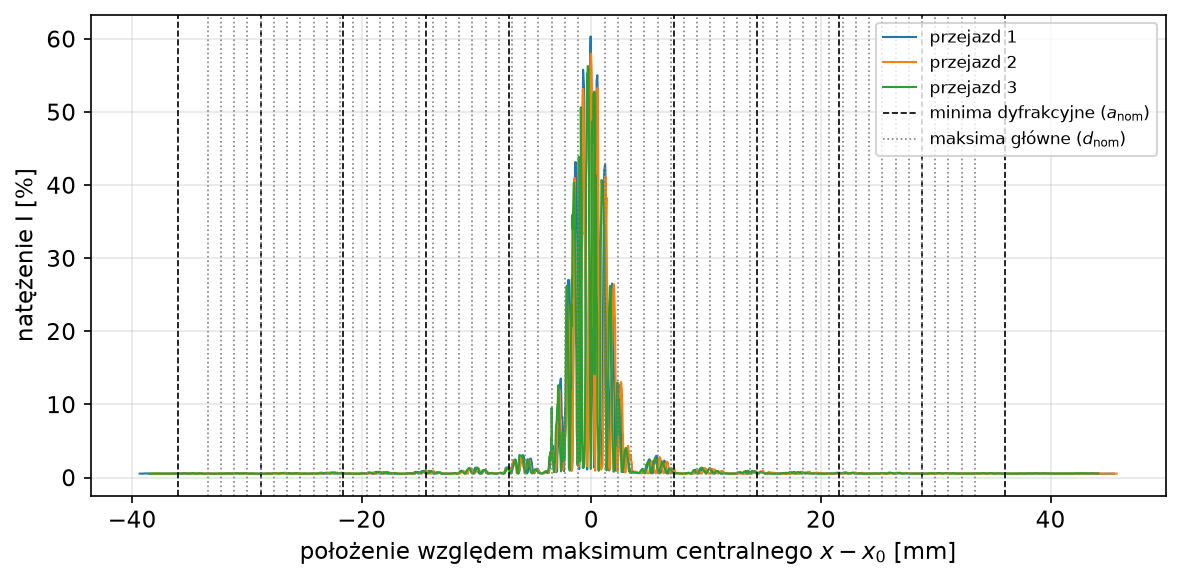

In [ ]:
_ = podglad(B4, meta_B4, krok=0.02)

## Część C — układy $N$ szczelin

Oprawa z układami $N = 2, 3, 4, 5$ szczelin, $a = 0{,}04$ mm, $d = 0{,}125$ mm. Część jakościowa:
zaobserwować, jak ze wzrostem $N$ zmienia się **szerokość i natężenie maksimów głównych** oraz **liczba maksimów
pobocznych** ($N-2$ między sąsiednimi maksimami głównymi). Położenia maksimów głównych ($\lambda D/d$)
i minimów obwiedni ($\lambda D/a$) nie powinny zależeć od $N$.

Maksima poboczne są słabe (dla $N = 5$ rzędu kilku % maksimum głównego) i leżą co $\lambda D/(Nd)$ —
tu potrzebne jest najwolniejsze skanowanie i niskie tło. Podgląd liczy maksima poboczne między
maksimum centralnym a pierwszym maksimum głównym po każdej stronie.

Obserwacje (do wypełnienia w laboratorium):

- …

### C1 — $N = 2$

— przejazd 1/3


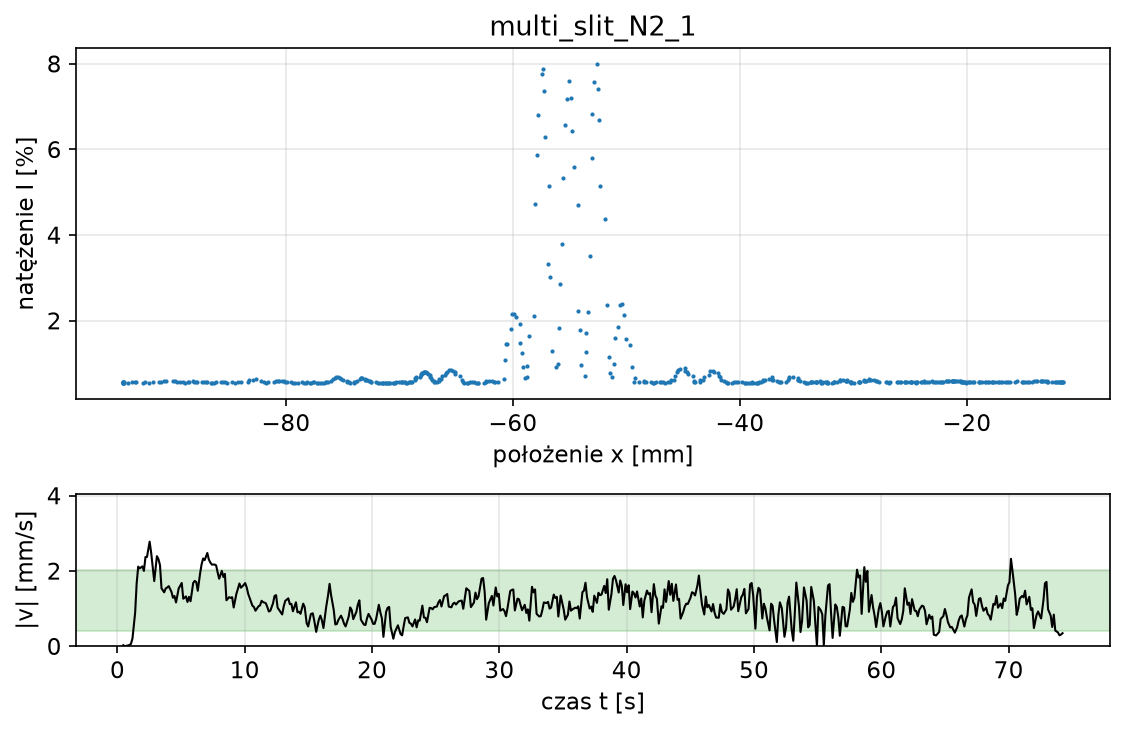

zapisano red/multi_slit_N2_1.csv (521 pkt, x: -94.3 … -11.6 mm, zakończono zawrotem; odcięto 5 pkt ustawiania/powrotu)
— przejazd 2/3: jechać z powrotem


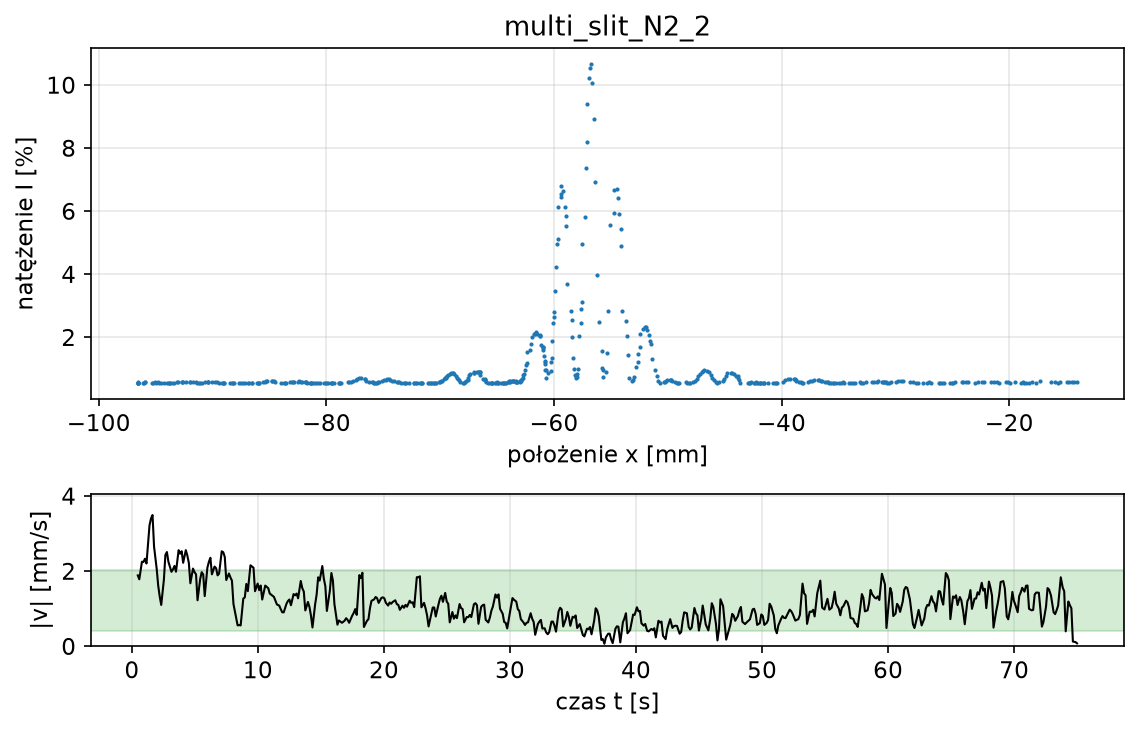

zapisano red/multi_slit_N2_2.csv (527 pkt, x: -96.6 … -14.0 mm, zakończono zawrotem; odcięto 10 pkt ustawiania/powrotu)
— przejazd 3/3: jechać z powrotem


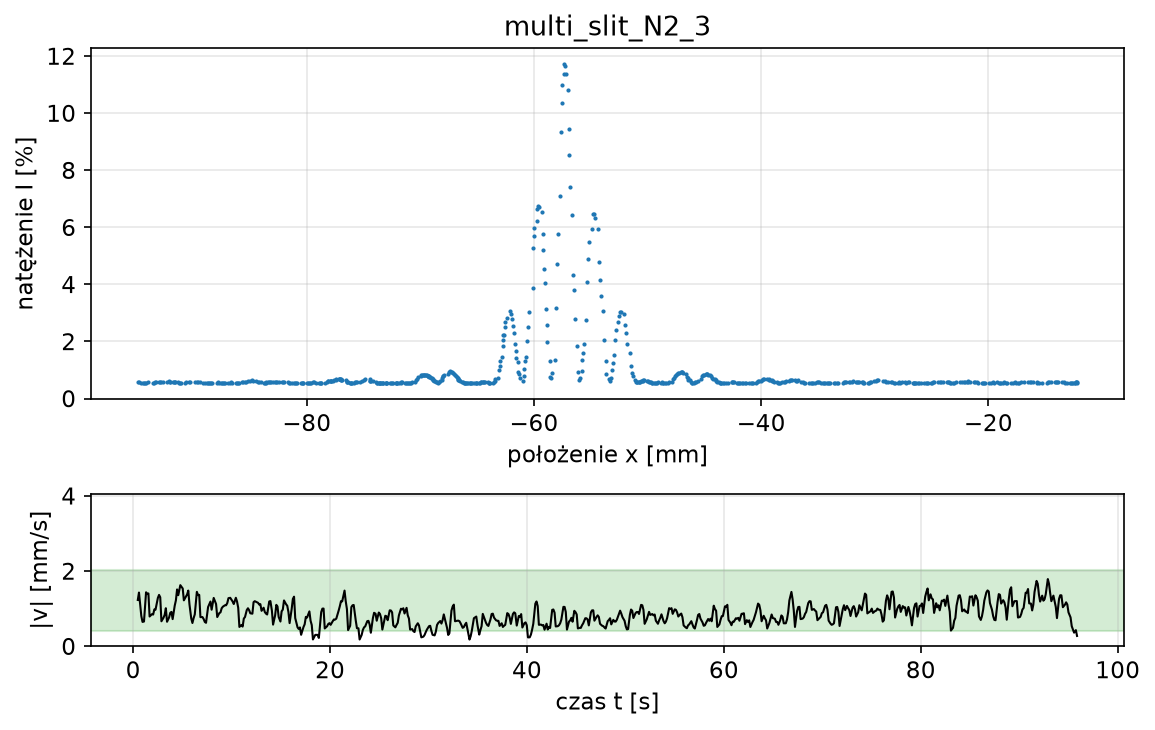

zapisano red/multi_slit_N2_3.csv (674 pkt, x: -94.9 … -12.2 mm, zakończono zawrotem; odcięto 6 pkt ustawiania/powrotu)


In [19]:
meta_C2 = dict(part='multi_slit', N=2, a_nom=0.04, d_nom=0.125, D=D_UST, u_D=U_D,
               aperture='', notes='')
C2 = seria('multi_slit_N2', meta_C2, n=3)

[1] d ≈ λD/Δy = 0.2430 mm   (Δy ≈ 2.37 mm, orientacyjnie)
[2] d ≈ λD/Δy = 0.2420 mm   (Δy ≈ 2.38 mm, orientacyjnie)
[3] d ≈ λD/Δy = 0.2420 mm   (Δy ≈ 2.38 mm, orientacyjnie)
d: średnia z 3 przejazdów = 0.2424 mm, rozrzut σ = 0.0006 mm


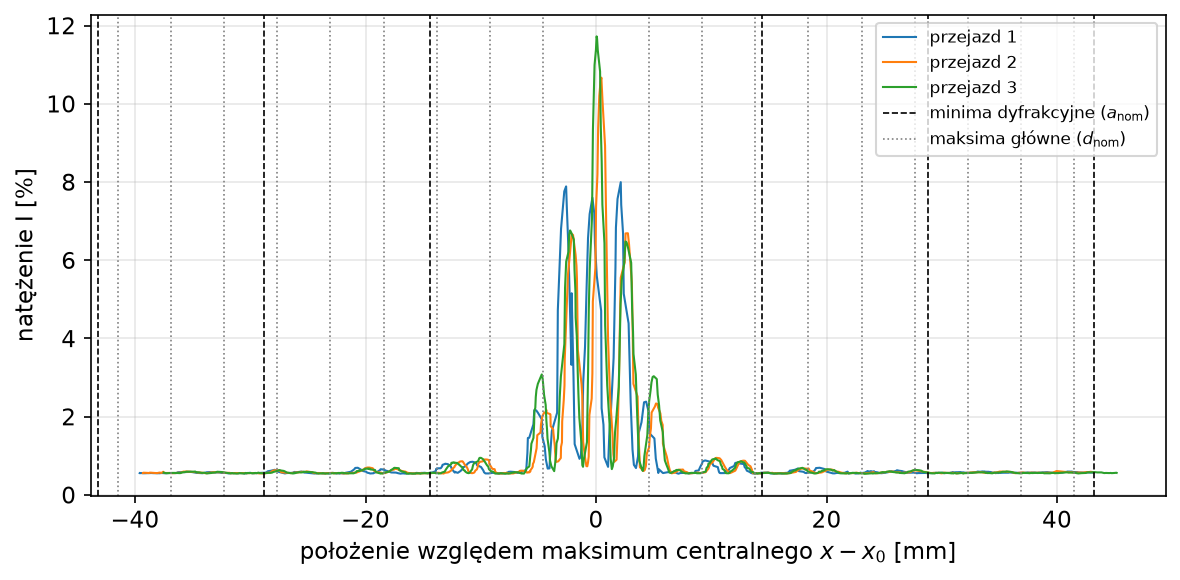

In [20]:
_ = podglad(C2, meta_C2, krok=0.02)

### C2 — $N = 3$

— przejazd 1/3


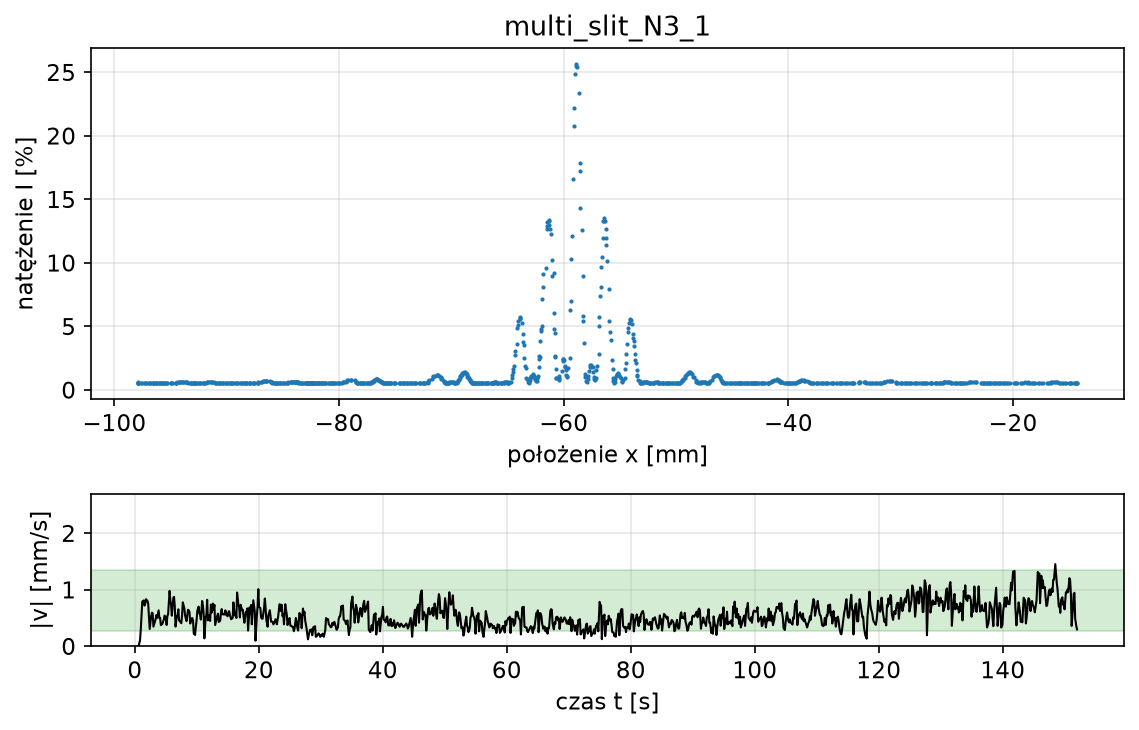

zapisano red/multi_slit_N3_1.csv (1066 pkt, x: -97.9 … -14.3 mm, zakończono zawrotem; odcięto 17 pkt ustawiania/powrotu)
— przejazd 2/3: jechać z powrotem


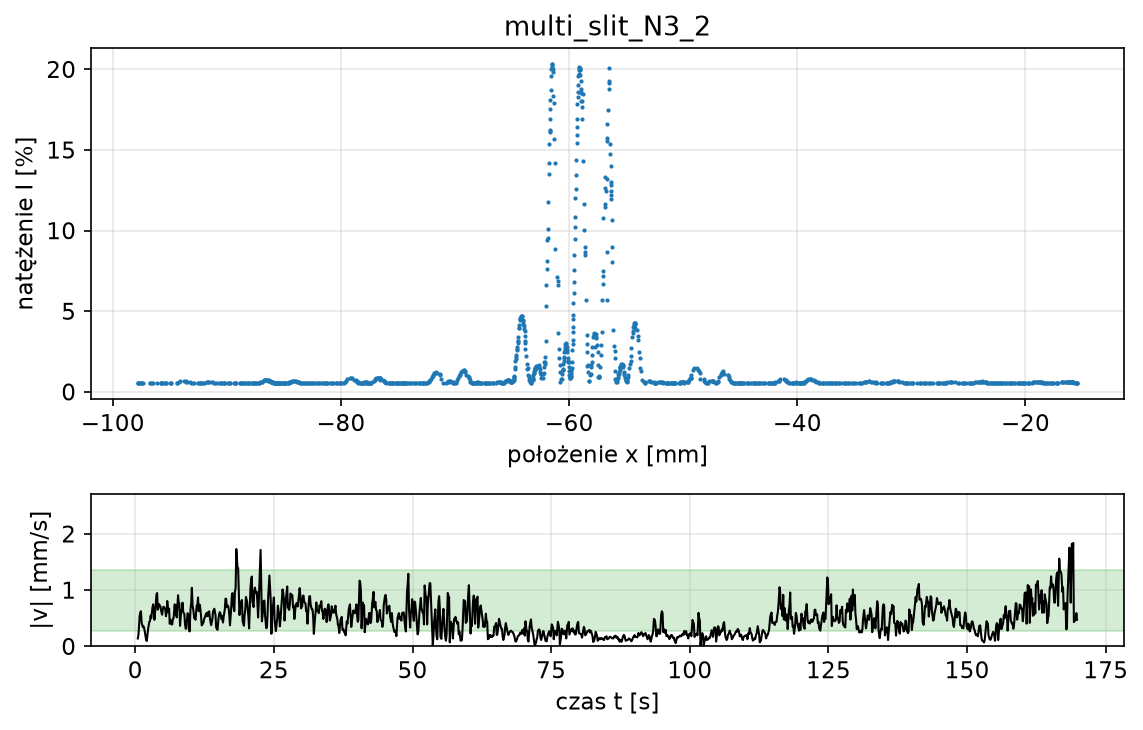

zapisano red/multi_slit_N3_2.csv (1197 pkt, x: -97.8 … -15.5 mm, zakończono zawrotem; odcięto 6 pkt ustawiania/powrotu)
— przejazd 3/3: jechać z powrotem


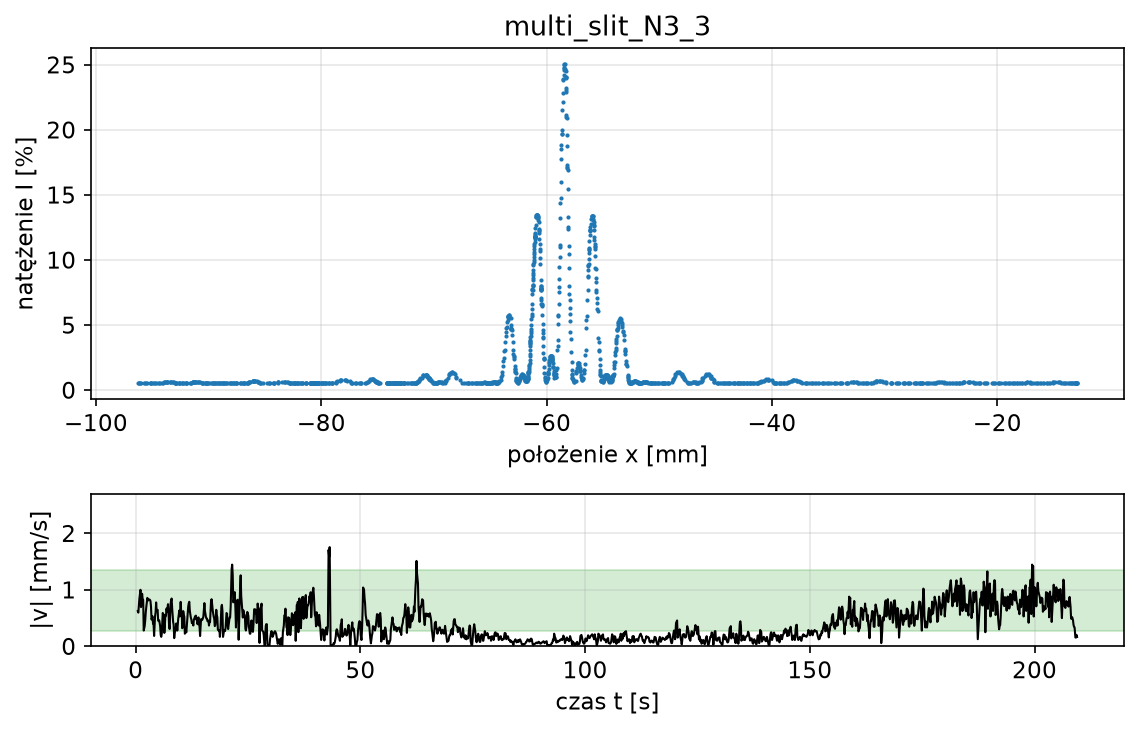

zapisano red/multi_slit_N3_3.csv (1470 pkt, x: -96.3 … -12.9 mm, zakończono zawrotem; odcięto 8 pkt ustawiania/powrotu)


In [29]:
meta_C3 = dict(part='multi_slit', N=3, a_nom=0.04, d_nom=0.125, D=D_UST, u_D=U_D,
               aperture='', notes='')
C3 = seria('multi_slit_N3', meta_C3, n=3)

[1] d ≈ λD/Δy = 0.2341 mm   (Δy ≈ 2.46 mm, orientacyjnie)
[1] maksima poboczne między maksimami głównymi: ← 3 / 3 →  (oczekiwane N − 2 = 1)
[2] d ≈ λD/Δy = 0.2313 mm   (Δy ≈ 2.49 mm, orientacyjnie)
[2] maksima poboczne między maksimami głównymi: ← 3 / 3 →  (oczekiwane N − 2 = 1)
[3] d ≈ λD/Δy = 0.2332 mm   (Δy ≈ 2.47 mm, orientacyjnie)
[3] maksima poboczne między maksimami głównymi: ← 3 / 3 →  (oczekiwane N − 2 = 1)
d: średnia z 3 przejazdów = 0.2329 mm, rozrzut σ = 0.0014 mm


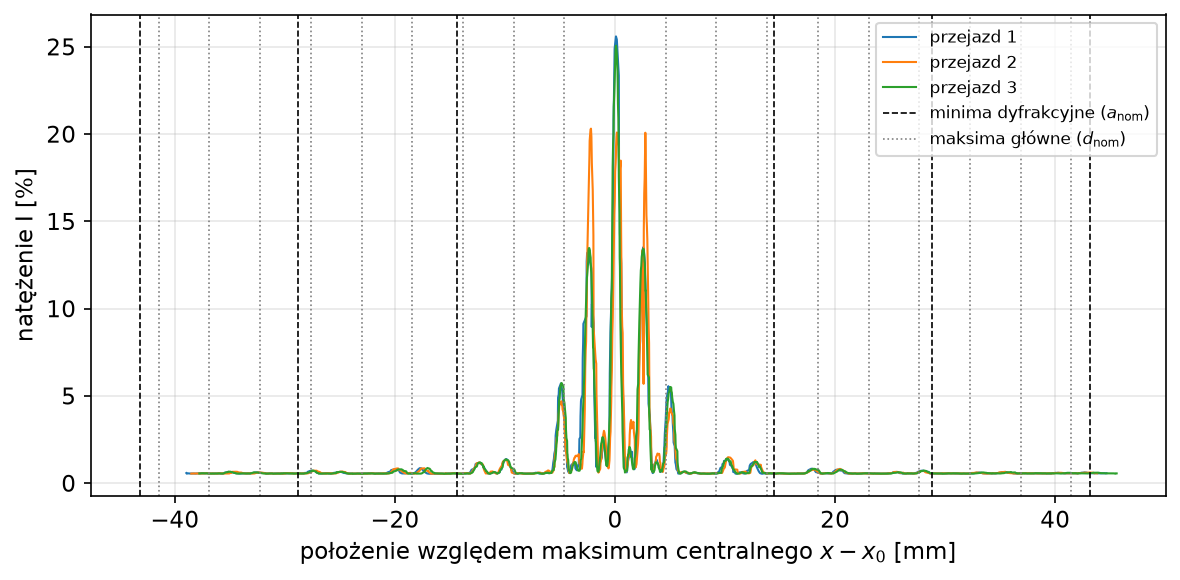

In [30]:
_ = podglad(C3, meta_C3, krok=0.02)

### C3 — $N = 4$

— przejazd 1/3


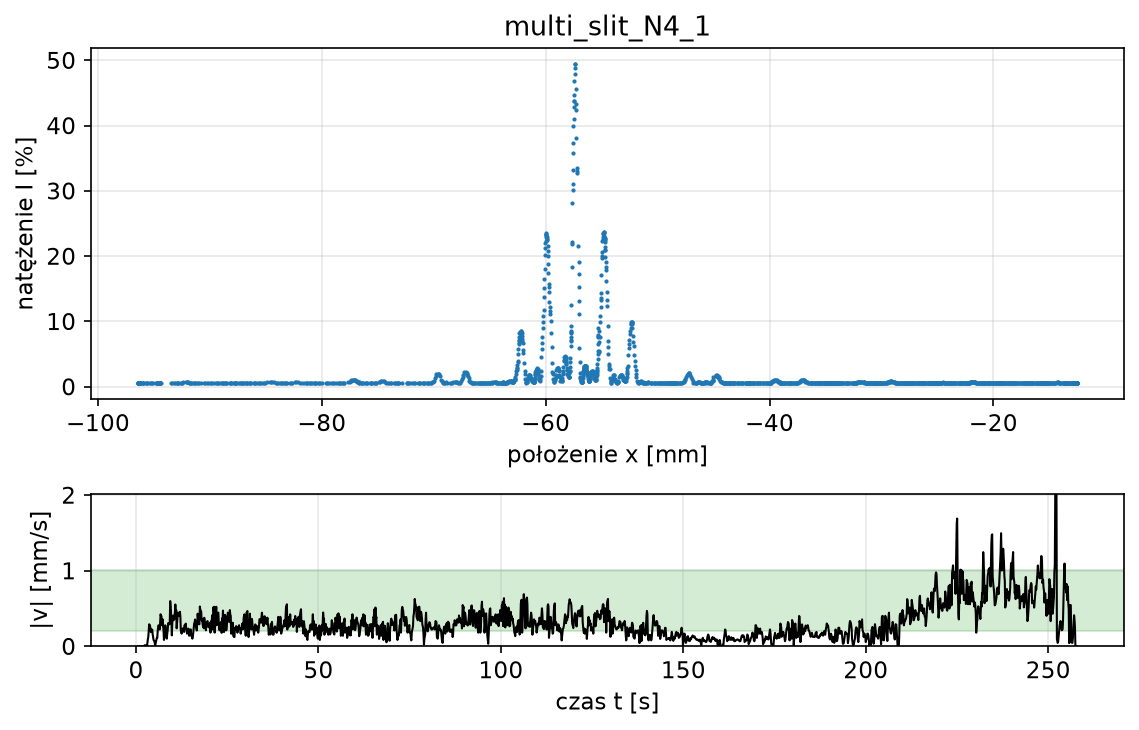

zapisano red/multi_slit_N4_1.csv (1802 pkt, x: -96.4 … -12.5 mm, zakończono zawrotem; odcięto 33 pkt ustawiania/powrotu)
— przejazd 2/3: jechać z powrotem


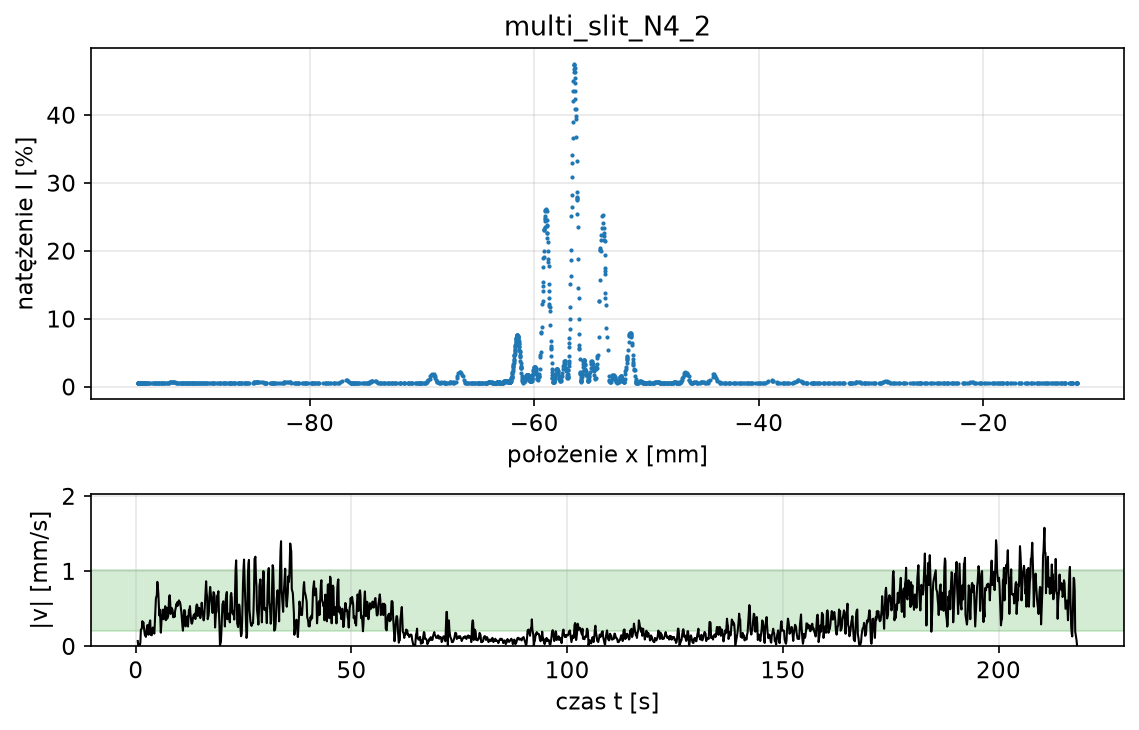

zapisano red/multi_slit_N4_2.csv (1536 pkt, x: -95.3 … -11.7 mm, zakończono zawrotem; odcięto 18 pkt ustawiania/powrotu)
— przejazd 3/3: jechać z powrotem


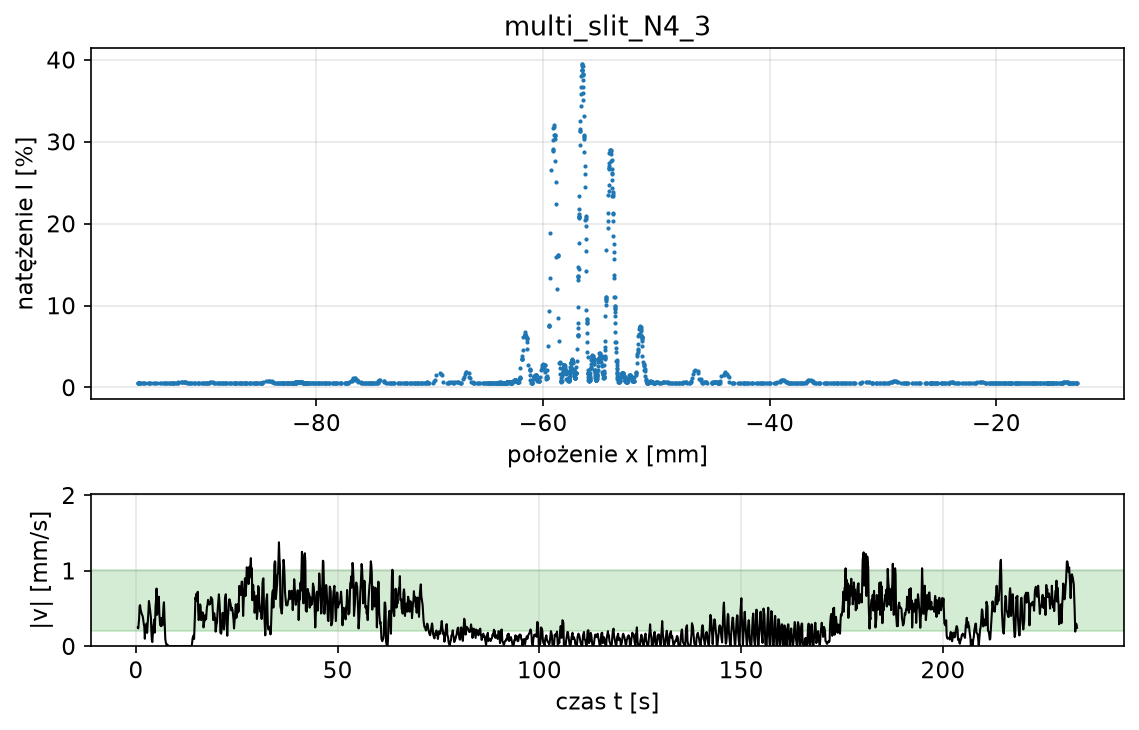

zapisano red/multi_slit_N4_3.csv (1633 pkt, x: -95.8 … -12.9 mm, zakończono zawrotem; odcięto 7 pkt ustawiania/powrotu)


In [31]:
meta_C4 = dict(part='multi_slit', N=4, a_nom=0.04, d_nom=0.125, D=D_UST, u_D=U_D,
               aperture='', notes='')
C4 = seria('multi_slit_N4', meta_C4, n=3)

[1] d ≈ λD/Δy = 0.2277 mm   (Δy ≈ 2.53 mm, orientacyjnie)
[1] maksima poboczne między maksimami głównymi: ← 4 / 5 →  (oczekiwane N − 2 = 2)
[2] d ≈ λD/Δy = 0.2277 mm   (Δy ≈ 2.53 mm, orientacyjnie)
[2] maksima poboczne między maksimami głównymi: ← 5 / 4 →  (oczekiwane N − 2 = 2)
[3] d ≈ λD/Δy = 0.2277 mm   (Δy ≈ 2.53 mm, orientacyjnie)
[3] maksima poboczne między maksimami głównymi: ← 4 / 4 →  (oczekiwane N − 2 = 2)
d: średnia z 3 przejazdów = 0.2277 mm, rozrzut σ = 0.0000 mm


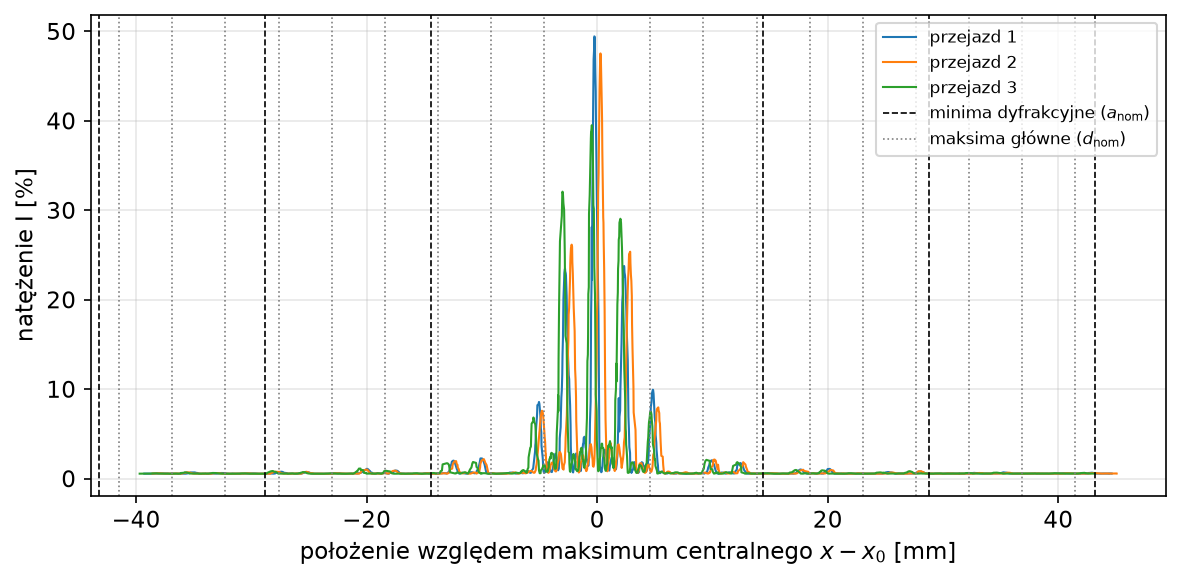

In [32]:
_ = podglad(C4, meta_C4, krok=0.02)

### C4 — $N = 5$

— przejazd 1/3


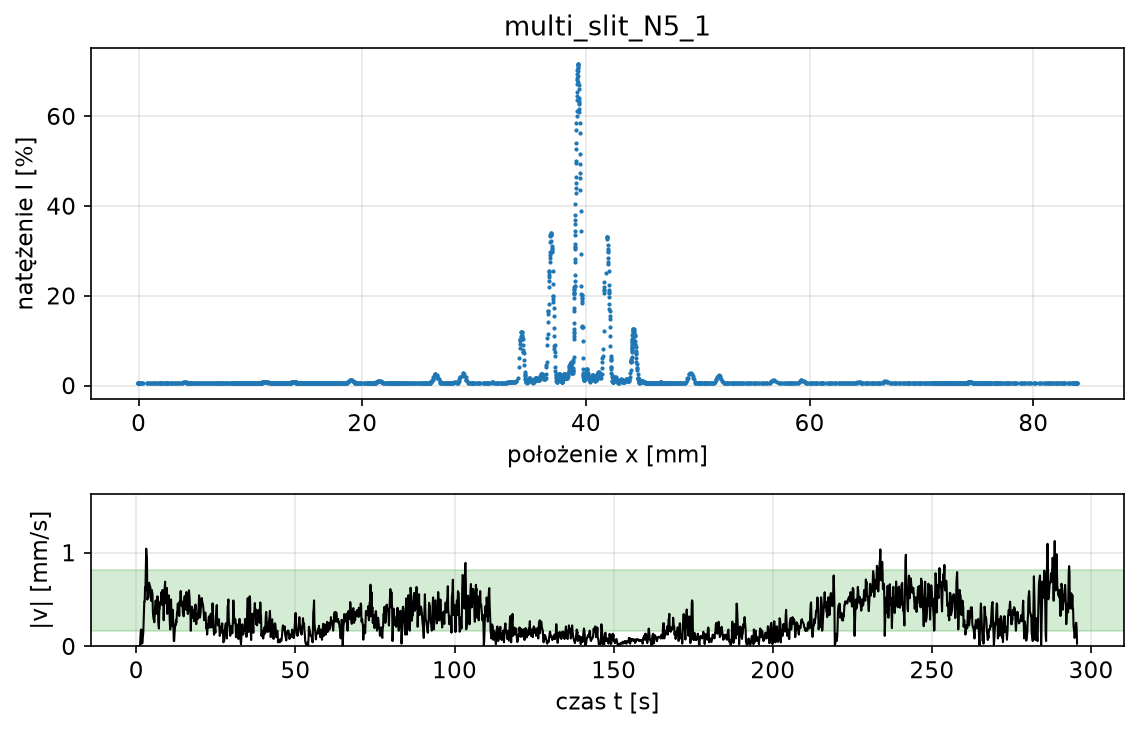

zapisano red/multi_slit_N5_1.csv (2085 pkt, x: -0.1 … 83.9 mm, zakończono zawrotem; odcięto 30 pkt ustawiania/powrotu)
— przejazd 2/3: jechać z powrotem


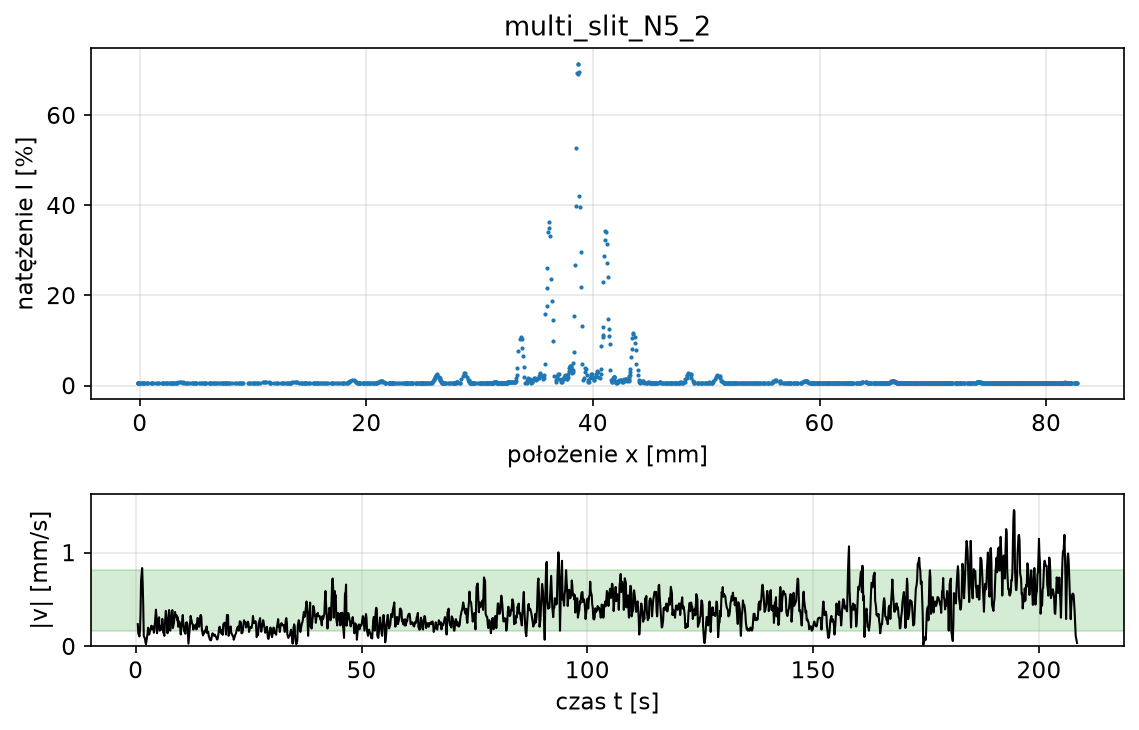

zapisano red/multi_slit_N5_2.csv (1469 pkt, x: -0.2 … 82.7 mm, zakończono zawrotem; odcięto 18 pkt ustawiania/powrotu)
— przejazd 3/3: jechać z powrotem


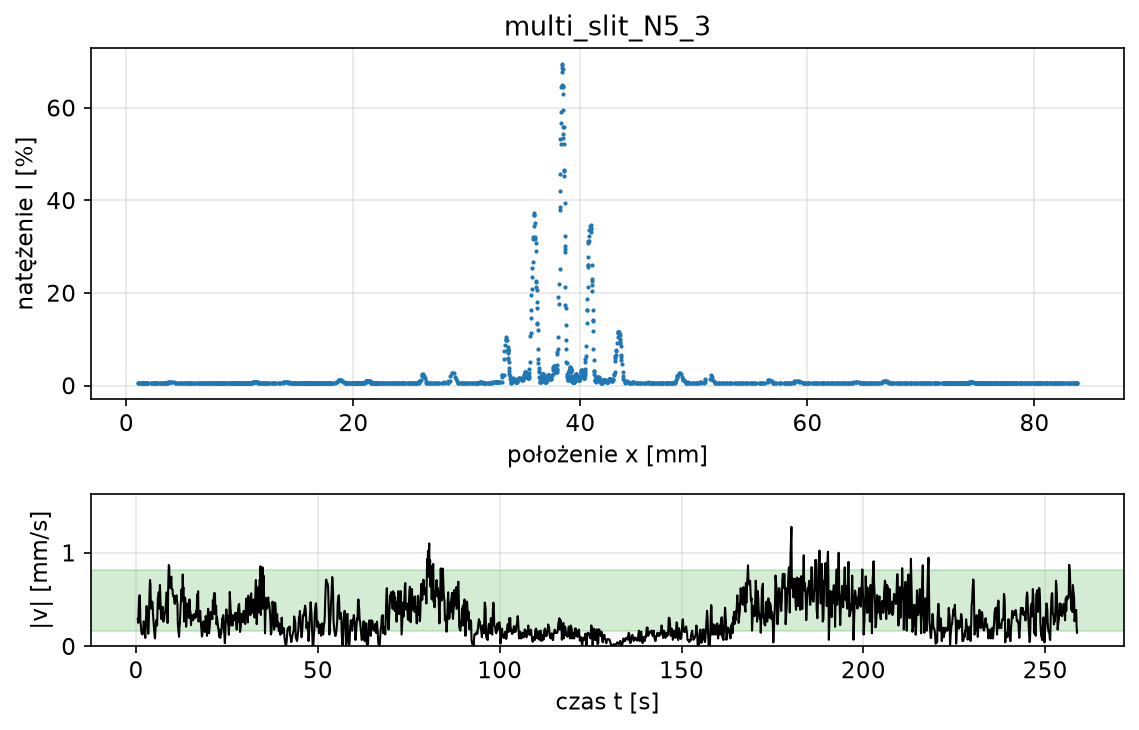

zapisano red/multi_slit_N5_3.csv (1828 pkt, x: 1.0 … 83.8 mm, zakończono zawrotem; odcięto 5 pkt ustawiania/powrotu)


In [43]:
meta_C5 = dict(part='multi_slit', N=5, a_nom=0.04, d_nom=0.125, D=D_UST, u_D=U_D,
               aperture='', notes='')
C5 = seria('multi_slit_N5', meta_C5, n=3)

[1] d ≈ λD/Δy = 0.2304 mm   (Δy ≈ 2.50 mm, orientacyjnie)
[1] maksima poboczne między maksimami głównymi: ← 6 / 6 →  (oczekiwane N − 2 = 3)
[2] d ≈ λD/Δy = 0.2313 mm   (Δy ≈ 2.49 mm, orientacyjnie)
[2] maksima poboczne między maksimami głównymi: ← 4 / 3 →  (oczekiwane N − 2 = 3)
[3] d ≈ λD/Δy = 0.2332 mm   (Δy ≈ 2.47 mm, orientacyjnie)
[3] maksima poboczne między maksimami głównymi: ← 5 / 6 →  (oczekiwane N − 2 = 3)
d: średnia z 3 przejazdów = 0.2316 mm, rozrzut σ = 0.0014 mm


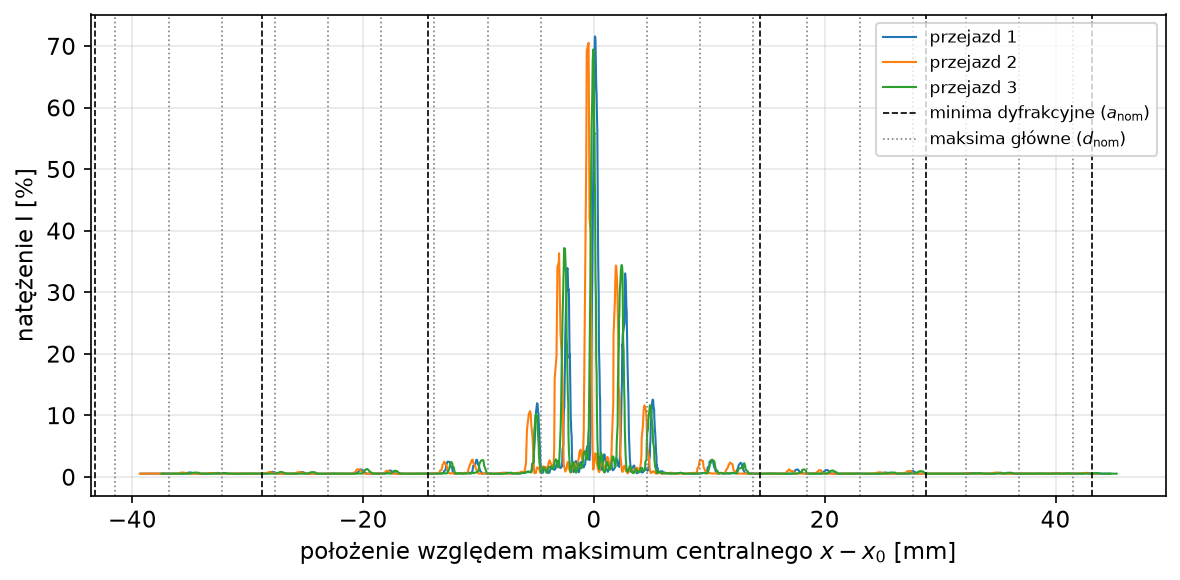

In [44]:
_ = podglad(C5, meta_C5, krok=0.02)

## Część D — zmiana odległości szczeliny od detektora

Pojedyncza szczelina $a = 0{,}02$ mm, po jednym przejeździe w trzech nowych położeniach szczelin: jednym **dalej**
od detektora (pozycja poniżej 20 cm) i dwóch **bliżej** (powyżej 20 cm). Detektor zostaje na 110 cm.
Ten układ skanuje się najszybciej: w serii A1 przejazd trwał ~18 s przy ~4,5 mm/s, bo najdrobniejsza struktura
obrazu jest największa ($\lambda D/2a \approx 14$ mm). Pomiarem odniesienia ($D = 900$ mm) jest A1.

Minima leżą w $y_m = \lambda D m/a$; skaner ma ~85 mm zakresu. Propozycje położeń (czerwony, $\lambda D/a$):

| położenie szczelin | $D$ | $\lambda D/a$ | rzędy w zakresie |
|---|---|---|---|
| 10 cm (dalej) | 1000 mm | 32 mm | $m = \pm1$ |
| 20 cm (A1) | 900 mm | 29 mm | $m = \pm1$ |
| 60 cm (bliżej) | 500 mm | 16 mm | $m = \pm1, \pm2$ |
| 70 cm (bliżej) | 400 mm | 13 mm | $m = \pm1, \pm2, \pm3$ |

Jeśli uchwyt lasera nie pozwala zejść do 10 cm, ustawić szczeliny tak daleko, jak się da. Przed każdym przejazdem
przesunąć uchwyt, **odczytać położenie ze skali** i wpisać je w komórce (mm) — trafia do rejestru (`pos_slit`),
$D$ jest liczone z niego. Na końcu części **wrócić ze szczelinami na 20 cm**.

In [31]:
def meta_odleglosc(pos_szczeliny):
    '''Opis pomiaru części D dla szczelin w położeniu pos_szczeliny [mm] na ławie.'''
    return dict(part='distance', N=1, a_nom=0.02, d_nom=None, D=POS_DETEKTOR - pos_szczeliny, u_D=U_D,
                pos_slit=pos_szczeliny, aperture='', notes='zmiana D')

### D1 — szczeliny dalej, propozycja 10 cm

D = (1000 ± 14) mm,  λD/a = 32.0 mm


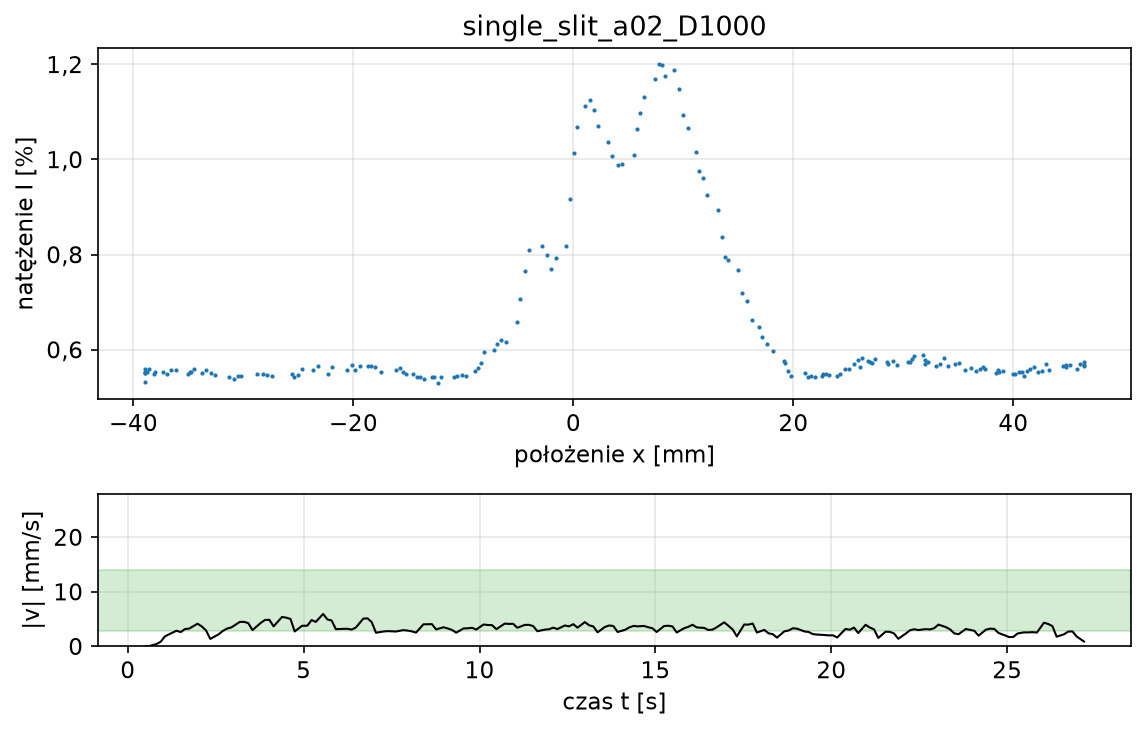

zapisano red/single_slit_a02_D1000.csv (190 pkt, x: -39.0 … 46.4 mm, zakończono zawrotem; odcięto 5 pkt ustawiania/powrotu)


In [32]:
meta_D1 = meta_odleglosc(100.0)        # położenie szczelin [mm] — wpisać odczyt ze skali
print(f'D = ({meta_D1["D"]:.0f} ± {U_D:.0f}) mm,  λD/a = {LAMBDA * meta_D1["D"] / 0.02:.1f} mm')
D1 = skanuj(f'single_slit_a02_D{meta_D1["D"]:.0f}', meta_D1)

a ≈ λD/x_1 = 0.0713 mm   (x_1 ≈ 8.97 mm, orientacyjnie)


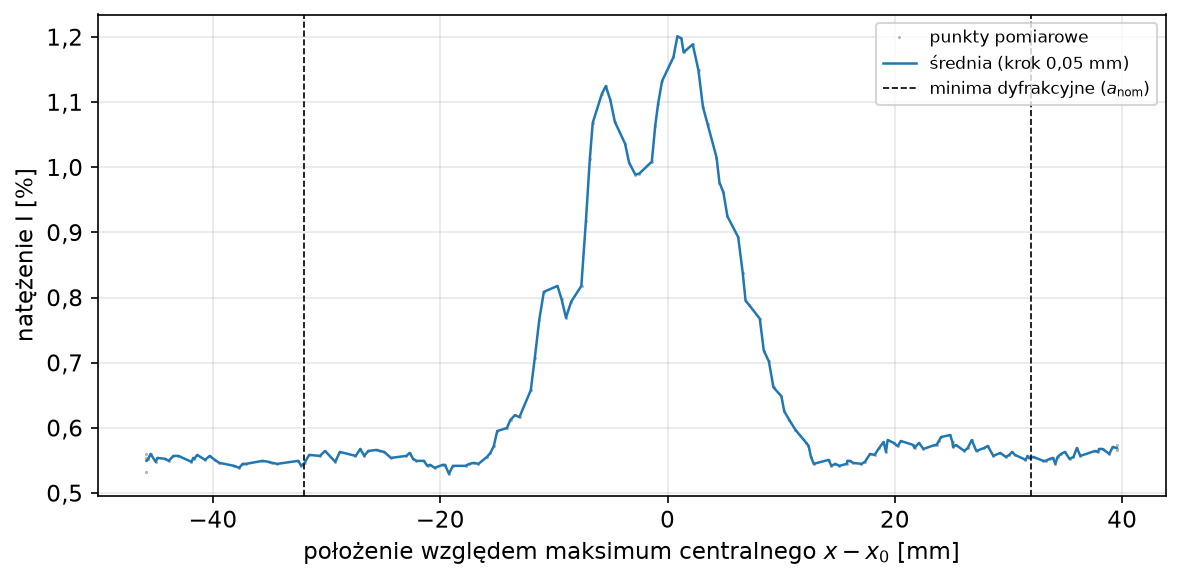

In [33]:
_ = podglad(D1, meta_D1)

### D2 — szczeliny bliżej, 60 cm

D = (500 ± 14) mm,  λD/a = 16.0 mm


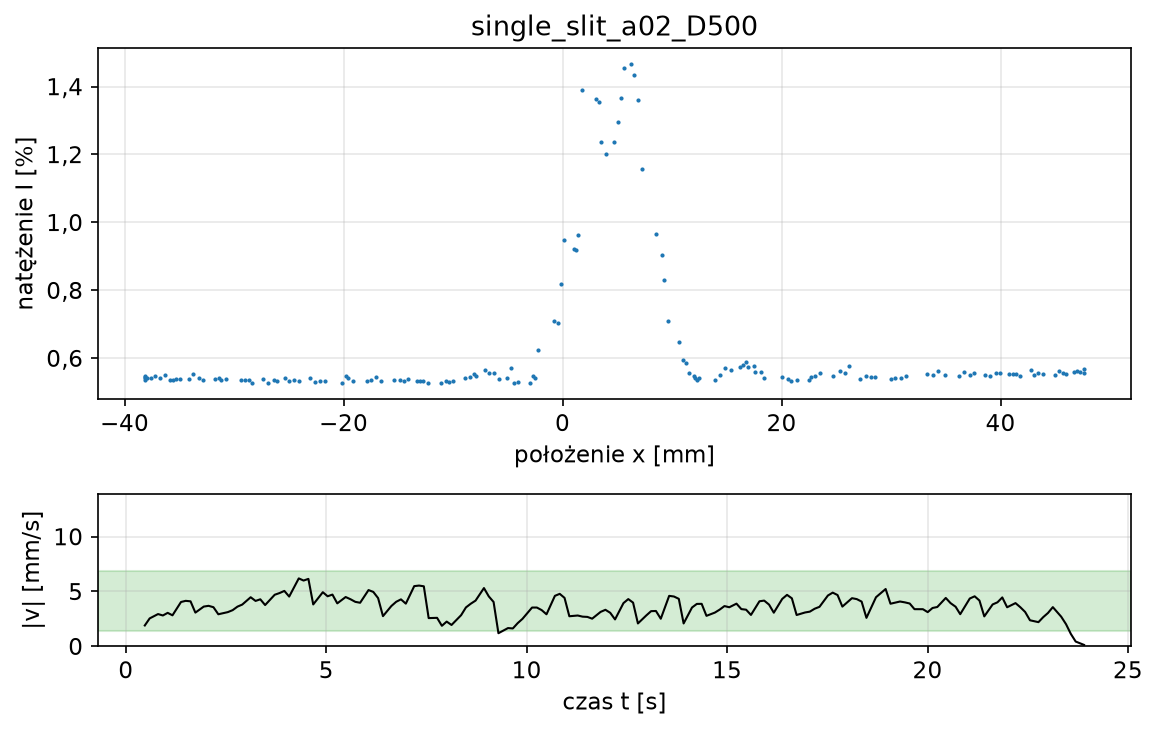

zapisano red/single_slit_a02_D500.csv (166 pkt, x: -38.2 … 47.6 mm, zakończono zawrotem; odcięto 3 pkt ustawiania/powrotu)


In [34]:
meta_D2 = meta_odleglosc(600.0)        # położenie szczelin [mm] — wpisać odczyt ze skali
print(f'D = ({meta_D2["D"]:.0f} ± {U_D:.0f}) mm,  λD/a = {LAMBDA * meta_D2["D"] / 0.02:.1f} mm')
D2 = skanuj(f'single_slit_a02_D{meta_D2["D"]:.0f}', meta_D2)

a ≈ λD/x_1 = 0.0766 mm   (x_1 ≈ 4.18 mm, orientacyjnie)


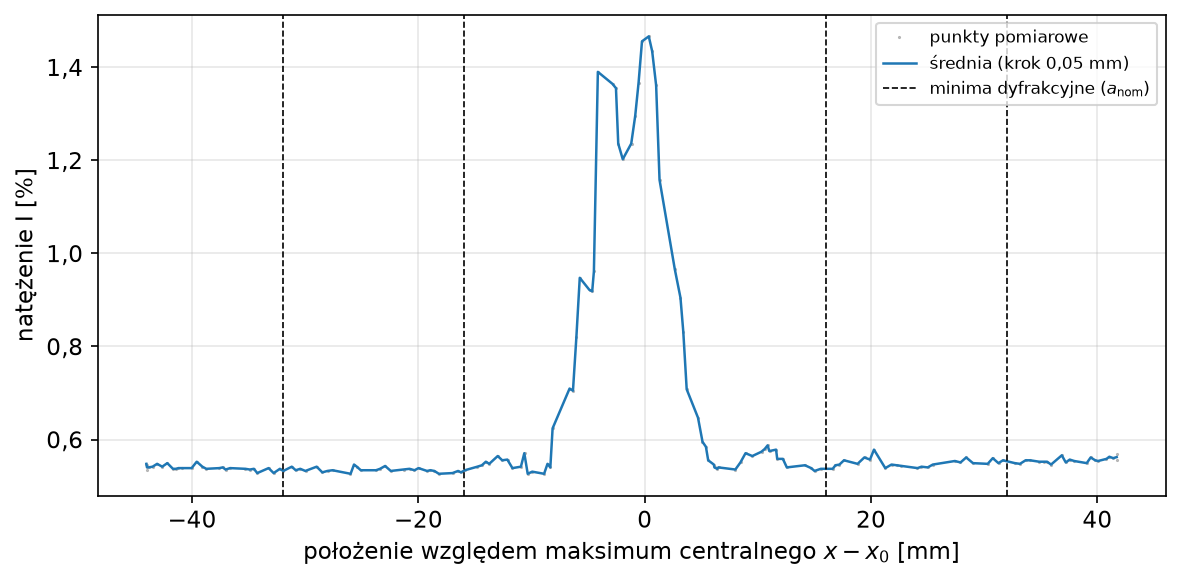

In [35]:
_ = podglad(D2, meta_D2)

### D3 — szczeliny bliżej, propozycja 70 cm

D = (400 ± 14) mm,  λD/a = 12.8 mm


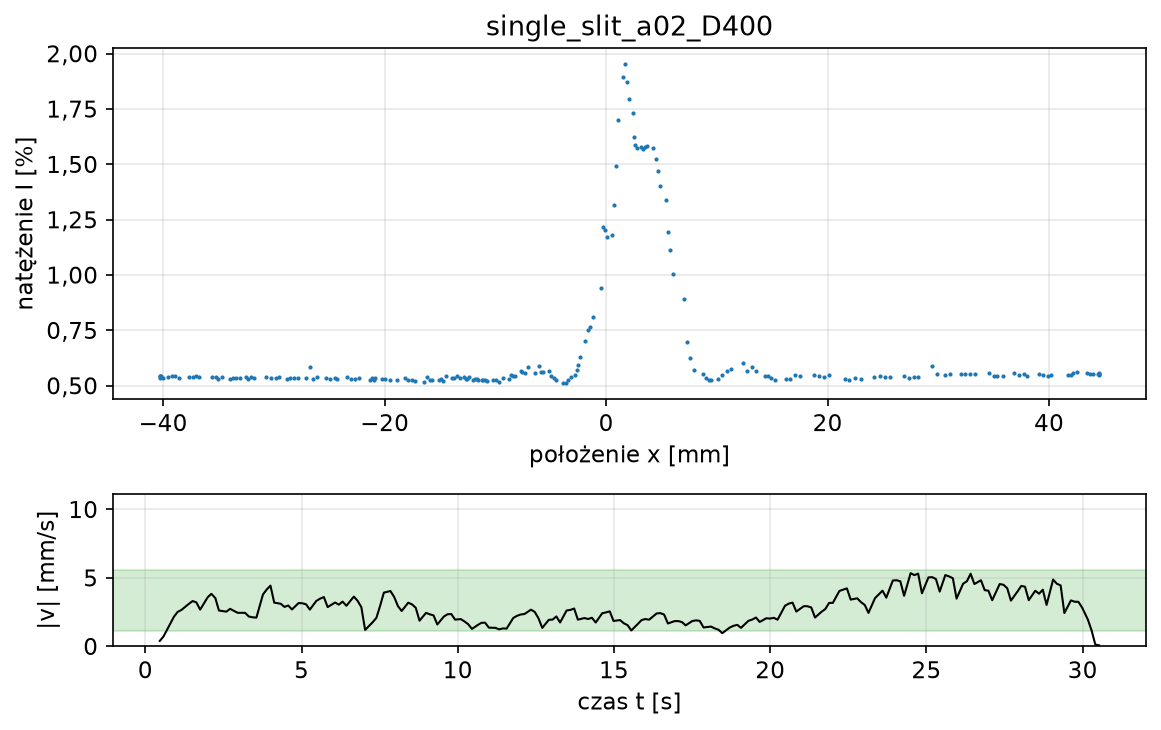

zapisano red/single_slit_a02_D400.csv (213 pkt, x: -40.3 … 44.5 mm, zakończono zawrotem; odcięto 1 pkt ustawiania/powrotu)


In [36]:
meta_D3 = meta_odleglosc(700.0)        # położenie szczelin [mm] — wpisać odczyt ze skali
print(f'D = ({meta_D3["D"]:.0f} ± {U_D:.0f}) mm,  λD/a = {LAMBDA * meta_D3["D"] / 0.02:.1f} mm')
D3 = skanuj(f'single_slit_a02_D{meta_D3["D"]:.0f}', meta_D3)

a ≈ λD/x_1 = 0.0384 mm   (x_1 ≈ 6.68 mm, orientacyjnie)


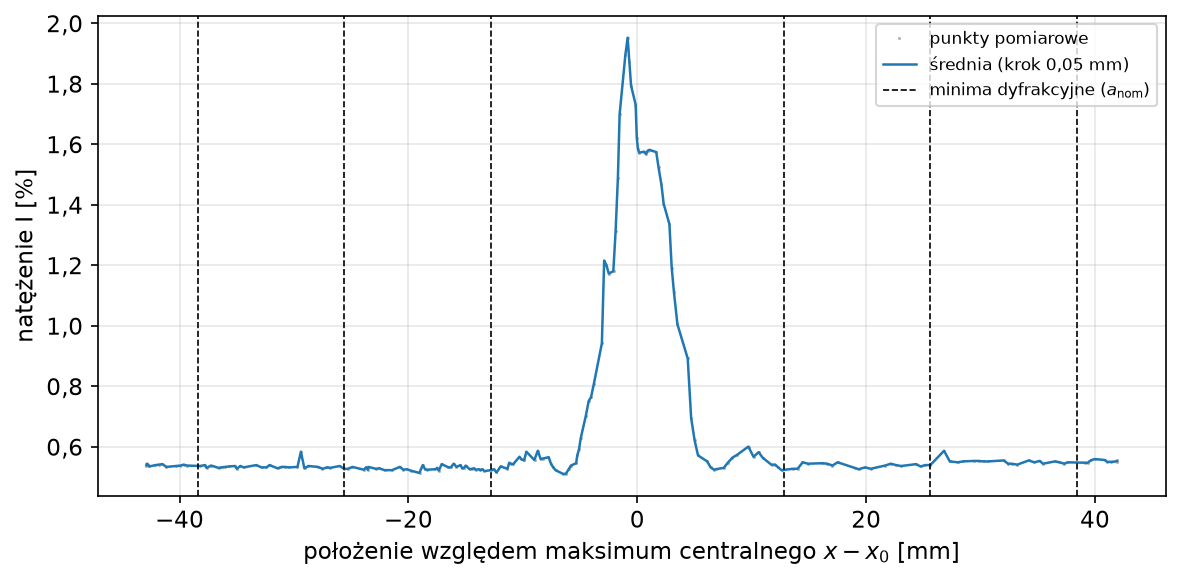

In [37]:
_ = podglad(D3, meta_D3)

## Część E — zmiana apertury czujnika

Po jednym przejeździe dla pojedynczej szczeliny $a = 0{,}04$ mm przy $D = 900$ mm (szczeliny z powrotem na 20 cm),
z **dwiema różnymi szczelinami wejściowymi czujnika** innymi niż w pozostałych skanach — najlepiej jedną węższą
i jedną szerszą od zwykłej. Pomiarem odniesienia jest A2 (czerwony);
$a = 0{,}04$ mm skanuje się szybko (~2,5 mm/s w A2), a ma kilka minimów w zakresie skanera.

Czego się spodziewać: szersza apertura zbiera więcej światła (wyższe $I$), ale uśrednia natężenie po swojej
szerokości, więc minima się spłycają; węższa — odwrotnie. Położenia minimów nie powinny się zmienić.

W każdej komórce wpisać `apertura` (opis z czujnika) i **zanotować aperturę użytą w pozostałych skanach** — w rejestrze
części A–C kolumna `aperture` jest pusta. Po pomiarze wrócić do zwykłej apertury.

**Uwaga (po pomiarze):** oba przejazdy wykonano na szczelinie $a = 0{,}02$ mm, która została w uchwycie po części D —
szerokość obrazu odpowiada A1, nie A2 (analiza w `bodo.ipynb`). Pliki przemianowano z `single_slit_a04_aperture_*`
na `single_slit_a02_aperture_*`, w `red/scans.csv` poprawiono `a_nom`; wypisy skanów niżej przeniesione bez wykresów
na żywo (miały w tytule starą nazwę), podglądy policzone od nowa z $a_\text{nom} = 0{,}02$ mm. Pomiarem odniesienia jest A1.

### E1 — pierwsza apertura

In [38]:
apertura_E1 = '0.1'           # szczelina wejściowa czujnika w tym pomiarze, np. '0.5 mm'
assert apertura_E1, 'wpisz aperturę'

meta_E1 = dict(part='aperture', N=1, a_nom=0.04, d_nom=None, D=D_UST, u_D=U_D,
               aperture=apertura_E1, notes='zmiana apertury; odniesienie: single_slit_a04')
E1 = skanuj('single_slit_a04_aperture_' + apertura_E1.replace(' ', '').replace('.', ''), meta_E1)

zapisano red/single_slit_a02_aperture_01.csv (645 pkt, x: -37.4 … 46.0 mm, zakończono zawrotem; odcięto 5 pkt ustawiania/powrotu)


a ≈ λD/x_1 = 0.0618 mm   (x_1 ≈ 9.32 mm, orientacyjnie)


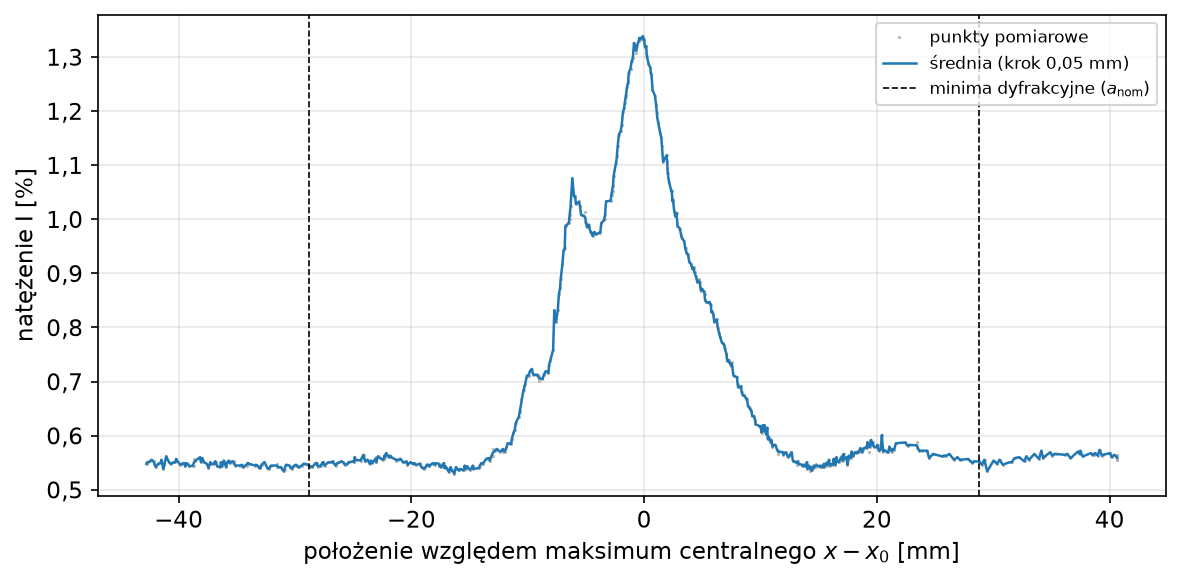

In [39]:
_ = podglad(E1, meta_E1)

### E2 — druga apertura

In [40]:
apertura_E2 = '1.5'           # szczelina wejściowa czujnika w tym pomiarze, np. '0.5 mm'
assert apertura_E2, 'wpisz aperturę'

meta_E2 = dict(part='aperture', N=1, a_nom=0.04, d_nom=None, D=D_UST, u_D=U_D,
               aperture=apertura_E2, notes='zmiana apertury; odniesienie: single_slit_a04')
E2 = skanuj('single_slit_a04_aperture_' + apertura_E2.replace(' ', '').replace('.', ''), meta_E2)

zapisano red/single_slit_a02_aperture_15.csv (815 pkt, x: -31.7 … 48.7 mm, zakończono zawrotem; odcięto 2 pkt ustawiania/powrotu)


a ≈ λD/x_1 = 0.0748 mm   (x_1 ≈ 7.70 mm, orientacyjnie)


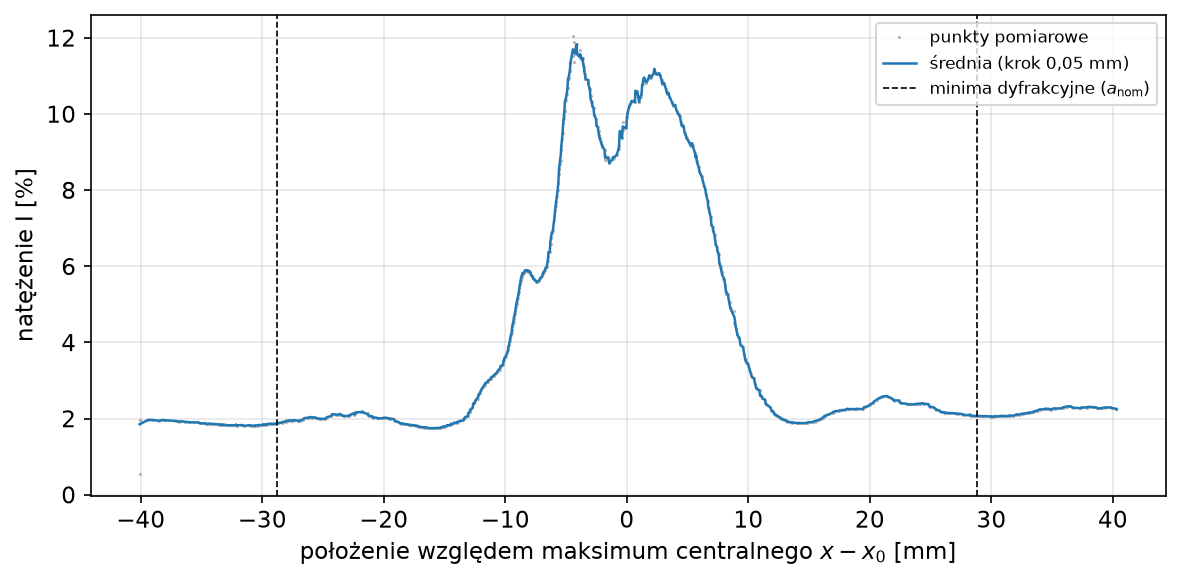

In [41]:
_ = podglad(E2, meta_E2)

# Laser zielony

Wymienić laser na zielony, ustawić na ekranie ostry, symetryczny obraz (szczeliny na **20 cm**, zwykła apertura)
Długość fali z tabliczki lasera: 515 nm (wpisana w `LASERY['green']`). Dane trafiają do `green/`, z tymi samymi nazwami plików co w `red/`.
Zakres zredukowany: A $a = 0{,}04;\ 0{,}08$ mm, B $a = 0{,}08$ mm z $d = 0{,}25;\ 0{,}50$ mm, C $N = 4$.
Wartości oczekiwane są ~0,80 razy mniejsze niż dla czerwonego ($\lambda D/a \approx 12$ mm dla $a = 0{,}04$ mm).

In [ ]:
ustaw_laser('green')

laser: red, λ = (640 ± 10) nm  [skrypt O18 — sprawdzić tabliczkę lasera]
D = (900 ± 14) mm,  dane → red/


### Pomiar tła (zielony)

Jak dla czerwonego: laser zasłonięty, jeden przejazd przez całą oś.

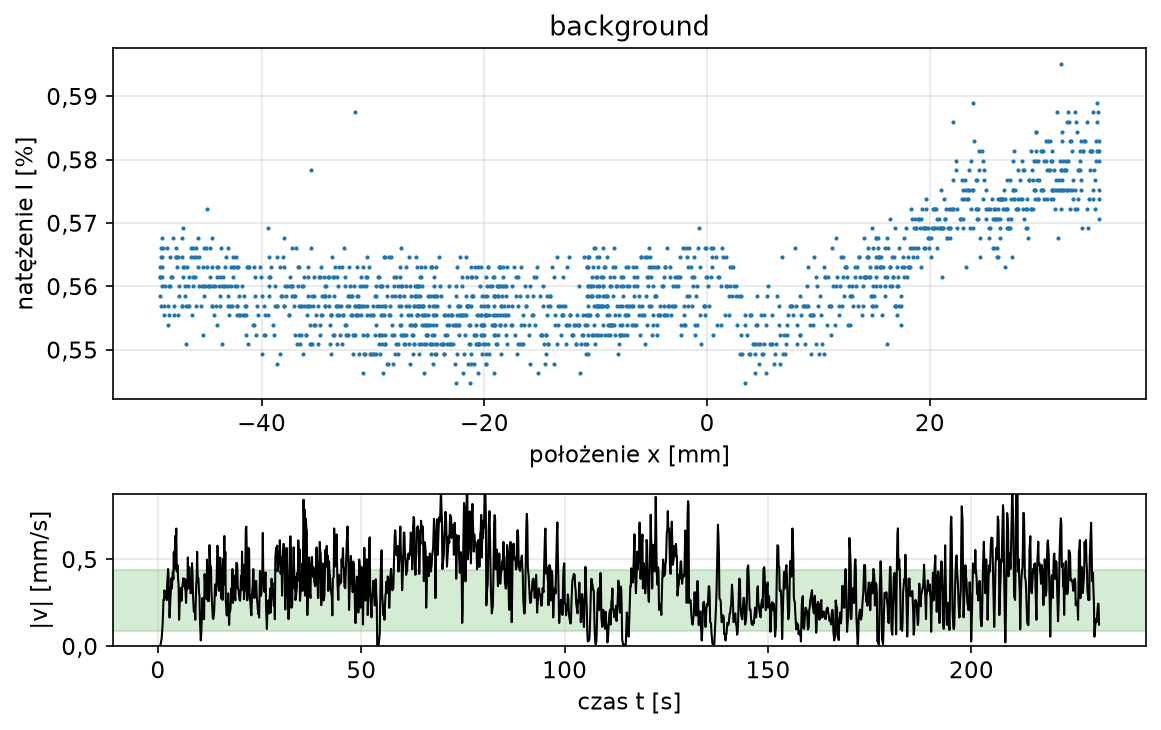

zapisano green/background.csv (1620 pkt, x: -49.1 … 35.2 mm, zakończono zawrotem; odcięto 9 pkt ustawiania/powrotu)
I_tło = 0.56 %, σ = 0.01 %


In [55]:
meta_tlo_g = dict(part='background', N=0, a_nom=None, d_nom=None, D=None, u_D=None,
                  aperture='', notes='laser zasłonięty')
tlo_g = skanuj('background', meta_tlo_g)
print(f'I_tło = {tlo_g["I"].mean():.2f} %, σ = {tlo_g["I"].std():.2f} %')

### A — pojedyncza szczelina, $a = 0,04$ mm (zielony)

— przejazd 1/3


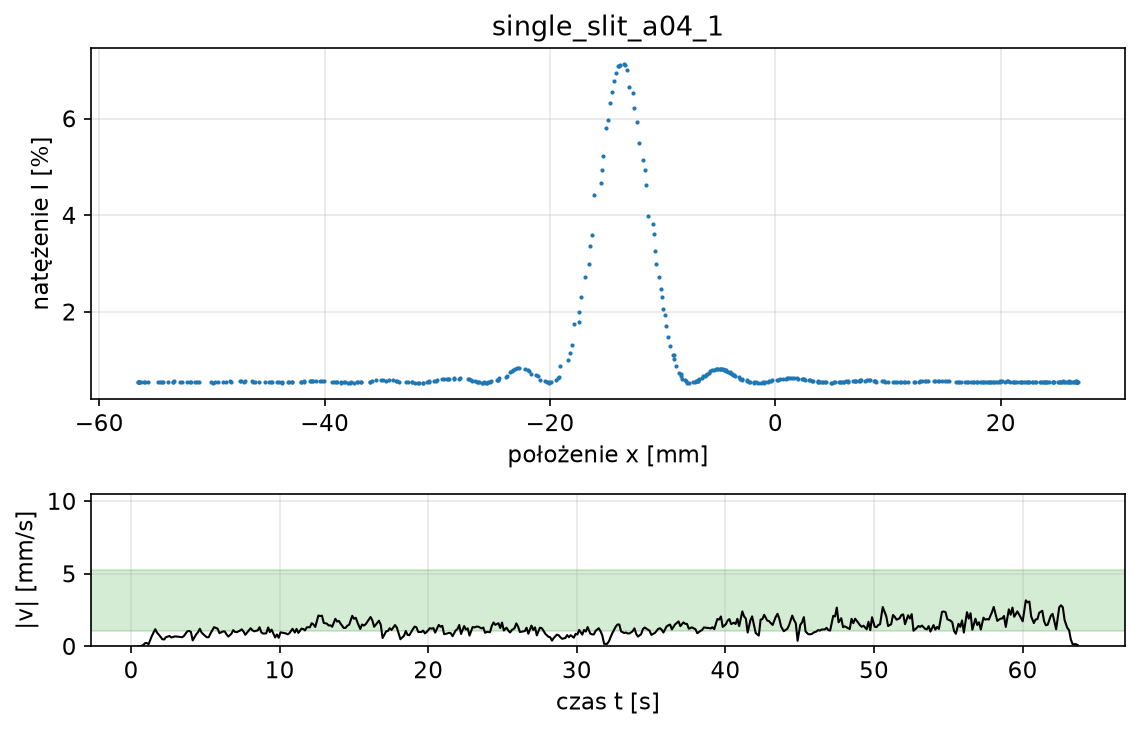

zapisano green/single_slit_a04_1.csv (447 pkt, x: -56.5 … 26.8 mm, zakończono zawrotem; odcięto 6 pkt ustawiania/powrotu)
— przejazd 2/3: jechać z powrotem


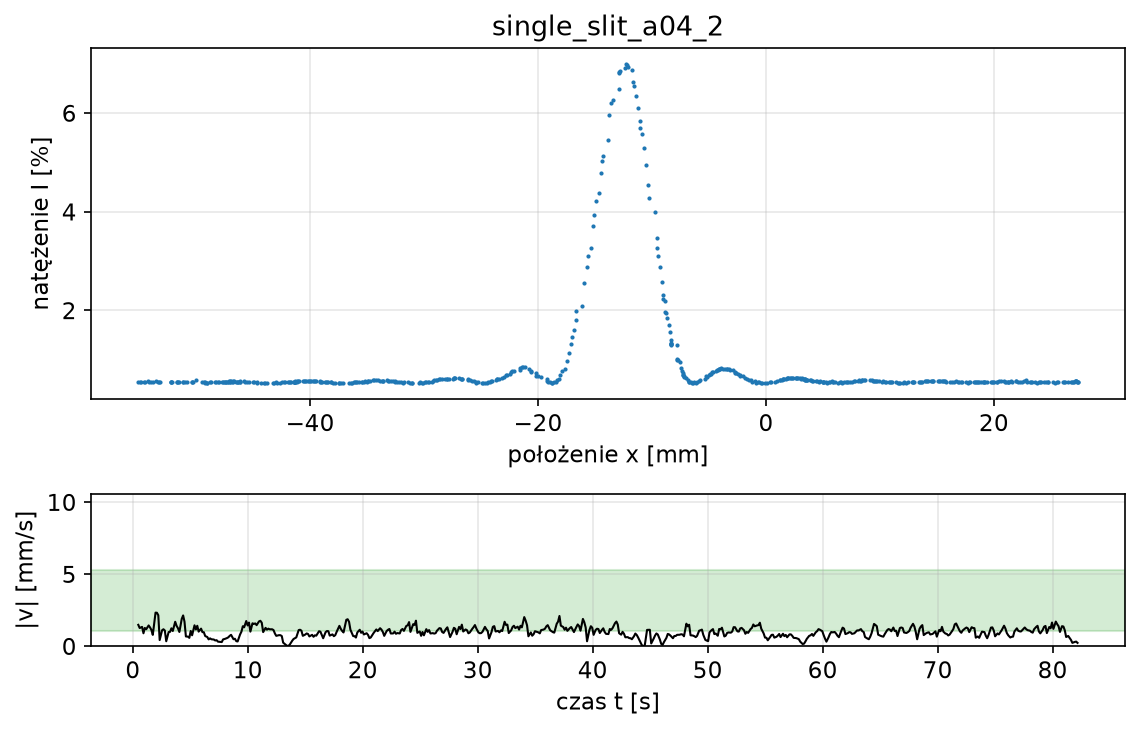

zapisano green/single_slit_a04_2.csv (580 pkt, x: -55.1 … 27.3 mm, zakończono zawrotem; odcięto 9 pkt ustawiania/powrotu)
— przejazd 3/3: jechać z powrotem


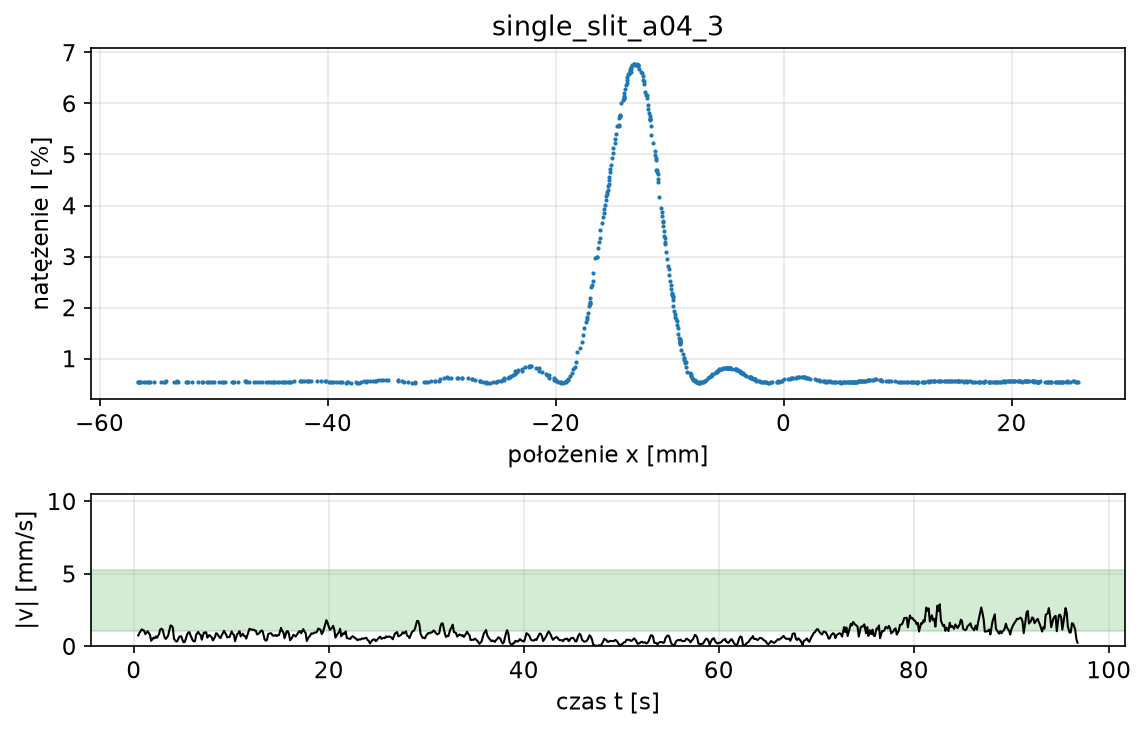

zapisano green/single_slit_a04_3.csv (680 pkt, x: -56.6 … 25.8 mm, zakończono zawrotem; odcięto 3 pkt ustawiania/powrotu)


In [9]:
meta_A2_g = dict(part='single_slit', N=1, a_nom=0.04, d_nom=None, D=D_UST, u_D=U_D,
                 aperture='', notes='')
A2_g = seria('single_slit_a04', meta_A2_g, n=3)

[1] a ≈ λD/x_1 = 0.0748 mm   (x_1 ≈ 6.40 mm, orientacyjnie)
[2] a ≈ λD/x_1 = 0.0775 mm   (x_1 ≈ 6.17 mm, orientacyjnie)
[3] a ≈ λD/x_1 = 0.0791 mm   (x_1 ≈ 6.05 mm, orientacyjnie)
a: średnia z 3 przejazdów = 0.0772 mm, rozrzut σ = 0.0022 mm


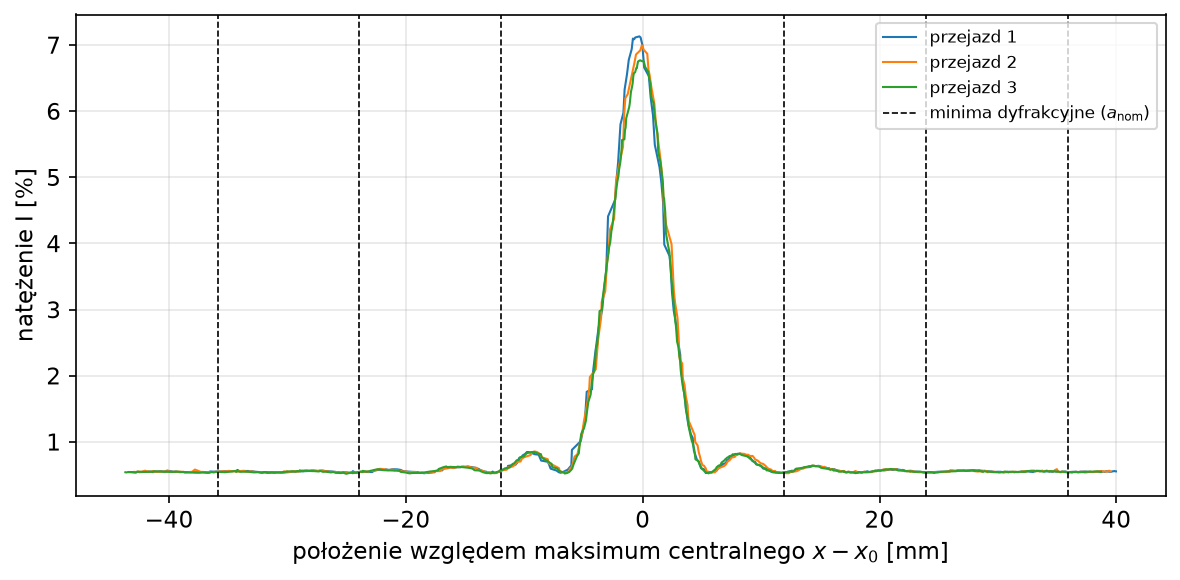

In [10]:
_ = podglad(A2_g, meta_A2_g)

### A — pojedyncza szczelina, $a = 0,08$ mm (zielony)

Pomiar wykonano omyłkowo w komórce dla $a = 0{,}04$ mm (3 listopada, 9:52–9:54). Pliki przemianowano
z `single_slit_a04_*` na `single_slit_a08_*`, w `green/scans.csv` poprawiono `a_nom`; wypis skanu poniżej
przeniesiony z tamtej komórki (bez wykresów na żywo — miały w tytule starą nazwę), podgląd policzony
od nowa z $a_\text{nom} = 0{,}08$ mm.

In [56]:
meta_A3_g = dict(part='single_slit', N=1, a_nom=0.08, d_nom=None, D=D_UST, u_D=U_D,
                 aperture='', notes='')
A3_g = seria('single_slit_a08', meta_A3_g, n=3)

— przejazd 1/3


zapisano green/single_slit_a08_1.csv (781 pkt, x: -49.9 … 34.3 mm, zakończono zawrotem; odcięto 6 pkt ustawiania/powrotu)
— przejazd 2/3: jechać z powrotem


zapisano green/single_slit_a08_2.csv (372 pkt, x: -49.7 … 32.8 mm, zakończono zawrotem; odcięto 8 pkt ustawiania/powrotu)
— przejazd 3/3: jechać z powrotem


zapisano green/single_slit_a08_3.csv (790 pkt, x: -48.3 … 35.6 mm, zakończono zawrotem; odcięto 5 pkt ustawiania/powrotu)


[1] a ≈ λD/x_1 = 0.1520 mm   (x_1 ≈ 3.15 mm, orientacyjnie)
[2] a ≈ λD/x_1 = 0.1473 mm   (x_1 ≈ 3.25 mm, orientacyjnie)
[3] a ≈ λD/x_1 = 0.1508 mm   (x_1 ≈ 3.17 mm, orientacyjnie)
a: średnia z 3 przejazdów = 0.1500 mm, rozrzut σ = 0.0024 mm


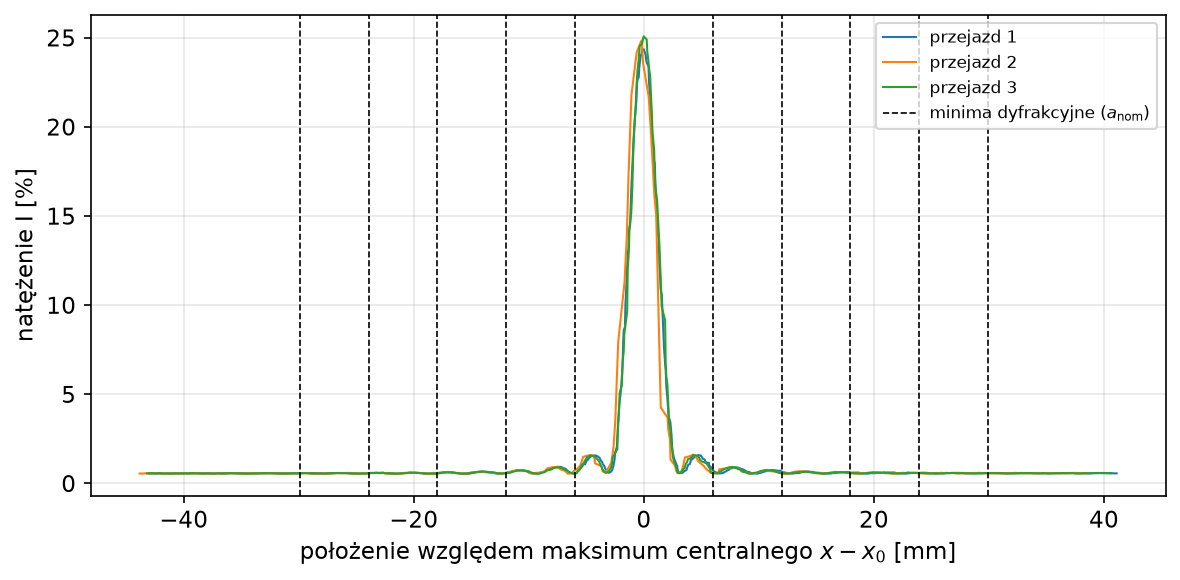

In [57]:
_ = podglad(A3_g, meta_A3_g)

### B — dwie szczeliny, $a = 0,08$ mm, $d = 0,25$ mm (zielony)

— przejazd 1/3


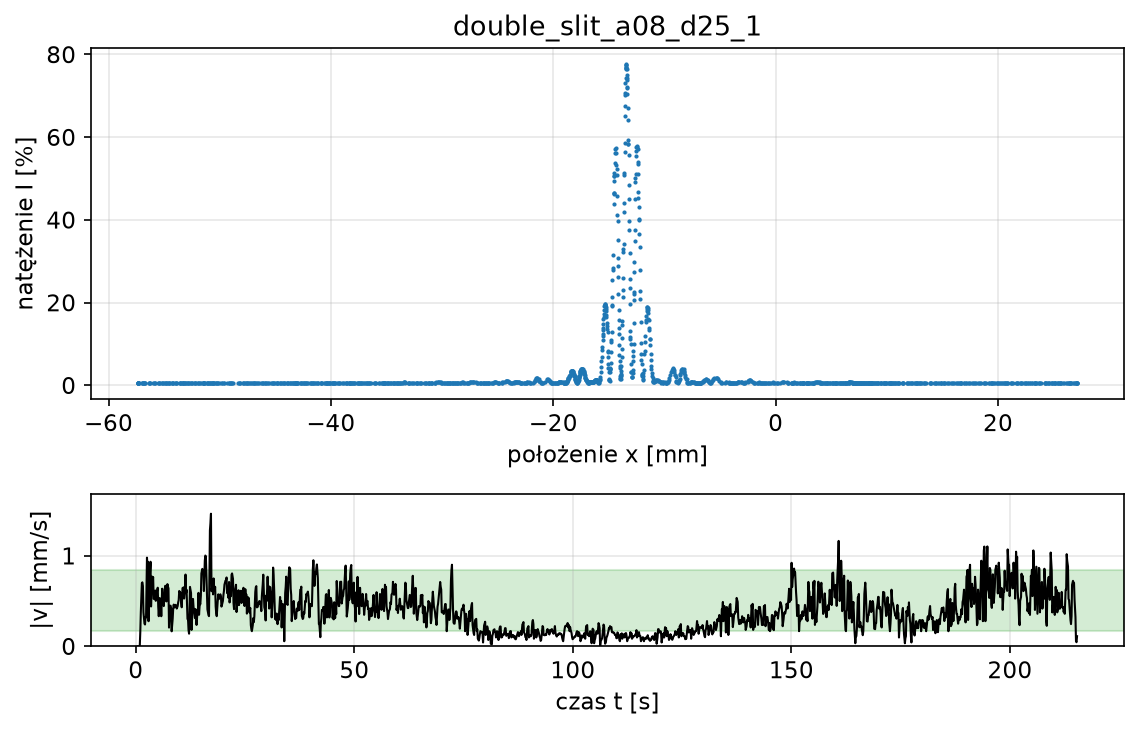

zapisano green/double_slit_a08_d25_1.csv (1513 pkt, x: -57.4 … 27.1 mm, zakończono zawrotem; odcięto 13 pkt ustawiania/powrotu)
— przejazd 2/3: jechać z powrotem


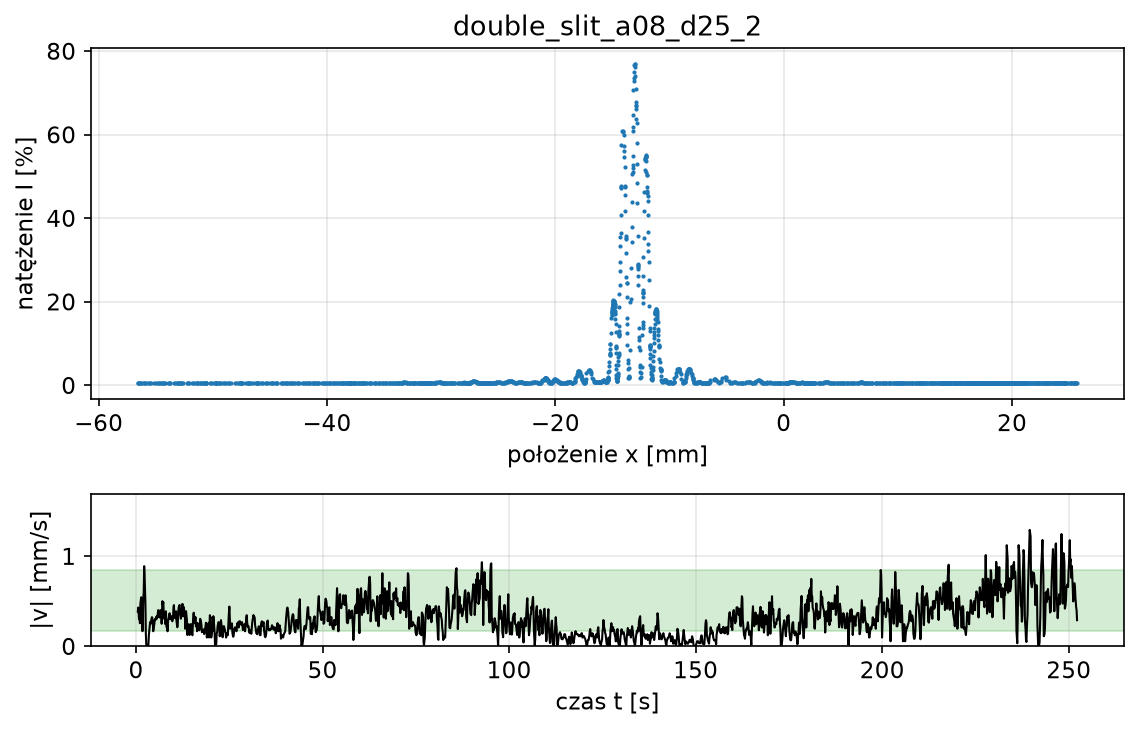

zapisano green/double_slit_a08_d25_2.csv (1780 pkt, x: -56.6 … 25.7 mm, zakończono zawrotem; odcięto 15 pkt ustawiania/powrotu)
— przejazd 3/3: jechać z powrotem


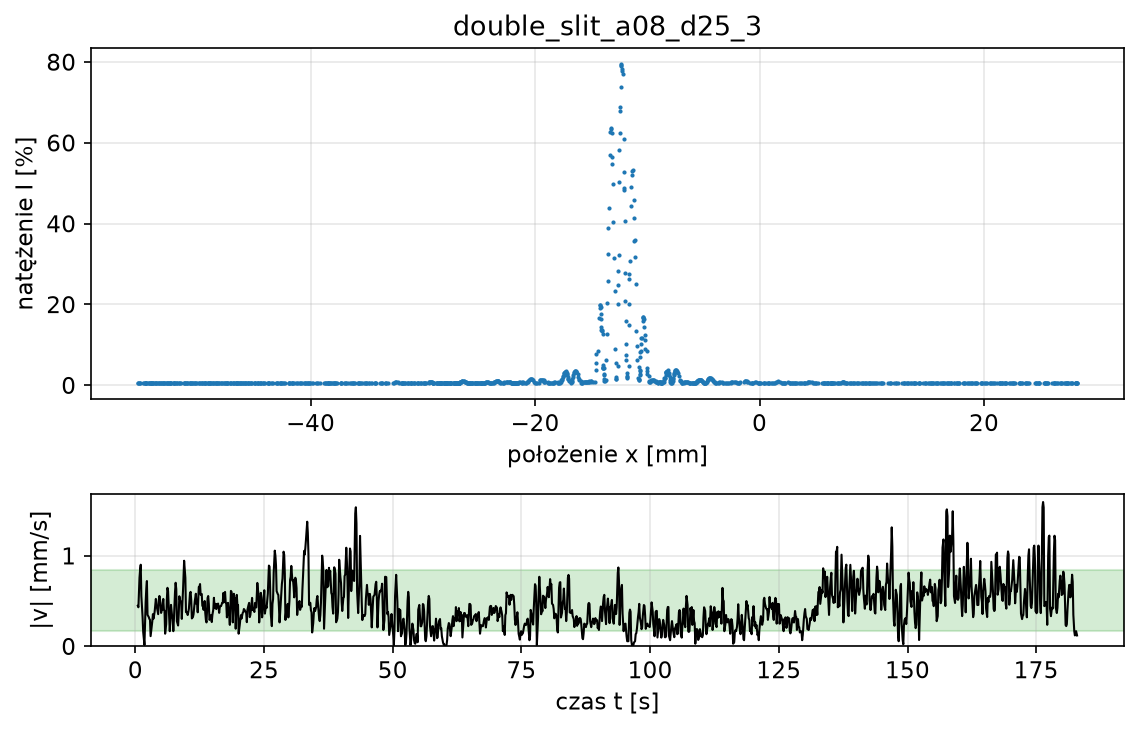

zapisano green/double_slit_a08_d25_3.csv (1285 pkt, x: -55.4 … 28.3 mm, zakończono zawrotem; odcięto 4 pkt ustawiania/powrotu)


In [11]:
meta_B3_g = dict(part='double_slit', N=2, a_nom=0.08, d_nom=0.25, D=D_UST, u_D=U_D,
                 aperture='', notes='')
B3_g = seria('double_slit_a08_d25', meta_B3_g, n=3)

[1] d ≈ λD/Δy = 0.5040 mm   (Δy ≈ 0.95 mm, orientacyjnie)
[2] d ≈ λD/Δy = 0.5204 mm   (Δy ≈ 0.92 mm, orientacyjnie)
[3] d ≈ λD/Δy = 0.5040 mm   (Δy ≈ 0.95 mm, orientacyjnie)
d: średnia z 3 przejazdów = 0.5095 mm, rozrzut σ = 0.0095 mm


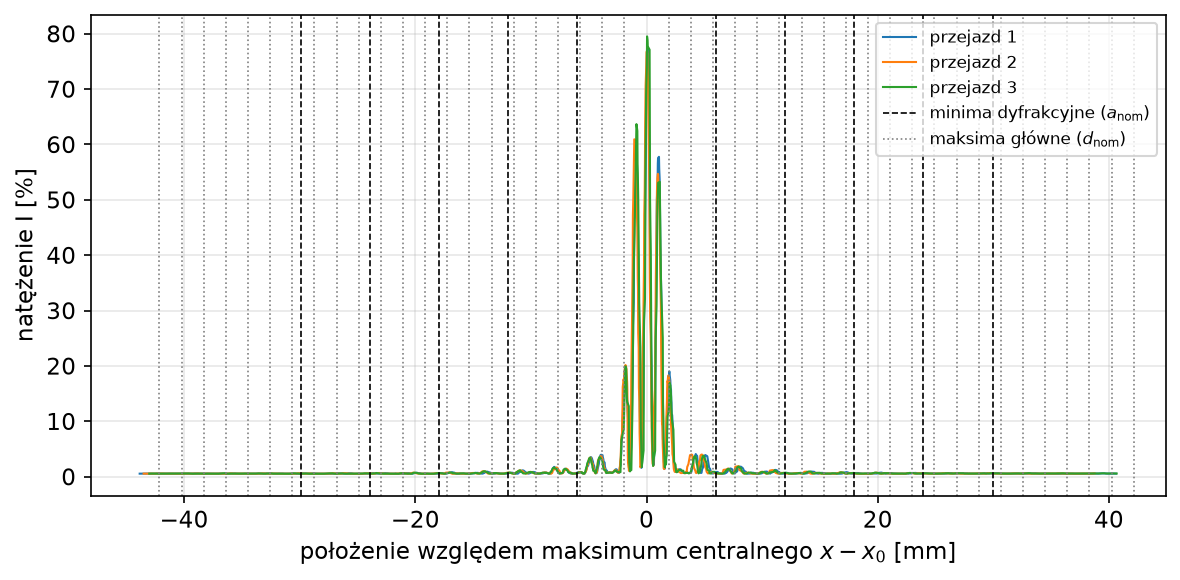

In [12]:
_ = podglad(B3_g, meta_B3_g, krok=0.02)

### B — dwie szczeliny, $a = 0,08$ mm, $d = 0,50$ mm (zielony)

— przejazd 1/3


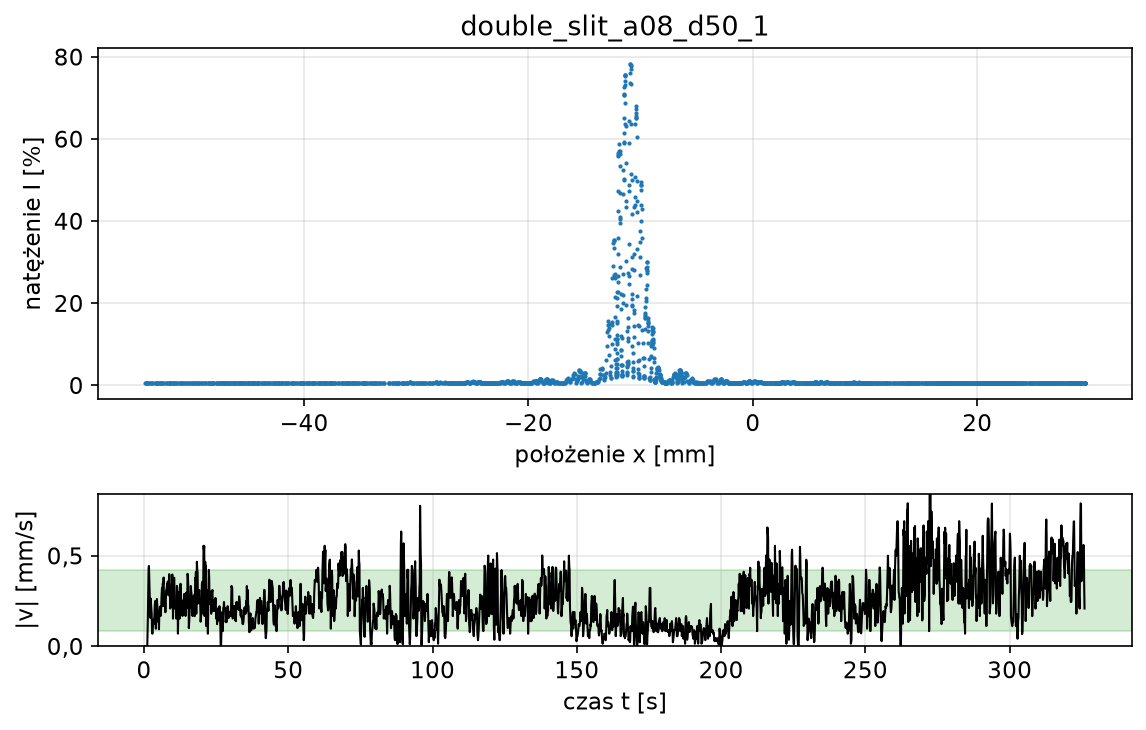

zapisano green/double_slit_a08_d50_1.csv (2289 pkt, x: -54.1 … 29.6 mm, zakończono zawrotem; odcięto 17 pkt ustawiania/powrotu)
— przejazd 2/3: jechać z powrotem


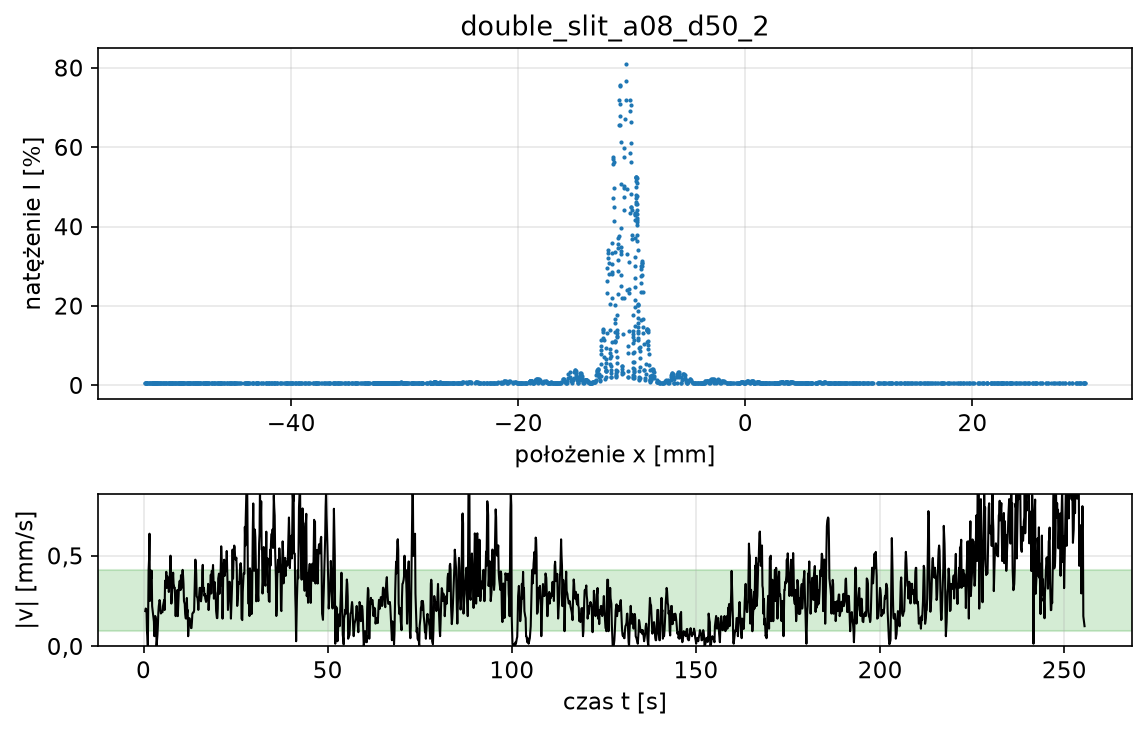

zapisano green/double_slit_a08_d50_2.csv (1794 pkt, x: -52.9 … 29.9 mm, zakończono zawrotem; odcięto 13 pkt ustawiania/powrotu)
— przejazd 3/3: jechać z powrotem


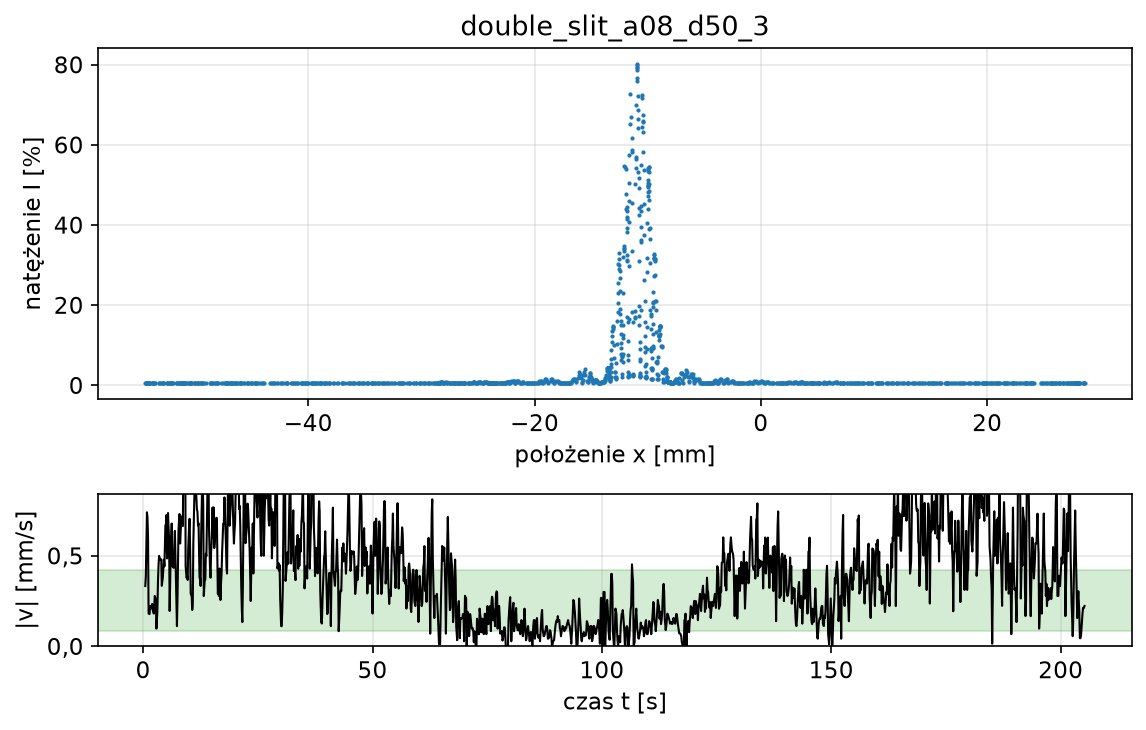

zapisano green/double_slit_a08_d50_3.csv (1441 pkt, x: -54.4 … 28.6 mm, zakończono zawrotem; odcięto 6 pkt ustawiania/powrotu)


In [13]:
meta_B4_g = dict(part='double_slit', N=2, a_nom=0.08, d_nom=0.5, D=D_UST, u_D=U_D,
                 aperture='', notes='')
B4_g = seria('double_slit_a08_d50', meta_B4_g, n=3)

[1] d ≈ λD/Δy = 0.9576 mm   (Δy ≈ 0.50 mm, orientacyjnie)
[2] d ≈ λD/Δy = 0.9975 mm   (Δy ≈ 0.48 mm, orientacyjnie)
[3] d ≈ λD/Δy = 0.9034 mm   (Δy ≈ 0.53 mm, orientacyjnie)
d: średnia z 3 przejazdów = 0.9528 mm, rozrzut σ = 0.0472 mm


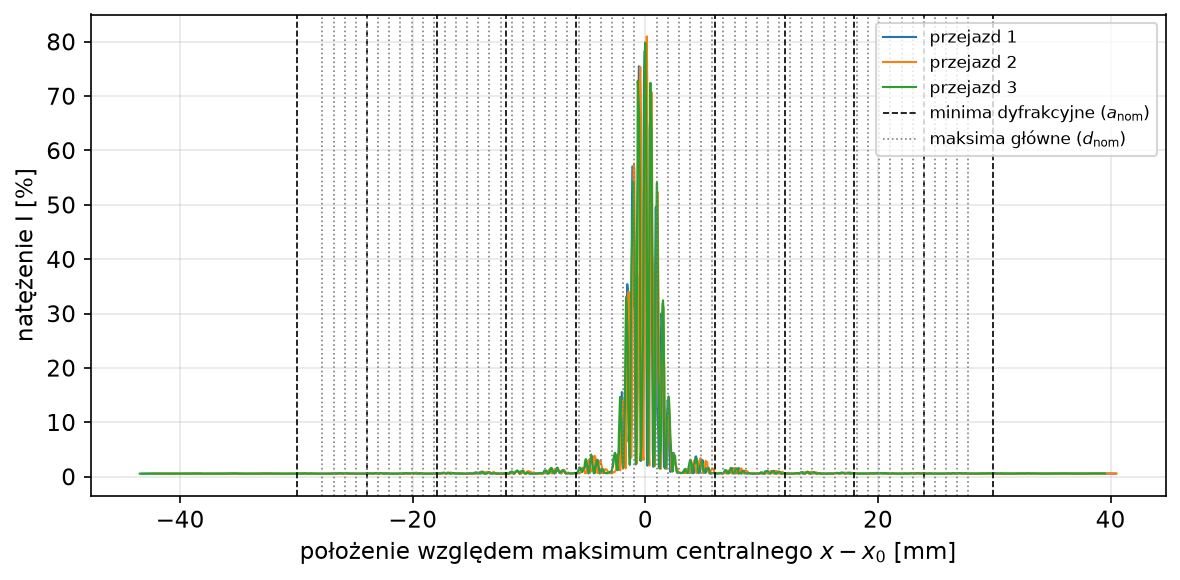

In [14]:
_ = podglad(B4_g, meta_B4_g, krok=0.02)

### C — $N = 4$ szczeliny (zielony)

— przejazd 1/3


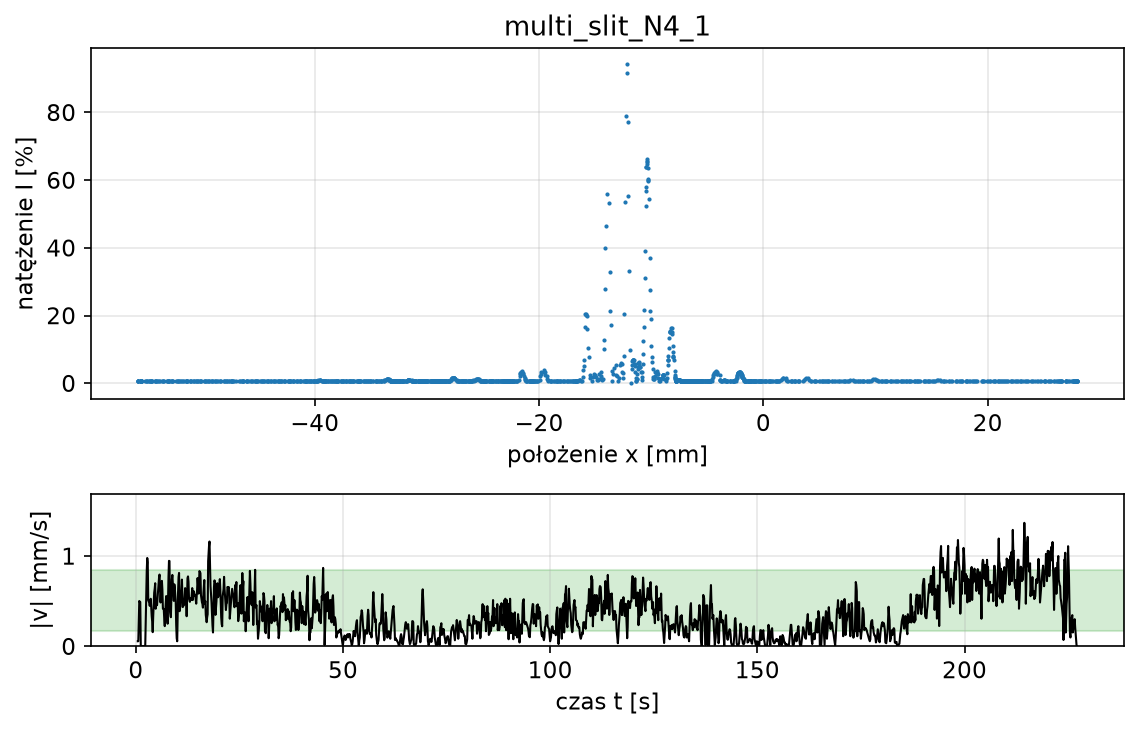

zapisano green/multi_slit_N4_1.csv (1600 pkt, x: -55.8 … 28.0 mm, zakończono zawrotem; odcięto 12 pkt ustawiania/powrotu)
— przejazd 2/3: jechać z powrotem


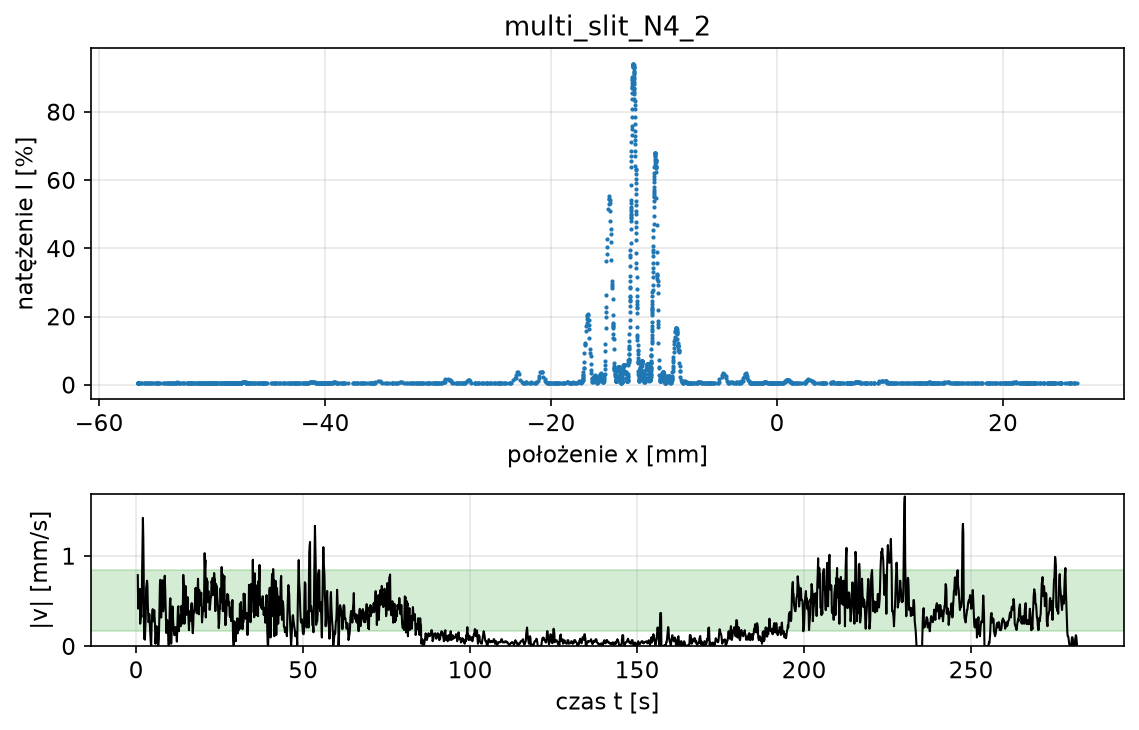

zapisano green/multi_slit_N4_2.csv (1984 pkt, x: -56.6 … 26.5 mm, zakończono zawrotem; odcięto 37 pkt ustawiania/powrotu)
— przejazd 3/3: jechać z powrotem


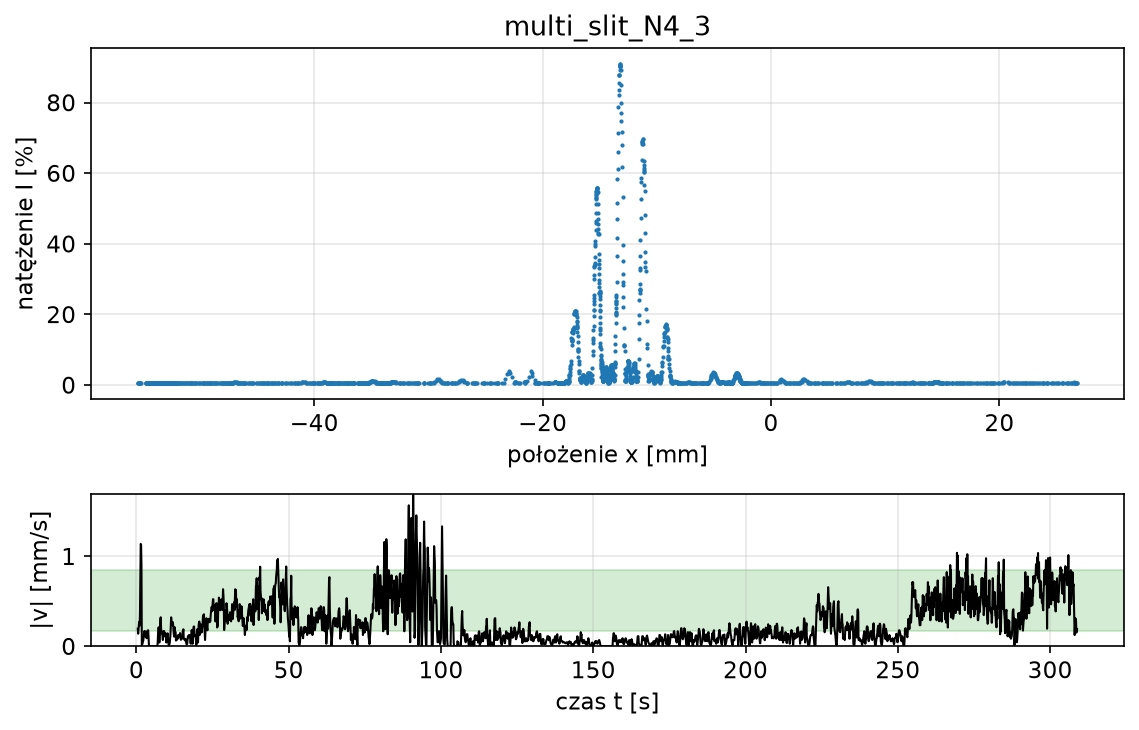

zapisano green/multi_slit_N4_3.csv (2182 pkt, x: -55.5 … 26.8 mm, zakończono zawrotem; odcięto 6 pkt ustawiania/powrotu)


In [15]:
meta_C4_g = dict(part='multi_slit', N=4, a_nom=0.04, d_nom=0.125, D=D_UST, u_D=U_D,
                 aperture='', notes='')
C4_g = seria('multi_slit_N4', meta_C4_g, n=3)

[1] d ≈ λD/Δy = 0.2588 mm   (Δy ≈ 1.85 mm, orientacyjnie)
[1] maksima poboczne między maksimami głównymi: ← 2 / 5 →  (oczekiwane N − 2 = 2)
[2] d ≈ λD/Δy = 0.2481 mm   (Δy ≈ 1.93 mm, orientacyjnie)
[2] maksima poboczne między maksimami głównymi: ← 4 / 5 →  (oczekiwane N − 2 = 2)
[3] d ≈ λD/Δy = 0.2382 mm   (Δy ≈ 2.01 mm, orientacyjnie)
[3] maksima poboczne między maksimami głównymi: ← 5 / 5 →  (oczekiwane N − 2 = 2)
d: średnia z 3 przejazdów = 0.2484 mm, rozrzut σ = 0.0103 mm


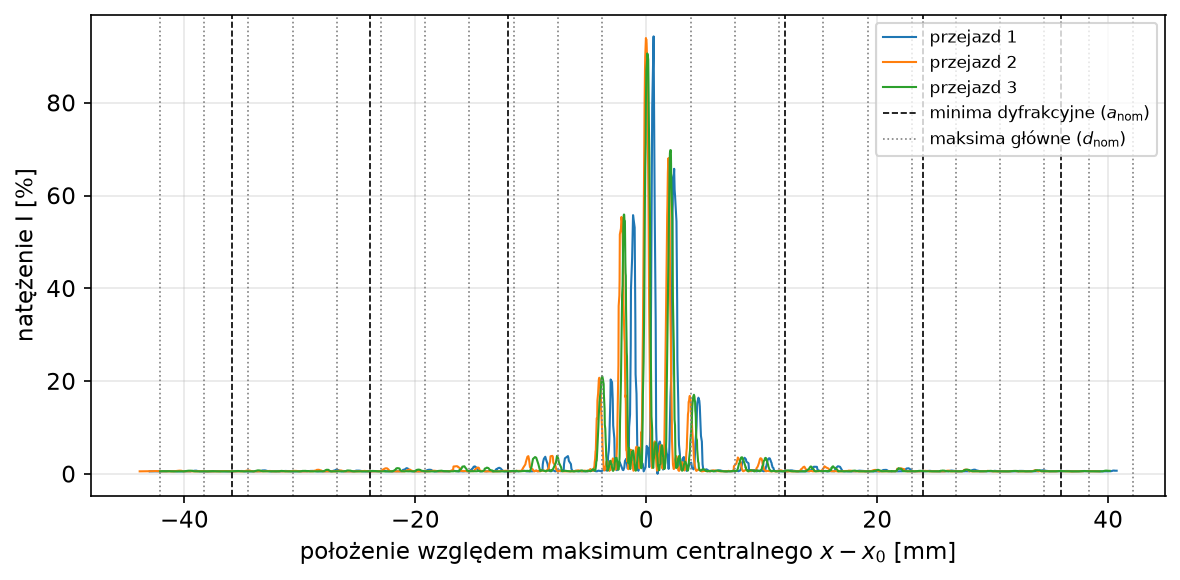

In [16]:
_ = podglad(C4_g, meta_C4_g, krok=0.02)

## Plan analizy (do `bodo.ipynb`, wg Dodatku B)

1. **Pojedyncza szczelina** — szerokość $a$ dwiema metodami:
   - dopasowanie $I = A\left[\dfrac{\sin(B(x-C))}{B(x-C)}\right]^2$ (+ stałe tło), $A$ — natężenie maksimum,
     $C$ — położenie środka, $B = \dfrac{\pi a}{\lambda D}$, stąd $a = \dfrac{B\lambda D}{\pi}$; wartość startowa $B$
     z $a$ producenta;
   - regresja liniowa położeń minimów od ich rzędu, $y_m = \dfrac{\lambda D}{a}\,m$; z nachylenia $a$.
2. **Dwie szczeliny** — regresje liniowe $y_\text{dyf} = \dfrac{\lambda D}{a}\,m$ (minima obwiedni) i
   $y_\text{int} = \dfrac{\lambda D}{d}\,m'$ (maksima interferencyjne); z nachyleń $a$ i $d$.
3. **$N$ szczelin** — opis zmian maksimów głównych i pobocznych. Dodatkowo: po znormalizowaniu danych do $[0, 1]$
   porównać obwiednię dyfrakcyjną zestawów z rozkładem pojedynczych szczelin $a = 0{,}04$ i $0{,}08$ mm.
4. **Powtórzenia** — każdy układ szczelin zmierzono 3 razy (przejazdy w obu kierunkach). Wyznaczyć $a$, $d$
   z każdego przejazdu osobno; wynik końcowy jako średnia, a rozrzut między przejazdami (niepewność typu A,
   $\sigma/\sqrt{3}$) porównać z niepewnością z dopasowania. Różnica między przejazdami → i ← wskazywałaby
   na luz (histerezę) mechanizmu przesuwu lub opóźnienie odczytu $I$ względem $x$.
5. **Laser czerwony a zielony** — wszystkie położenia skalują się jak $\lambda$, więc dla tej samej szczeliny
   $y^\text{green}_m / y^\text{red}_m = \lambda_\text{green}/\lambda_\text{red}$ ($\approx 0{,}80$ dla 515 / 640 nm).
   Szerokości $a$ i odległości $d$ z obu sesji powinny być zgodne (test $|a_1 - a_2|/\sqrt{u_1^2 + u_2^2}$).
   Jeśli jedna długość fali nie jest pewna, można ją wyznaczyć z drugiej: $\lambda_2 = \lambda_1\,y^{(2)}_m / y^{(1)}_m$ —
   to samo $a$, $D$ w obu sesjach, więc $D$ i $a$ się skracają.
6. **Zmiana $D$ (część D)** — $a$ z każdego z trzech przejazdów (obie metody) porównać z A1 ($D = 900$ mm).
   Nachylenie $y_m$ od $m$ jest równe $\lambda D/a$, więc dla czterech odległości (D1–D3 i A1) zależność
   nachylenia od $D$ powinna być prostą przez zero o współczynniku $\lambda/a$ — z niej $a$ niezależne od
   przesunięcia zera skali ławy.
7. **Zmiana apertury (część E)** — oba przejazdy porównać z A2 (czerwony, zwykła apertura): $I_\text{max}$, głębokość minimów
   ($I_\text{min}/I_\text{max}$) i położenia minimów; te ostatnie powinny się zgadzać w granicach niepewności.

## Podsumowanie i rozłączenie

Rejestry skanów obu laserów z parametrami układu — przepisać $D$, $u_D$ i opis szczelin do procedury w sprawozdaniu.

In [ ]:
for laser in LASERY:
    plik = Path(laser) / (('sim_' if SIM else '') + 'scans.csv')
    if plik.exists():
        print(f'=== {laser} ===')
        print(pd.read_csv(plik).to_string(index=False))

In [ ]:
skaner.rozlacz()